In [1]:
# pip install yfinance pandas numpy

In [2]:
# pip install plotly

In [3]:
# pip install xlrd

In [4]:
# pip install seaborn

In [5]:
# pip install xgboost

In [6]:
# !{sys.executable} -m pip install pandas-datareader

In [1]:
# pip install "kaleido==0.2.1"

Note: you may need to restart the kernel to use updated packages.


In [178]:
# LIBRERÍAS
import yfinance as yf
import pandas as pd
import plotly.express as px
import requests
import pandas as pd
from io import StringIO
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import MinMaxScaler, RobustScaler
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import QuantileTransformer
import pandas_datareader.data as web
import datetime
from sklearn.decomposition import PCA
import sys
import plotly.io as pio

In [180]:
pio.renderers.default = "png"

## 1. MERCADO CRIPTO

### 1.1 EXTRACCIÓN DE VARIABLES DEL PROYECTO

In [184]:
# LIBRERÍA DE YAHOO FINANCE
# vamos a descargar top 10 criptomonedas en capitalización desde 2018 (exceptuando stable coins)
btc = yf.download("BTC-USD", start = "2018-01-01", end = "2026-01-01") # bitcoin
eth = yf.download("ETH-USD", start = "2018-01-01", end = "2026-01-01") # ethereum
xrp = yf.download("XRP-USD", start = "2018-01-01", end = "2026-01-01") #ripple
bnb = yf.download("BNB-USD", start = "2018-01-01", end = "2026-01-01") # binance coin
sol = yf.download("SOL-USD", start = "2018-01-01", end = "2026-01-01") # solana
trx = yf.download("TRX-USD", start = "2018-01-01", end = "2026-01-01") # tron
doge = yf.download("DOGE-USD", start = "2018-01-01", end = "2026-01-01") # dogecoin
bch = yf.download("BCH-USD", start = "2018-01-01", end = "2026-01-01") # bitcoin cash
ada = yf.download("ADA-USD", start = "2018-01-01", end = "2026-01-01") # cardano
leo = yf.download("LEO-USD", start = "2018-01-01", end = "2026-01-01") # unus sed leo

# vamos a descargar ahora el oro y el S&P 500 ya que pueden tener relación con el mercado cripto
gold = yf.download("GC=F", start = "2018-01-01", end = "2026-01-01")
sp500 = yf.download("^GSPC", start="2018-01-01", end="2026-01-01")

# market cap alcoins (resto de criptos menos bitcoin) y market cap de bitcoin, sacada de https://coin.dance/stats/marketcaphistorical, de
# aqui tengo que sacar la dominancia de bitcoin
market_cap = pd.read_csv("../data/coin-dance-market-cap-historical.csv")


#encuesta de sentimiento sobre el mercado
#sacado de: AAII (American Asociation of Individual Investors). Se han eliminado cosas del archivo original directamente en el excel
survey_sentiments = pd.read_excel("../data/sentiment.xls")

# google trends, sacamos palabra "buy bitcoin" (busqueda web) y "crypto" (busqueda youtube)
# estos archivos están en valores relativos y divididos en dos periodos 01/01/2018-31/12/2022 y 01/01/2022-31/12/2025
# de forma que habrá que tratarlos
gt_btc_1 = pd.read_csv("../data/google_trends/buy-bitcoin-2018-2022.csv")
gt_btc_2 = pd.read_csv("../data/google_trends/buy-bitcoin-2022-2025.csv")
gt_crypto_1 = pd.read_csv("../data/google_trends/crypto-2018-2022.csv")
gt_crypto_2 = pd.read_csv("../data/google_trends/crypto-2022-2025.csv")

# fear & greed index
# sacamos el indicador de la API de alternative.me
# limit=0 (registro histórico) format=csv date_format=us (MM-DD-YYYY)
url = "https://api.alternative.me/fng/?limit=0&format=csv&date_format=us"
response = requests.get(url) # petición a la API
text = response.text # copiamos todo el texto de la API
start = text.find("fng_value") # buscamos fng_value para empezar a copiar desde ahí
clean_text = text[start:]
# Convertir a DataFrame
fng = pd.read_csv(StringIO(clean_text)) # convertimos el string en un archivo



[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


### 1.2 ESTANDARIZACIÓN DE DATOS

In [187]:
# TOP 10 CRIPTOMONEDAS. 
# quitamos multiindex y quitamos el "name" ya que que es el "Price" se deduce
top_10 = [btc,eth,xrp,bnb,sol,trx,doge,bch,ada,leo]
for i in top_10:
  i.columns = i.columns.get_level_values(0)
  i.columns.name = None
  i.index = pd.to_datetime(i.index, format="%Y-%m-%d")

# solo queremos de febrero de 2018 a diciembre de 2025
btc = btc.loc["2018-02-01":"2025-12-31"]
eth = eth.loc["2018-02-01":"2025-12-31"]
xrp = xrp.loc["2018-02-01":"2025-12-31"]
bnb = bnb.loc["2018-02-01":"2025-12-31"]
sol = sol.loc["2018-02-01":"2025-12-31"]
trx = trx.loc["2018-02-01":"2025-12-31"]
doge = doge.loc["2018-02-01":"2025-12-31"]
bch = bch.loc["2018-02-01":"2025-12-31"]
ada = ada.loc["2018-02-01":"2025-12-31"]
leo = leo.loc["2018-02-01":"2025-12-31"]

In [189]:
btc.head()

,Close,High,Low,Open,Volume
Date,,,,,
2018-02-01,9170.540039,10288.799805,8812.280273,10237.299805,9959400448
2018-02-02,8830.750000,9142.280273,7796.490234,9142.280273,12726899712
2018-02-03,9174.910156,9430.750000,8251.629883,8852.120117,7263790080
2018-02-04,8277.009766,9334.870117,8031.220215,9175.700195,7073549824
2018-02-05,6955.270020,8364.839844,6756.680176,8270.540039,9285289984


In [191]:
# GOLD Y S&P500
# exactamente lo mismo que en el anterior
gold.columns = gold.columns.get_level_values(0)
gold.columns.name = None
gold.index = pd.to_datetime(gold.index, format="%Y-%m-%d")
sp500.columns = sp500.columns.get_level_values(0)
sp500.columns.name = None
sp500.index = pd.to_datetime(sp500.index, format="%Y-%m-%d")
# filtramos solo las fechas que queremos
gold = gold.loc["2018-02-01":"2025-12-31"]
sp500 = sp500.loc["2018-02-01":"2025-12-31"]


In [193]:
sp500.head()

,Close,High,Low,Open,Volume
Date,,,,,
2018-02-01,2821.979980,2835.959961,2812.699951,2816.449951,3977380000
2018-02-02,2762.129883,2808.919922,2759.969971,2808.919922,4340220000
2018-02-05,2648.939941,2763.389893,2638.169922,2741.060059,5310840000
2018-02-06,2695.139893,2701.040039,2593.070068,2614.780029,5917350000
2018-02-07,2681.659912,2727.669922,2681.330078,2690.949951,4646300000


In [195]:
#MARKET CAP ALTOCOINS Y BITCOIN
market_cap = market_cap.rename(columns={"Label":"Date"}) # Cambiamos el nombre de la columna
market_cap = market_cap.set_index("Date") # hacemos la variable "Date" índice
# La hacemos "datetime"
market_cap.index = pd.to_datetime(market_cap.index, format="%Y-%m-%d")
market_cap = market_cap.loc["01-01-2018":]
market_cap = market_cap.rename(columns={"Altcoin Market Cap" : "altcoin_market_cap",
                                        "Bitcoin Market Cap" : "bitcoin_market_cap" })
# filtramos fechas
market_cap = market_cap.loc["2018-02-01":"2025-12-31"]

In [197]:
market_cap.head()

,altcoin_market_cap,bitcoin_market_cap
Date,,
2018-02-01,2.446377e+11,1.446009e+11
2018-02-02,2.496134e+11,1.457697e+11
2018-02-03,2.752540e+11,1.554427e+11
2018-02-04,2.331412e+11,1.359359e+11
2018-02-05,1.653089e+11,1.026869e+11


In [199]:
# FEAR AND GREED INDEX
fng = fng.rename(columns={"fng_value":"Date"}) # cambiamos nombre de columna
fng = fng.set_index("Date") # ponemos columna como índice
fng = fng.loc[:"02-01-2018"] # quitamos caracteres que no necesitamos
fng.index = pd.to_datetime(fng.index, format="%m-%d-%Y") # pasamos a DateTime
fng = fng.rename(columns={"fng_classification":"fng_index","date":"fng_class"}) # cambiamos nombres a las columnas
fng = fng.sort_index() # ordenamos en el mismo sentido que los demás
fng = fng.loc["2018-02-01":"2025-12-31"] # filtramos fechas

In [201]:
fng.tail()

,fng_index,fng_class
Date,,
2025-12-27,23.0,Extreme Fear
2025-12-28,24.0,Extreme Fear
2025-12-29,24.0,Extreme Fear
2025-12-30,23.0,Extreme Fear
2025-12-31,21.0,Extreme Fear


In [203]:
#Encuesta de sentimientos del mercado
# de este archivo se eliminaron cosas directamente desde el excel
survey_sentiments = survey_sentiments.rename(columns= {"Unnamed: 0" : "Reported Date", # cambiamos nombres de las columnas
                                                       "Unnamed: 1" : "Bullish",
                                                       "Unnamed: 2" : "Neutral",
                                                       "Unnamed: 3" : "Bearish",
                                                       "Unnamed: 4" : "Total"})

survey_sentiments = survey_sentiments.iloc[:, 0:5] # dejamos solo las que nos interesan
survey_sentiments = survey_sentiments.iloc[2:] # quitamos las dos primeras filas ya que eran parte del nombre de las columnas
survey_sentiments = survey_sentiments.rename(columns={"Reported Date":"Date"})
survey_sentiments["Date"] = pd.to_datetime(survey_sentiments["Date"])
survey_sentiments = survey_sentiments.set_index("Date") # hacemos indice a "Reported Date"
survey_sentiments = survey_sentiments.resample('D').ffill() # lo volvemos diario

survey_sentiments = survey_sentiments.loc["2018-02-01":"2025-12-31"]



In [205]:
survey_sentiments.head(7)

,Bullish,Neutral,Bearish,Total
Date,,,,
2018-02-01,0.447712,0.264706,0.287582,1
2018-02-02,0.447712,0.264706,0.287582,1
2018-02-03,0.447712,0.264706,0.287582,1
2018-02-04,0.447712,0.264706,0.287582,1
2018-02-05,0.447712,0.264706,0.287582,1
2018-02-06,0.447712,0.264706,0.287582,1
2018-02-07,0.447712,0.264706,0.287582,1


In [207]:
# Variables extraidas de google trends
# estan divididos en dos partes ya que si no google trends ponia periodos mensuales, por lo que tuve que poner de
# 2018 a 2022 y de 2022 a 2026, se tiene el 2022 en comun para escalar los datos ya que no están en valores absolutos 
# si no relativos
gt_btc_1 = gt_btc_1.iloc[1:]
gt_btc_2 = gt_btc_2.iloc[1:] # eliminamos todas las filas 0 de los dataframe ya que no hay 
gt_crypto_1 = gt_crypto_1.iloc[1:] # información relevante
gt_crypto_2 = gt_crypto_2.iloc[1:]
gt_btc_1 = gt_btc_1.rename(columns={"Categoría: Todas las categorías":"btc_busqueda"})
gt_btc_2 = gt_btc_2.rename(columns={"Categoría: Todas las categorías":"btc_busqueda"}) # cambiamos nombres
gt_crypto_1 = gt_crypto_1.rename(columns={"Categoría: Todas las categorías":"crypto_busqueda"})
gt_crypto_2 = gt_crypto_2.rename(columns={"Categoría: Todas las categorías":"crypto_busqueda"})

gt_features = [gt_btc_1, gt_btc_2, gt_crypto_1, gt_crypto_2]
for i in gt_features:
  i.index.name = "Date" # ponemos el nombre del index en todos
  i.index = pd.to_datetime(i.index)
  

#pasamos la columna a numérico para poder reescalarla
gt_btc_1["btc_busqueda"] = pd.to_numeric(gt_btc_1["btc_busqueda"], errors='coerce')
gt_btc_2["btc_busqueda"] = pd.to_numeric(gt_btc_2["btc_busqueda"], errors='coerce')
gt_crypto_1["crypto_busqueda"] = pd.to_numeric(gt_crypto_1["crypto_busqueda"], errors='coerce')
gt_crypto_2["crypto_busqueda"] = pd.to_numeric(gt_crypto_2["crypto_busqueda"], errors='coerce')

#escalamos
factor_btc = gt_btc_1["btc_busqueda"].iloc[-1] / gt_btc_2["btc_busqueda"].iloc[0] # Factor de empalme 1
factor_crypto = gt_crypto_1["crypto_busqueda"].iloc[-1] / gt_crypto_2["crypto_busqueda"].iloc[0] # Factor de empalme 1
gt_btc_2_scaled = gt_btc_2["btc_busqueda"] * factor_btc # hacemos factor para empalmar
gt_crypto_2_scaled = gt_crypto_2["crypto_busqueda"] * factor_crypto

#concatenamos
gt_btc = pd.concat([gt_btc_1["btc_busqueda"],gt_btc_2_scaled])
gt_crypto = pd.concat([gt_crypto_1["crypto_busqueda"],gt_crypto_2_scaled])

#convertimos a dataframe
gt_btc_df = gt_btc.to_frame(name="btc_busqueda")
gt_crypto_df = gt_crypto.to_frame(name="crypto_busqueda")
gt_btc_df.index = pd.to_datetime(gt_btc_df.index, format="%d-%m-%Y")
gt_btc_df = gt_btc_df[~gt_btc_df.index.duplicated(keep='first')] # borramos los duplicados 
gt_btc_df = gt_btc_df.resample('D').ffill() #convertimos en diario el semanal
gt_crypto_df.index = pd.to_datetime(gt_crypto_df.index, format="%d-%m-%Y")
gt_crypto_df = gt_crypto_df[~gt_crypto_df.index.duplicated(keep='first')]
gt_crypto_df = gt_crypto_df.resample('D').ffill()

#filtramos fechas
gt_crypto_df = gt_crypto_df.loc["2018-02-01":"2025-12-31"]
gt_btc_df = gt_btc_df.loc["2018-02-01":"2025-12-31"]
    

In [209]:
gt_btc_df.head()

,btc_busqueda
Date,
2018-02-01,41.0
2018-02-02,41.0
2018-02-03,41.0
2018-02-04,40.0
2018-02-05,40.0


In [211]:
# Para realizar el análisis exploratorio tendré que concatenar todo en un mismo dataframe

# En primer lugar vamos a concatenar los precios "Close" de cada cripto para ver su evolución
top_10 = [btc,eth,xrp,bnb,sol,trx,doge,bch,ada,leo]
prices = [df["Close"] for df in top_10]
df_prices = pd.concat(prices, axis = 1)



# Volumen acumulado diario
volumen = [df["Volume"] for df in top_10]
volumen_acum = pd.concat(volumen, axis = 1).sum(axis = 1)

# Añadiremos también la volatilidad media diaria de todas las criptos
volatilidad = [(df["High"] - df["Low"]) / df["Close"] for df in top_10]
volatilidad_df = pd.concat(volatilidad, axis = 1)
volatilidad_df.columns = ['BTC','ETH','XRP','BNB','SOL','TRX','DOGE','BCH','ADA','LEO']
volatilidad_df = volatilidad_df.mean(axis = 1)

# Añadimos dominancia de bitcoin que va a ser la capitalizacion de bitcoin entre la capitalizacion total (bitcoin + altcoins)
# y lo multiplicamos por 100 para que sea porcentual
dominancia_bitcoin = (market_cap["bitcoin_market_cap"] / (market_cap["altcoin_market_cap"] + market_cap["bitcoin_market_cap"])) * 100


# Añadimos también el sentimiento alcista y el bajista de la encuesta de la AAII
# y las variables de google trends.
# Por ultimo se añadirán la variable target

df = pd.concat([df_prices,
                sp500["Close"],
                gold["Close"],
                volumen_acum, 
                volatilidad_df,
                dominancia_bitcoin,
                survey_sentiments["Bullish"],
                survey_sentiments["Bearish"],
                gt_btc_df["btc_busqueda"],
                gt_crypto_df["crypto_busqueda"],
                fng["fng_index"]], 
                 axis = 1)

df.columns = ["BTC",
              "ETH",
              "XRP",
              "BNB",
              "SOL",
              "TRX",
              "DOGE",
              "BCH",
              "ADA",
              "LEO",
              "SP500",
              "GOLD",
              "volumen_acum_diario",
              "volatilidad_med_diaria",
              "dominancia_bitcoin",
              "sent_alcista",
              "sent_bajista",
              "btc_busqueda",
              "crypto_busqueda",
              "f&g index"
                    ]







## 1.3 ANALISIS EXPLORATORIO

### 1.3.2 ANALISIS ESTRUCTURAL

In [215]:
df.head()

,BTC,ETH,XRP,BNB,SOL,TRX,DOGE,BCH,ADA,LEO,SP500,GOLD,volumen_acum_diario,volatilidad_med_diaria,dominancia_bitcoin,sent_alcista,sent_bajista,btc_busqueda,crypto_busqueda,f&g index
Date,,,,,,,,,,,,,,,,,,,,
2018-02-01,9170.540039,1036.790039,0.962530,9.51584,NaN,0.046227,0.005029,1274.349976,0.421672,NaN,2821.979980,1344.300049,1.829553e+10,0.245634,37.149679,0.447712,0.287582,41.0,16.0,30.0
2018-02-02,8830.750000,915.784973,0.884784,9.65229,NaN,0.040799,0.004475,1191.140015,0.390534,NaN,2762.129883,1333.699951,2.579074e+10,0.315503,36.867967,0.447712,0.287582,41.0,16.0,15.0
2018-02-03,9174.910156,964.018982,0.924043,9.74968,NaN,0.044472,0.005164,1272.500000,0.438836,NaN,NaN,NaN,1.467033e+10,0.224081,36.090989,0.447712,0.287582,41.0,16.0,40.0
2018-02-04,8277.009766,834.682007,0.815703,8.45864,NaN,0.037933,0.004399,1165.380005,0.379303,NaN,NaN,NaN,1.296530e+10,0.213996,36.831309,0.447712,0.287582,40.0,15.0,24.0
2018-02-05,6955.270020,697.950989,0.691799,6.70503,NaN,0.030161,0.003533,887.413025,0.327371,NaN,2648.939941,1333.000000,1.630273e+10,0.301624,38.316608,0.447712,0.287582,40.0,15.0,11.0


In [217]:
# observamos que hay dos variables "object" por lo que tendremos que cambiarlas
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2891 entries, 2018-02-01 to 2025-12-31
Freq: D
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   BTC                     2891 non-null   float64
 1   ETH                     2891 non-null   float64
 2   XRP                     2891 non-null   float64
 3   BNB                     2891 non-null   float64
 4   SOL                     2092 non-null   float64
 5   TRX                     2891 non-null   float64
 6   DOGE                    2891 non-null   float64
 7   BCH                     2891 non-null   float64
 8   ADA                     2891 non-null   float64
 9   LEO                     2417 non-null   float64
 10  SP500                   1990 non-null   float64
 11  GOLD                    1993 non-null   float64
 12  volumen_acum_diario     2891 non-null   float64
 13  volatilidad_med_diaria  2891 non-null   float64
 14  dominancia_bit

In [219]:
# cambiamos las variables a float para poder analizarlas mejor
df["sent_alcista"] = pd.to_numeric(df["sent_alcista"], errors = "coerce")
df["sent_bajista"] = pd.to_numeric(df["sent_bajista"], errors = "coerce")
print("sent_alcista es de tipo:",df["sent_alcista"].dtype)
print("sent_bajista es de tipo:",df["sent_bajista"].dtype)
# arreglado

sent_alcista es de tipo: float64
sent_bajista es de tipo: float64


In [221]:
df.shape

(2891, 20)

In [223]:
df.describe()
# podemos ver como en "count" varias variables no tienen 2891 valores con lo que
# nos podrían indicar que hay nulos, por lo demás no se aprecia ningun problema
# no hay valores negativos ni valores atópicos

,BTC,ETH,XRP,BNB,SOL,TRX,DOGE,BCH,ADA,LEO,SP500,GOLD,volumen_acum_diario,volatilidad_med_diaria,dominancia_bitcoin,sent_alcista,sent_bajista,btc_busqueda,crypto_busqueda,f&g index
count,2891.000000,2891.000000,2891.000000,2891.000000,2092.000000,2891.000000,2891.000000,2891.000000,2891.000000,2417.000000,1990.000000,1993.000000,2.891000e+03,2891.000000,2890.000000,2891.000000,2891.000000,2888.000000,2888.000000,2887.000000
mean,37533.248951,1712.108484,0.783061,295.116329,86.246020,0.091986,0.095934,386.921027,0.507529,4.280889,4159.638998,1990.587405,5.608267e+10,0.060549,54.275543,0.349360,0.349903,21.472389,22.371893,47.159335
std,32287.797550,1303.347852,0.735269,275.194056,74.224736,0.085656,0.103536,251.663744,0.518500,2.762960,1170.660652,678.800367,4.291819e+10,0.040622,9.033959,0.087001,0.099670,14.574377,18.933544,21.703721
min,3236.761719,84.308296,0.139635,4.528650,0.515273,0.008792,0.001537,77.365776,0.023961,0.816223,2237.399902,1176.199951,4.818627e+09,0.009298,34.829151,0.158371,0.193084,9.000000,3.000000,5.000000
25%,9412.226562,337.177643,0.333457,20.274824,20.604224,0.026856,0.003140,225.356339,0.100545,1.506759,3024.419983,1557.400024,2.601409e+10,0.036228,45.787791,0.283951,0.264286,13.481481,6.000000,28.000000
50%,27702.349609,1677.846802,0.508034,271.951691,56.621611,0.065309,0.072046,325.606384,0.364899,3.767950,4094.559937,1835.400024,4.734573e+10,0.050227,54.846999,0.347418,0.335897,17.000000,18.666667,47.000000
75%,57626.300781,2719.970093,0.797332,524.071930,148.781307,0.114291,0.154733,499.303299,0.691584,5.842158,4782.907593,2042.199951,7.280620e+10,0.071684,61.476039,0.416327,0.421245,22.000000,32.000000,66.000000
max,124752.531250,4831.348633,3.555765,1310.214355,261.869751,0.425992,0.684777,1765.689941,2.968239,9.942690,6932.049805,4552.700195,4.170250e+11,0.699365,73.358926,0.569079,0.619171,99.000000,100.000000,95.000000


In [225]:
# hay cuatro variables que tienen bastantes valores nulos, 
# habrá que mirar por qué
df.isna().mean().sort_values(ascending = False)

SP500                     0.311657
GOLD                      0.310619
SOL                       0.276375
LEO                       0.163957
f&g index                 0.001384
btc_busqueda              0.001038
crypto_busqueda           0.001038
dominancia_bitcoin        0.000346
TRX                       0.000000
DOGE                      0.000000
BCH                       0.000000
ADA                       0.000000
BNB                       0.000000
ETH                       0.000000
XRP                       0.000000
volumen_acum_diario       0.000000
volatilidad_med_diaria    0.000000
sent_alcista              0.000000
sent_bajista              0.000000
BTC                       0.000000
dtype: float64

### 1.3.3 ANÁLISIS UNIVARIANTE

In [228]:
# funciones para el ánalisis univariante
def cuantitativa(df,columna):
    print(f"-----Estamos analizando la columna {columna} -----")
    print("Esta columna tiene",df[columna].isna().sum(),"nulos")
    print("Sus estadísticos descriptivos son:\n",df[columna].describe())

def grafico(df,columna):
    columna = px.line(df,x = df.index,
                      y = columna, title = f"Evolución de {columna} en el tiempo")
    columna.show()
    


#### BTC

-----Estamos analizando la columna BTC -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count      2891.000000
mean      37533.248951
std       32287.797550
min        3236.761719
25%        9412.226562
50%       27702.349609
75%       57626.300781
max      124752.531250
Name: BTC, dtype: float64


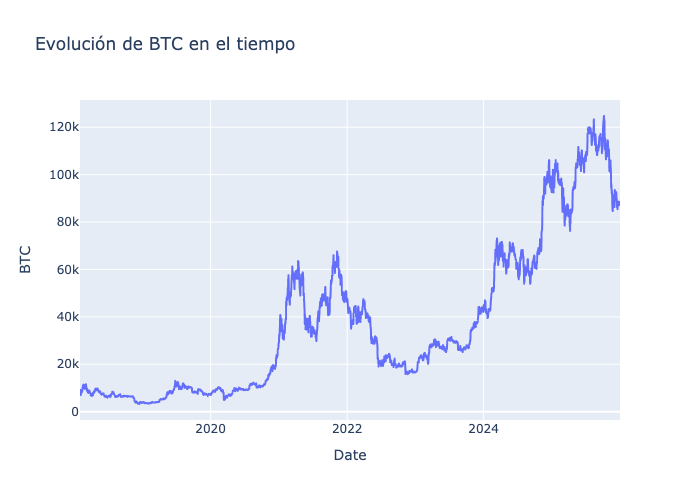

In [231]:
cuantitativa(df,"BTC")
grafico(df,"BTC")

#### ETH

-----Estamos analizando la columna ETH -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean     1712.108484
std      1303.347852
min        84.308296
25%       337.177643
50%      1677.846802
75%      2719.970093
max      4831.348633
Name: ETH, dtype: float64


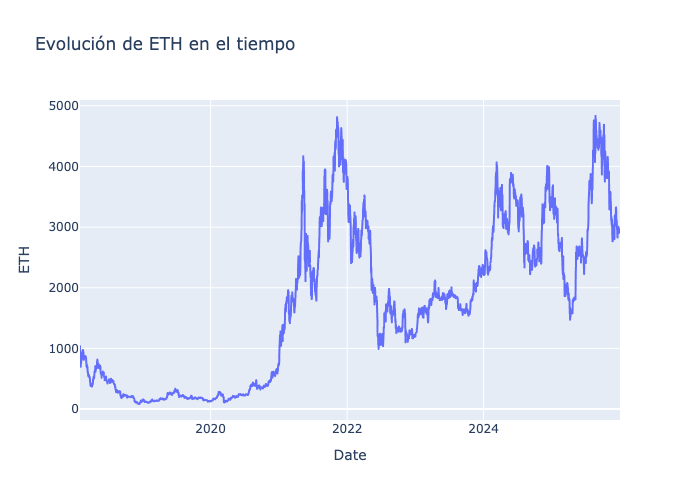

In [234]:
cuantitativa(df,"ETH")
grafico(df,"ETH")

#### XRP

-----Estamos analizando la columna XRP -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean        0.783061
std         0.735269
min         0.139635
25%         0.333457
50%         0.508034
75%         0.797332
max         3.555765
Name: XRP, dtype: float64


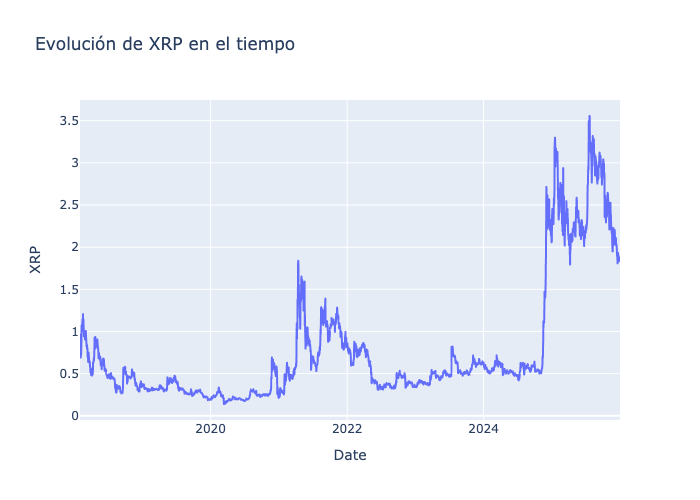

In [237]:
cuantitativa(df,"XRP")
grafico(df,"XRP")

#### SOL

-----Estamos analizando la columna SOL -----
Esta columna tiene 799 nulos
Sus estadísticos descriptivos son:
 count    2092.000000
mean       86.246020
std        74.224736
min         0.515273
25%        20.604224
50%        56.621611
75%       148.781307
max       261.869751
Name: SOL, dtype: float64


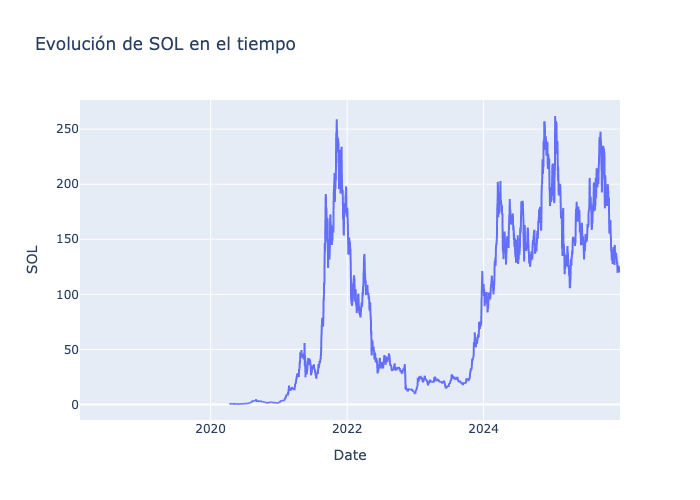

In [240]:
# esta columna tiene muchos nulos también, vamos a ver por qué es
cuantitativa(df,"SOL")
# se puede observar que no hay valores hasta abril de 2020, vamos a asegurarnos
# filtrando solo los valores que no sean nulos en esta columna
grafico(df,"SOL")

In [242]:
solana_sin_nulos = df["SOL"].dropna()
print(f"Tiene {solana_sin_nulos.isna().sum()} nulos")
solana_sin_nulos.head() 
# podemos comprobar aquí que la primera fecha es 4 de abril de 2020 y que después
# de esta fecha no vuelve a haber ningun nulo. Si buscamos en internet
# podremos comprobar que nuestra hipótesis es cierta y que Solana se lanzó en 
# marzo de 2020 

Tiene 0 nulos


Date
2020-04-10    0.951054
2020-04-11    0.776819
2020-04-12    0.882507
2020-04-13    0.777832
2020-04-14    0.661925
Freq: D, Name: SOL, dtype: float64

In [244]:
# Por lo tanto, la mejor opción será imputar 0 donde hay nulos
df["SOL"] = df["SOL"].fillna(0)

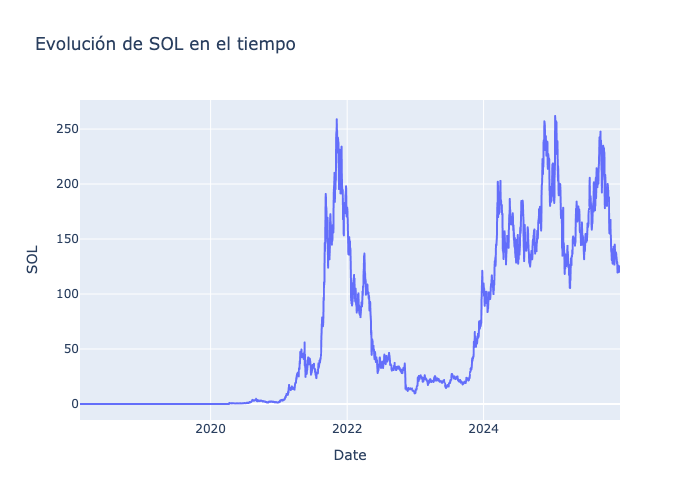

In [246]:
# arreglado
grafico(df,"SOL")

#### LEO

-----Estamos analizando la columna LEO -----
Esta columna tiene 474 nulos
Sus estadísticos descriptivos son:
 count    2417.000000
mean        4.280889
std         2.762960
min         0.816223
25%         1.506759
50%         3.767950
75%         5.842158
max         9.942690
Name: LEO, dtype: float64


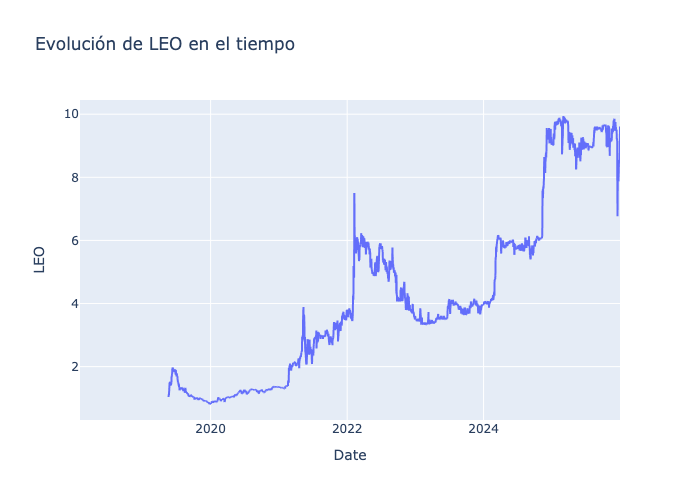

In [249]:
# igual que SOL tiene bastantes nulos
cuantitativa(df,"LEO")
# la primera fecha segun el gráfico es en mayo de 2019
grafico(df,"LEO")

In [251]:
# efectivamente, es el 21 de Mayo de 2019. Si buscamos en internet la moneda
# fue lanzada en esa fecha
leo_sin_nulos = df["LEO"].dropna()
print(f"Tiene {leo_sin_nulos.isna().sum()} nulos")
leo_sin_nulos.head()

Tiene 0 nulos


Date
2019-05-21    1.037136
2019-05-22    1.121754
2019-05-23    1.099154
2019-05-24    1.196215
2019-05-25    1.320464
Freq: D, Name: LEO, dtype: float64

In [253]:
# Imputamos 0 donde hay nulos
df["LEO"] = df["LEO"].fillna(0)

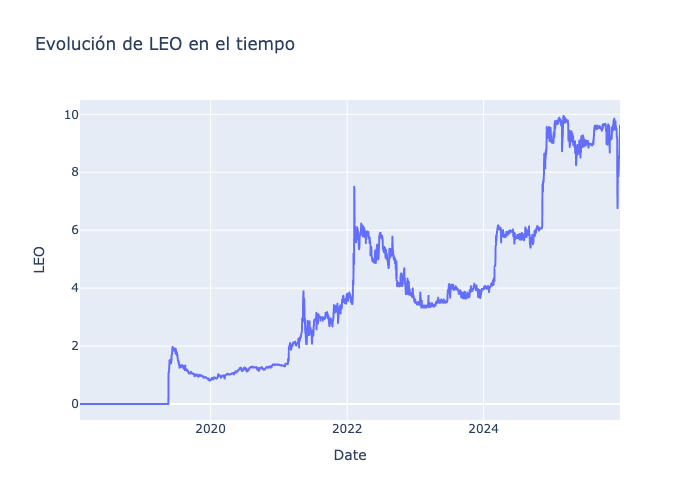

In [255]:
# arreglado
grafico(df,"LEO")

#### TRX

-----Estamos analizando la columna TRX -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean        0.091986
std         0.085656
min         0.008792
25%         0.026856
50%         0.065309
75%         0.114291
max         0.425992
Name: TRX, dtype: float64


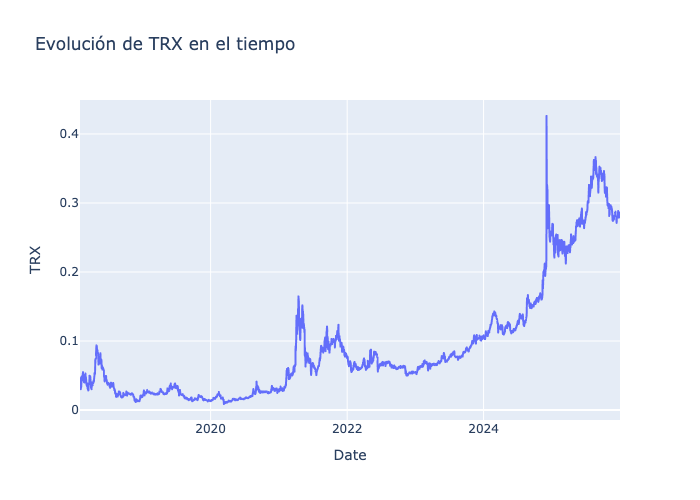

In [258]:
cuantitativa(df,"TRX")
grafico(df,"TRX")


#### DOGE

-----Estamos analizando la columna DOGE -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean        0.095934
std         0.103536
min         0.001537
25%         0.003140
50%         0.072046
75%         0.154733
max         0.684777
Name: DOGE, dtype: float64


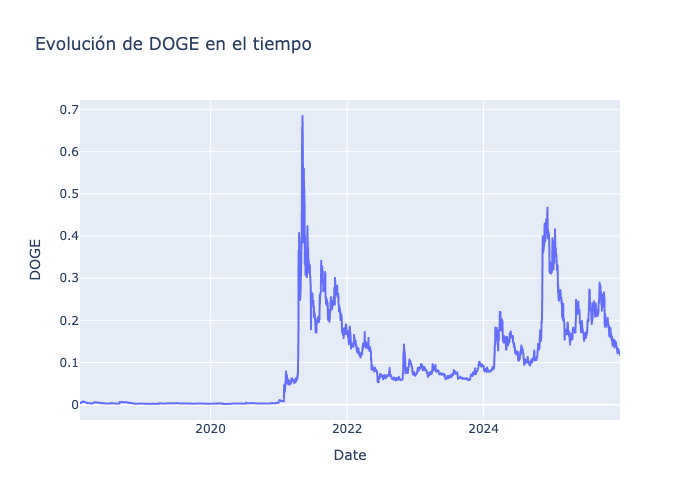

In [261]:
cuantitativa(df,"DOGE")
grafico(df,"DOGE")

#### BCH

-----Estamos analizando la columna BCH -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean      386.921027
std       251.663744
min        77.365776
25%       225.356339
50%       325.606384
75%       499.303299
max      1765.689941
Name: BCH, dtype: float64


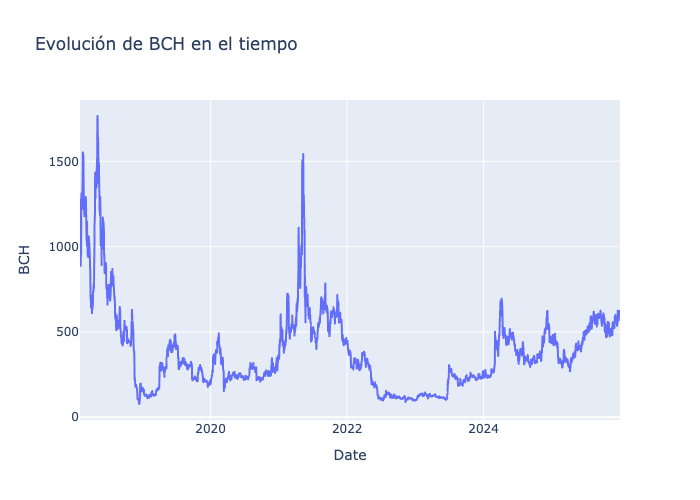

In [264]:
cuantitativa(df,"BCH")
grafico(df,"BCH")

#### ADA

-----Estamos analizando la columna ADA -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean        0.507529
std         0.518500
min         0.023961
25%         0.100545
50%         0.364899
75%         0.691584
max         2.968239
Name: ADA, dtype: float64


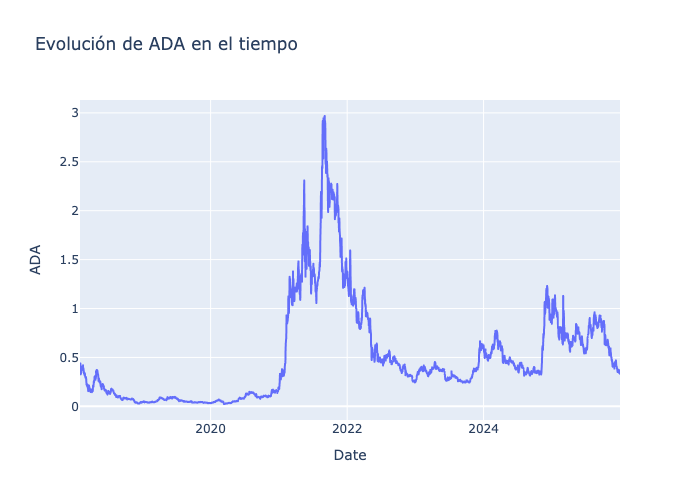

In [267]:
cuantitativa(df,"ADA")
grafico(df,"ADA")

#### BNB

-----Estamos analizando la columna BNB -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean      295.116329
std       275.194056
min         4.528650
25%        20.274824
50%       271.951691
75%       524.071930
max      1310.214355
Name: BNB, dtype: float64


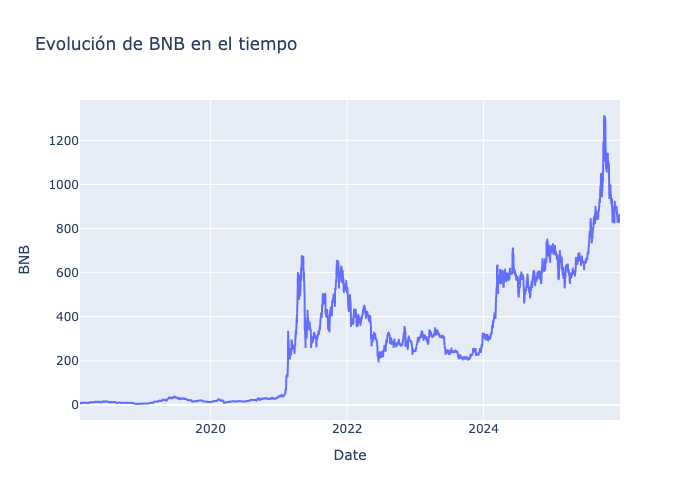

In [270]:
cuantitativa(df,"BNB")
grafico(df,"BNB")

#### SP500

-----Estamos analizando la columna SP500 -----
Esta columna tiene 901 nulos
Sus estadísticos descriptivos son:
 count    1990.000000
mean     4159.638998
std      1170.660652
min      2237.399902
25%      3024.419983
50%      4094.559937
75%      4782.907593
max      6932.049805
Name: SP500, dtype: float64


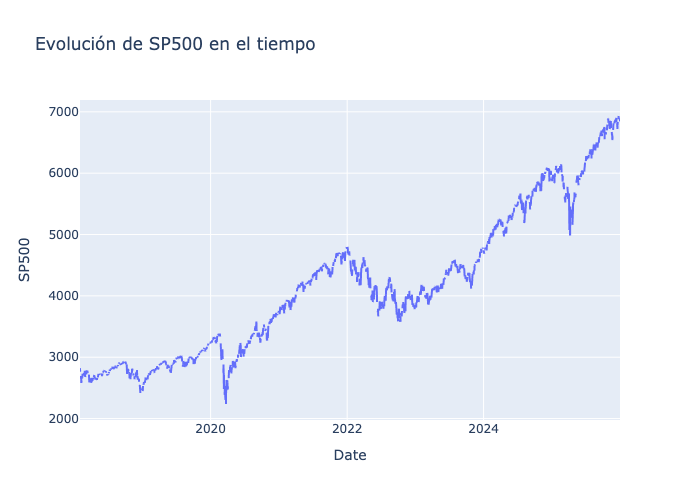

In [273]:
cuantitativa(df,"SP500") 
# tiene bastantes nulos, podría ser porque en 2018 no existía pero el S&P 500 existe desde hace más de 50 años
grafico(df,"SP500")

In [275]:
# como se puede apreciar aquí no es por que el s&p500 no existiese como va a 
# ser el caso de alguna cripto. Al analizar detenidamente podemos ver que se 
# producen nulos con un patrón. Cada 5 días y solo 2 nulos. Esto se debe a que
# sabados y domingos los mercados están cerrados con lo que se tendrá que imputar
# el valor del viernes
df["SP500"].head(20)

Date
2018-02-01    2821.979980
2018-02-02    2762.129883
2018-02-03            NaN
2018-02-04            NaN
2018-02-05    2648.939941
2018-02-06    2695.139893
2018-02-07    2681.659912
2018-02-08    2581.000000
2018-02-09    2619.550049
2018-02-10            NaN
2018-02-11            NaN
2018-02-12    2656.000000
2018-02-13    2662.939941
2018-02-14    2698.629883
2018-02-15    2731.199951
2018-02-16    2732.219971
2018-02-17            NaN
2018-02-18            NaN
2018-02-19            NaN
2018-02-20    2716.260010
Freq: D, Name: SP500, dtype: float64

In [277]:
# rellenamos los valores del sábado, domingo y festivos con el anterior
df["SP500"] = df["SP500"].ffill() 
df["SP500"].head(20)

Date
2018-02-01    2821.979980
2018-02-02    2762.129883
2018-02-03    2762.129883
2018-02-04    2762.129883
2018-02-05    2648.939941
2018-02-06    2695.139893
2018-02-07    2681.659912
2018-02-08    2581.000000
2018-02-09    2619.550049
2018-02-10    2619.550049
2018-02-11    2619.550049
2018-02-12    2656.000000
2018-02-13    2662.939941
2018-02-14    2698.629883
2018-02-15    2731.199951
2018-02-16    2732.219971
2018-02-17    2732.219971
2018-02-18    2732.219971
2018-02-19    2732.219971
2018-02-20    2716.260010
Freq: D, Name: SP500, dtype: float64

In [279]:
print("Los nulos en la columna SP500 son",df["SP500"].isna().sum())

Los nulos en la columna SP500 son 0


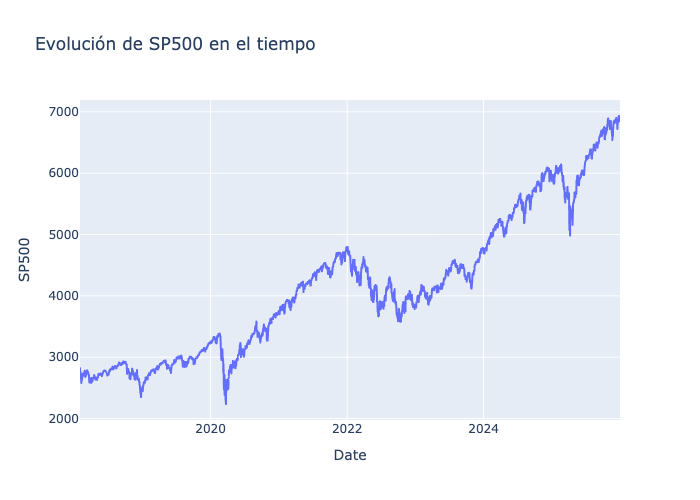

In [281]:
# Como se puede observar aunque el S&P500 tenga caidas siempre se ha recuperado y tiene tendencia alcista a largo plazo.
grafico(df,"SP500")

#### GOLD

-----Estamos analizando la columna GOLD -----
Esta columna tiene 898 nulos
Sus estadísticos descriptivos son:
 count    1993.000000
mean     1990.587405
std       678.800367
min      1176.199951
25%      1557.400024
50%      1835.400024
75%      2042.199951
max      4552.700195
Name: GOLD, dtype: float64


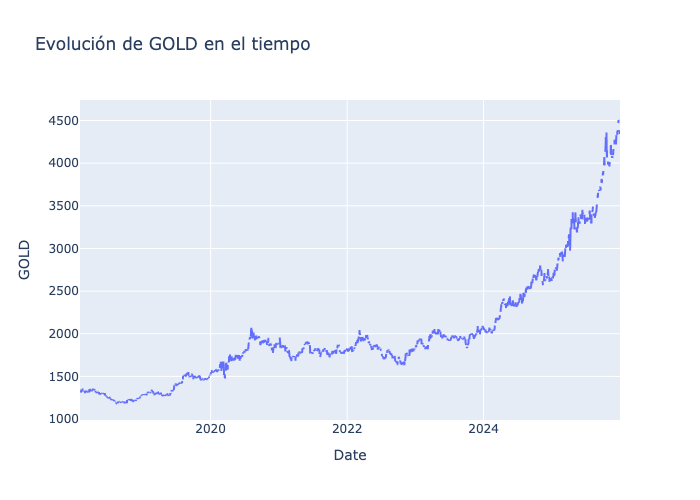

In [284]:
# al igual que la variable "SP500" esta variable tiene casi los mismos nulos
# con lo que habrá que comprobar si es por el mismo propósito
cuantitativa(df,"GOLD")
grafico(df,"GOLD")

In [286]:
# podemos observar que el patrón es el mismo por lo que se procede a imputar
# el valor anterior al nulo. 
df["GOLD"].head(20)

Date
2018-02-01    1344.300049
2018-02-02    1333.699951
2018-02-03            NaN
2018-02-04            NaN
2018-02-05    1333.000000
2018-02-06    1326.099976
2018-02-07    1311.599976
2018-02-08    1316.900024
2018-02-09    1313.099976
2018-02-10            NaN
2018-02-11            NaN
2018-02-12    1324.199951
2018-02-13    1328.099976
2018-02-14    1355.500000
2018-02-15    1352.099976
2018-02-16    1353.199951
2018-02-17            NaN
2018-02-18            NaN
2018-02-19            NaN
2018-02-20    1328.800049
Freq: D, Name: GOLD, dtype: float64

In [288]:
df["GOLD"] = df["GOLD"].ffill()
df["GOLD"].head(20)

Date
2018-02-01    1344.300049
2018-02-02    1333.699951
2018-02-03    1333.699951
2018-02-04    1333.699951
2018-02-05    1333.000000
2018-02-06    1326.099976
2018-02-07    1311.599976
2018-02-08    1316.900024
2018-02-09    1313.099976
2018-02-10    1313.099976
2018-02-11    1313.099976
2018-02-12    1324.199951
2018-02-13    1328.099976
2018-02-14    1355.500000
2018-02-15    1352.099976
2018-02-16    1353.199951
2018-02-17    1353.199951
2018-02-18    1353.199951
2018-02-19    1353.199951
2018-02-20    1328.800049
Freq: D, Name: GOLD, dtype: float64

In [290]:
print("Los nulos en la columna GOLD son",df["GOLD"].isna().sum())

Los nulos en la columna GOLD son 0


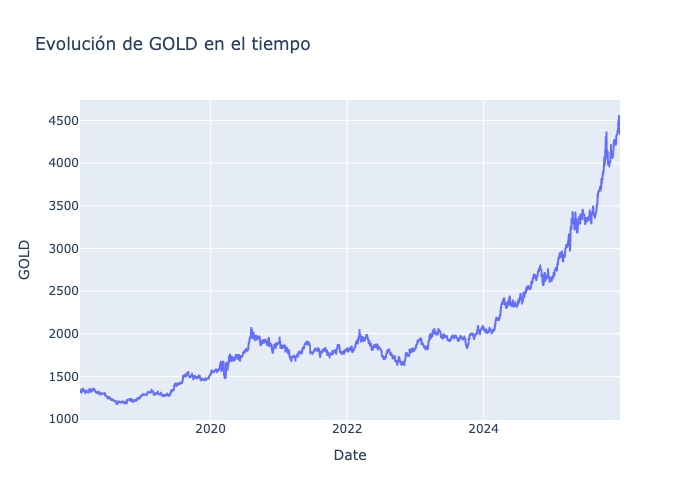

In [292]:
# Como se puede observar, al igual que en el S&P500, el oro ha tenido pequeñas correcciones pero a largo plazo tiene tendencia alcista en los ultimos años
grafico(df,"GOLD")

#### btc_busqueda

In [295]:
# tiene 3 nulos, por lo demás no veo ningun valor atípico
cuantitativa(df,"btc_busqueda")

-----Estamos analizando la columna btc_busqueda -----
Esta columna tiene 3 nulos
Sus estadísticos descriptivos son:
 count    2888.000000
mean       21.472389
std        14.574377
min         9.000000
25%        13.481481
50%        17.000000
75%        22.000000
max        99.000000
Name: btc_busqueda, dtype: float64


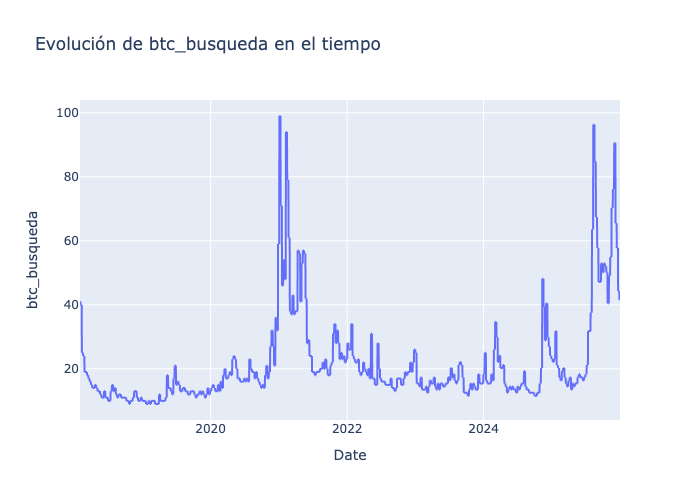

In [297]:
grafico(df,"btc_busqueda")

In [299]:
# vamos a analizar los nulos de esta columna, creo que es porque al pasar
# de temporalidad semanal a diaria no se relleno la ultima semana
df[df["btc_busqueda"].isna()] 

,BTC,ETH,XRP,BNB,SOL,TRX,DOGE,BCH,ADA,LEO,SP500,GOLD,volumen_acum_diario,volatilidad_med_diaria,dominancia_bitcoin,sent_alcista,sent_bajista,btc_busqueda,crypto_busqueda,f&g index
Date,,,,,,,,,,,,,,,,,,,,
2025-12-29,87138.140625,2934.538330,1.847724,851.187561,123.125229,0.284616,0.122730,598.325867,0.352915,8.586077,6905.740234,4343.600098,8.694455e+10,0.044037,59.688423,0.374449,0.348018,NaN,NaN,24.0
2025-12-30,88430.132812,2971.416748,1.875494,860.553711,124.931320,0.286137,0.123276,595.146240,0.351117,9.143110,6896.240234,4386.299805,6.367763e+10,0.026069,59.799166,0.374449,0.348018,NaN,NaN,23.0
2025-12-31,87508.828125,2967.037598,1.839973,863.257385,124.484467,0.284271,0.117294,598.957092,0.332830,9.608176,6845.500000,4341.100098,6.081666e+10,0.034478,59.695929,0.374449,0.348018,NaN,NaN,21.0


In [301]:
# imputamos de igual forma que en la variable anterior
df["btc_busqueda"] = df["btc_busqueda"].ffill()
print("La columna btc_busqueda tiene",df["btc_busqueda"].isna().sum(),"nulos")

La columna btc_busqueda tiene 0 nulos


#### crypto_busqueda

In [304]:
# Parecer ser el mismo caso que el anterior por que se trato de la misma forma
cuantitativa(df,"crypto_busqueda")

-----Estamos analizando la columna crypto_busqueda -----
Esta columna tiene 3 nulos
Sus estadísticos descriptivos son:
 count    2888.000000
mean       22.371893
std        18.933544
min         3.000000
25%         6.000000
50%        18.666667
75%        32.000000
max       100.000000
Name: crypto_busqueda, dtype: float64


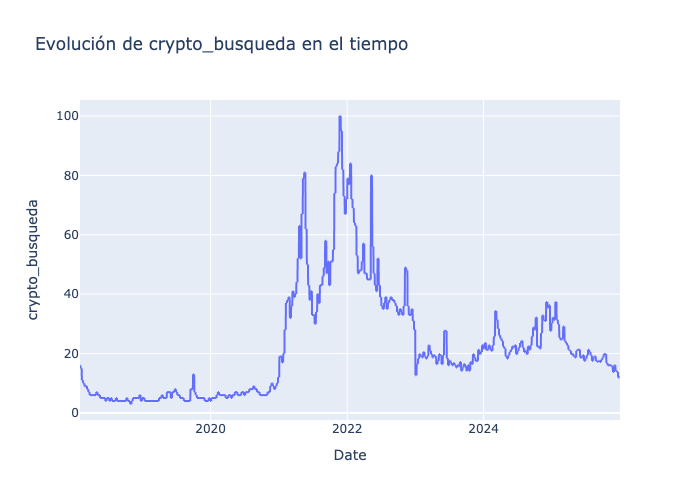

In [306]:
grafico(df,"crypto_busqueda")

In [308]:
# imputamos de igual forma que en la variable anterior
df["crypto_busqueda"] = df["crypto_busqueda"].ffill()
print("La columna btc_busqueda tiene",df["crypto_busqueda"].isna().sum(),"nulos")

La columna btc_busqueda tiene 0 nulos


#### dominancia_bitcoin

In [311]:
# solo hay un nulo,
cuantitativa(df,"dominancia_bitcoin")

-----Estamos analizando la columna dominancia_bitcoin -----
Esta columna tiene 1 nulos
Sus estadísticos descriptivos son:
 count    2890.000000
mean       54.275543
std         9.033959
min        34.829151
25%        45.787791
50%        54.846999
75%        61.476039
max        73.358926
Name: dominancia_bitcoin, dtype: float64


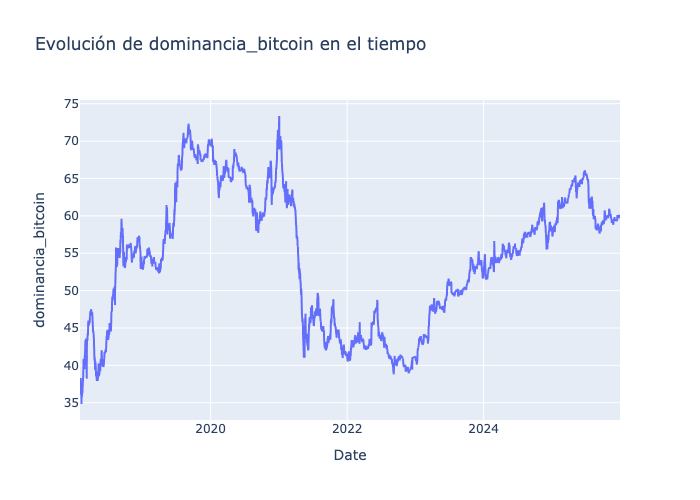

In [313]:
grafico(df,"dominancia_bitcoin")

In [315]:
# Podría ser porque no hay registro en el dataframe del que hemos sacado los datos
df[df["dominancia_bitcoin"].isna()]

,BTC,ETH,XRP,BNB,SOL,TRX,DOGE,BCH,ADA,LEO,SP500,GOLD,volumen_acum_diario,volatilidad_med_diaria,dominancia_bitcoin,sent_alcista,sent_bajista,btc_busqueda,crypto_busqueda,f&g index
Date,,,,,,,,,,,,,,,,,,,,
2024-12-05,96593.570312,3811.008301,2.295206,714.32196,233.998703,0.31924,0.430586,590.051025,1.184712,9.401618,6075.109863,2648.399902,2.697647e+11,0.098584,NaN,0.483333,0.306667,40.444444,37.333333,84.0


In [317]:
# miramos a ver si hay algun nulo en el dataframe que hemos extraido los datos pero no hay ninguno.
# esto quiere decir que igual ni existe el día "2024-12-05"
market_cap.isna().sum()

altcoin_market_cap    0
bitcoin_market_cap    0
dtype: int64

In [319]:
# filtramos para ver si esta ese día y como podemos ver no hay registro para ese día. Aqui tenemos dos opciones, hacer un forward fill como en las anteriores
# o hacer una media entre el dia anterior y el siguiente. Voy a opstar por hacer una media ya que los datos cambian bastante del día 4 al 6 
market_cap.loc["2024-12-04":"2024-12-07"]

,altcoin_market_cap,bitcoin_market_cap
Date,,
2024-12-04,1.519513e+12,2.045626e+12
2024-12-06,1.573928e+12,1.967279e+12
2024-12-07,1.580391e+12,1.974247e+12


In [321]:
# imputamos la media entre el día 4 y el 6
df["dominancia_bitcoin"].loc["2024-12-05"] = (df["dominancia_bitcoin"].loc["2024-12-04"] + df["dominancia_bitcoin"].loc["2024-12-06"]) / 2

/var/folders/lf/vdl2twvd3q59nvj1n28rqfsr0000gn/T/ipykernel_87381/6158038.py:2: FutureWarning:

ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy




In [323]:
# arreglado
df["dominancia_bitcoin"].loc["2024-12-04":"2024-12-07"]

Date
2024-12-04    57.378568
2024-12-05    56.466240
2024-12-06    55.553913
2024-12-07    55.540027
Freq: D, Name: dominancia_bitcoin, dtype: float64

#### volumen_acum_diario

-----Estamos analizando la columna volumen_acum_diario -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2.891000e+03
mean     5.608267e+10
std      4.291819e+10
min      4.818627e+09
25%      2.601409e+10
50%      4.734573e+10
75%      7.280620e+10
max      4.170250e+11
Name: volumen_acum_diario, dtype: float64


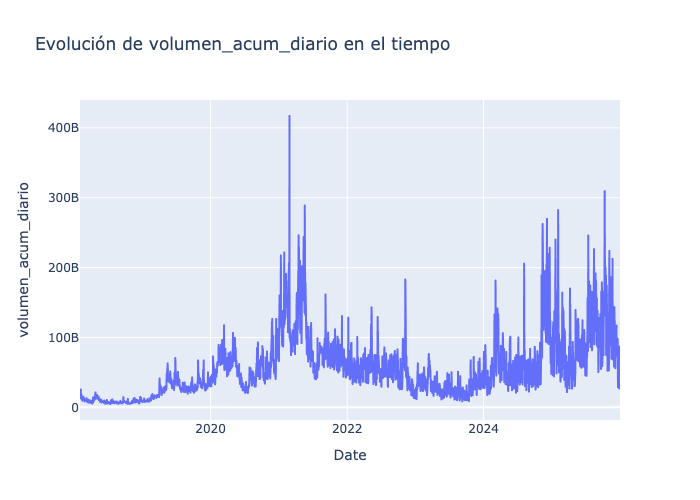

In [326]:
cuantitativa(df,"volumen_acum_diario")
grafico(df,"volumen_acum_diario")

#### volatilidad_med_diaria

-----Estamos analizando la columna volatilidad_med_diaria -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean        0.060549
std         0.040622
min         0.009298
25%         0.036228
50%         0.050227
75%         0.071684
max         0.699365
Name: volatilidad_med_diaria, dtype: float64


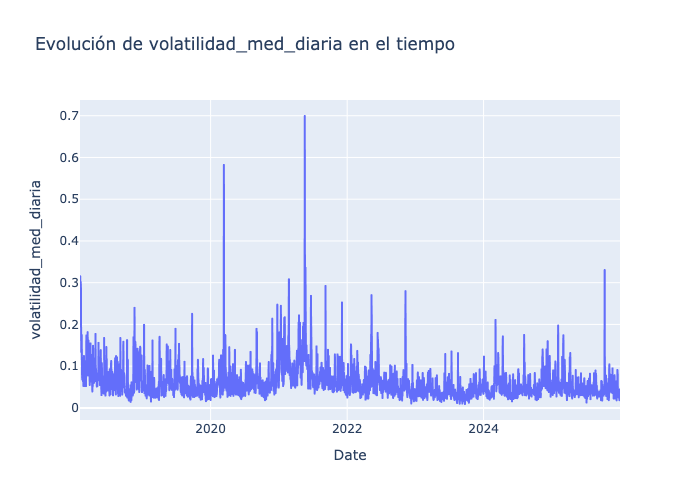

In [329]:
cuantitativa(df,"volatilidad_med_diaria")
grafico(df,"volatilidad_med_diaria")

In [330]:
# vemos puntos de volatilidad extrema en Marzo de 2020 y en Mayo de 2021, vamos a ver que paso esos meses para ver si es un error o no
df.loc["2020-03-01":"2020-03-31"].loc[df["volatilidad_med_diaria"] > 0.40]
# fue exactamente el 12 de Marzo

,BTC,ETH,XRP,BNB,SOL,TRX,DOGE,BCH,ADA,LEO,SP500,GOLD,volumen_acum_diario,volatilidad_med_diaria,dominancia_bitcoin,sent_alcista,sent_bajista,btc_busqueda,crypto_busqueda,f&g index
Date,,,,,,,,,,,,,,,,,,,,
2020-03-12,4970.788086,112.347122,0.139635,9.600166,0.0,0.008792,0.001537,152.224991,0.023961,0.986389,2480.639893,1589.300049,8.709741e+10,0.58216,65.484732,0.297386,0.513072,18.0,6.0,14.0


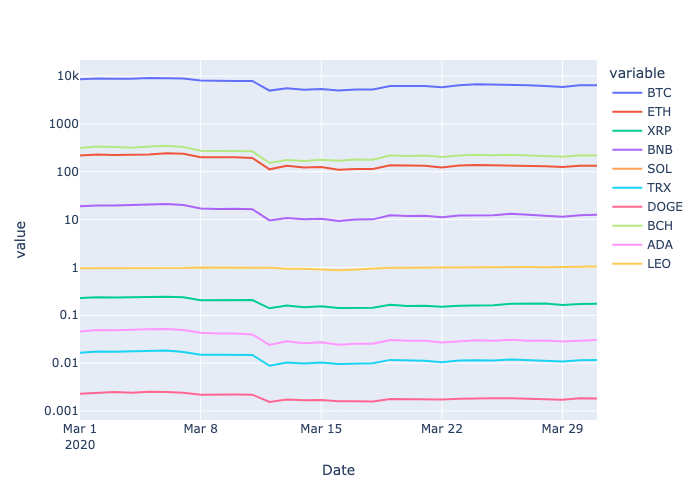

In [333]:
# vamos a ver el dataframe de bitcoin criptos para ver el precio de apuertura y de cierre
# como podemos ver la caida de bitcoin fue grande en esa fecha exacta con lo que no es un error 
criptos_marzo_2020 = df.iloc[:, 0:10].loc["2020-03-01":"2020-03-31"] # solo metemos las primeras columnas que es donde estan las criptos
fig_marzo_2020 = px.line(criptos_marzo_2020)
fig_marzo_2020.update_yaxes(type="log") # usamos escala logarítmica para que se aprecie mejor si hubo volatilidad ese día
fig_marzo_2020.show()
# durante esos días se empezo a ver el coronavirus como un problema con lo que seguramente tendría algo que ver en la volatilidad extrema de ese día

In [335]:
# fue el 19 de Mayo de 2021
df.loc["2021-05-01":"2021-05-31"].loc[df["volatilidad_med_diaria"] > 0.40]

,BTC,ETH,XRP,BNB,SOL,TRX,DOGE,BCH,ADA,LEO,SP500,GOLD,volumen_acum_diario,volatilidad_med_diaria,dominancia_bitcoin,sent_alcista,sent_bajista,btc_busqueda,crypto_busqueda,f&g index
Date,,,,,,,,,,,,,,,,,,,,
2021-05-19,37002.441406,2460.679199,1.070313,339.025482,35.107182,0.079332,0.333123,706.795837,1.482521,2.792683,4115.680176,1881.5,2.890685e+11,0.699365,44.847084,0.365188,0.269625,56.0,81.0,23.0


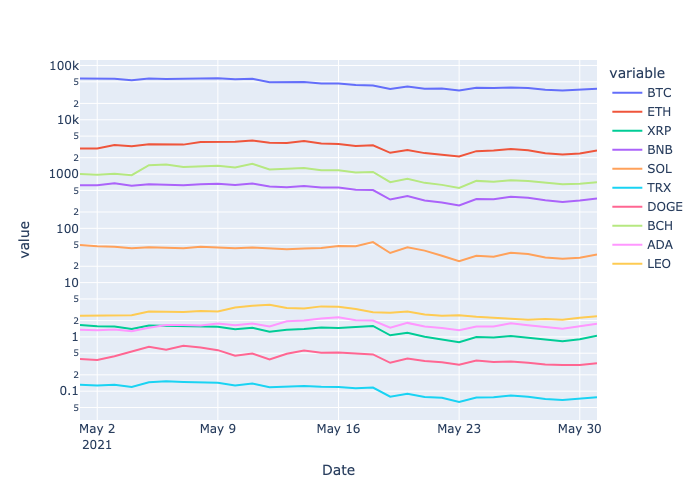

In [337]:
# se puede observar como ese día todas las criptos sufrieron una gran caida.
criptos_mayo_2021 = df.iloc[:, 0:10].loc["2021-05-01":"2021-05-31"] 
fig_mayo_2021 = px.line(criptos_mayo_2021)
fig_mayo_2021.update_yaxes(type="log") # usamos escala logarítmica para que se aprecie mejor si hubo volatilidad ese día
fig_mayo_2021.show()
# no existe error ni en marzo de 2020 ni en mayo de 2021

#### sent_alcista

-----Estamos analizando la columna sent_alcista -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean        0.349360
std         0.087001
min         0.158371
25%         0.283951
50%         0.347418
75%         0.416327
max         0.569079
Name: sent_alcista, dtype: float64


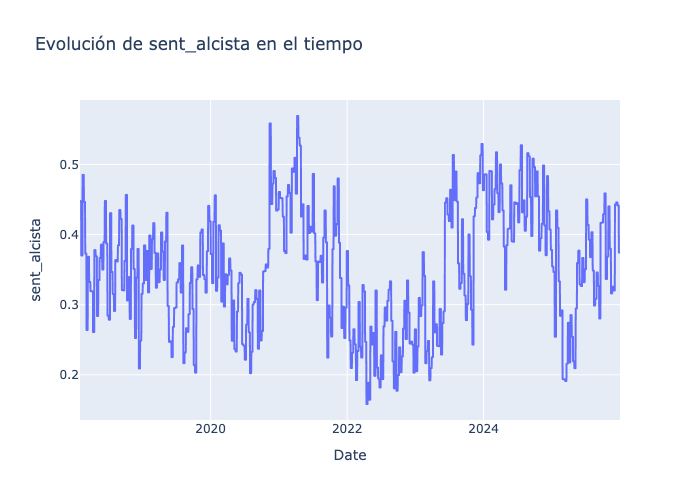

In [340]:
cuantitativa(df,"sent_alcista")
grafico(df,"sent_alcista")

#### sent_bajista

-----Estamos analizando la columna sent_bajista -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean        0.349903
std         0.099670
min         0.193084
25%         0.264286
50%         0.335897
75%         0.421245
max         0.619171
Name: sent_bajista, dtype: float64


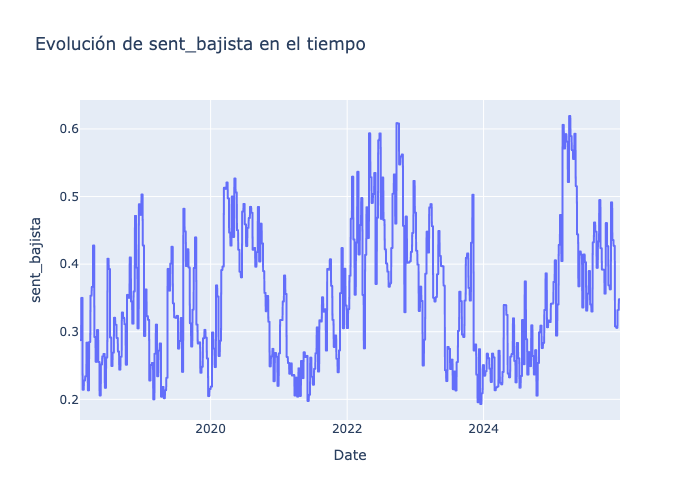

In [343]:
cuantitativa(df,"sent_bajista")
grafico(df,"sent_bajista")

#### f&g_index

In [346]:
# cambiamos de nombre la variable para que sea más facil
df = df.rename(columns={"f&g index":"f&g_index"})

-----Estamos analizando la columna f&g_index -----
Esta columna tiene 4 nulos
Sus estadísticos descriptivos son:
 count    2887.000000
mean       47.159335
std        21.703721
min         5.000000
25%        28.000000
50%        47.000000
75%        66.000000
max        95.000000
Name: f&g_index, dtype: float64


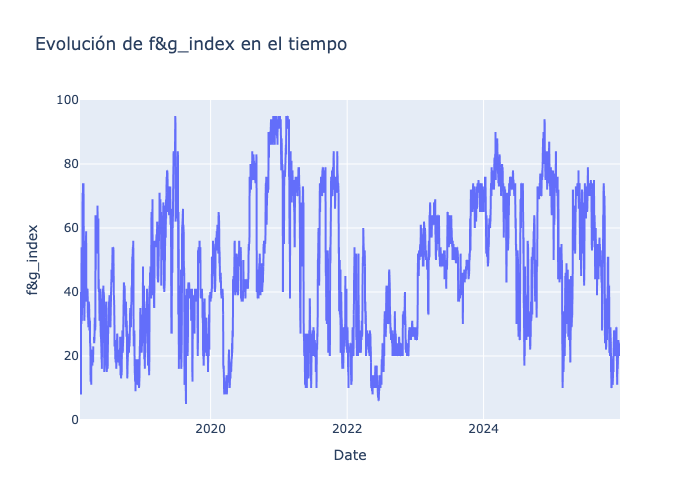

In [348]:
# esta columna tiene 4 nulos, vamos a ver si se pueden imputar de forma 
# adecuada
cuantitativa(df,"f&g_index")
grafico(df,"f&g_index")

In [350]:
# al ser solo 4 nulos y al no poder eliminar la fila ya que es una serie temporal lo mejor va a ser imputar el valor anterior tal y como
# hemos hecho en la variable "SP500" y "GOLD"
df[df["f&g_index"].isna()]

,BTC,ETH,XRP,BNB,SOL,TRX,DOGE,BCH,ADA,LEO,SP500,GOLD,volumen_acum_diario,volatilidad_med_diaria,dominancia_bitcoin,sent_alcista,sent_bajista,btc_busqueda,crypto_busqueda,f&g_index
Date,,,,,,,,,,,,,,,,,,,,
2018-04-14,7986.240234,501.477997,0.632184,13.244400,0.000000,0.040011,0.004150,738.984985,0.200853,0.000000,2656.300049,1344.800049,8.133547e+09,0.059195,44.380184,0.260870,0.427536,14.000000,6.0,NaN
2018-04-15,8329.110352,531.702026,0.682534,13.058800,0.000000,0.042971,0.004571,780.825989,0.221390,0.000000,2656.300049,1344.800049,8.510843e+09,0.069847,44.258400,0.260870,0.427536,14.000000,6.0,NaN
2018-04-16,8058.669922,511.147003,0.663297,12.210000,0.000000,0.041256,0.004585,766.473022,0.256646,0.000000,2677.840088,1347.500000,9.377723e+09,0.090225,43.733542,0.260870,0.427536,14.000000,6.0,NaN
2024-10-26,67014.695312,2479.603271,0.512761,582.806091,170.705963,0.164943,0.137357,347.780243,0.333350,6.062626,5808.120117,2754.600098,3.978733e+10,0.031079,59.654136,0.377049,0.299180,12.518519,22.4,NaN


In [352]:
# imputamos valores anteriores "forward fill"
df["f&g_index"] = df["f&g_index"].ffill()
print("La columna f&g_index tiene",df["f&g_index"].isna().sum(),"nulos")

La columna f&g_index tiene 0 nulos


## ANALISIS BIVARIANTE

In [355]:
def grafico_doble_eje(df,target,columna):
    fig = go.Figure()

    # Línea del target (eje izquierdo)
    fig.add_trace(go.Scatter(x=df.index, y=df[target], name=target, yaxis="y1"))
    # Línea de la otra variable (eje derecho)
    fig.add_trace(go.Scatter(x=df.index, y=df[columna],name=columna, yaxis="y2"))

    fig.update_layout( title=f"{columna} vs {target}",xaxis_title="Fecha",yaxis=dict(title=target),
        yaxis2=dict(title=columna,overlaying="y", side="right"))
    
    fig.add_hline(y=70, line_color="red", line_dash="dash", yref="y2") 
    fig.add_hline(y=25, line_color="green", line_dash="dash", yref="y2")
    fig.show()
    
    

### INDICADOR FRENTE A LAS VARIABLES

#### INDICADOR FRENTE A CRIPTOMONEDAS

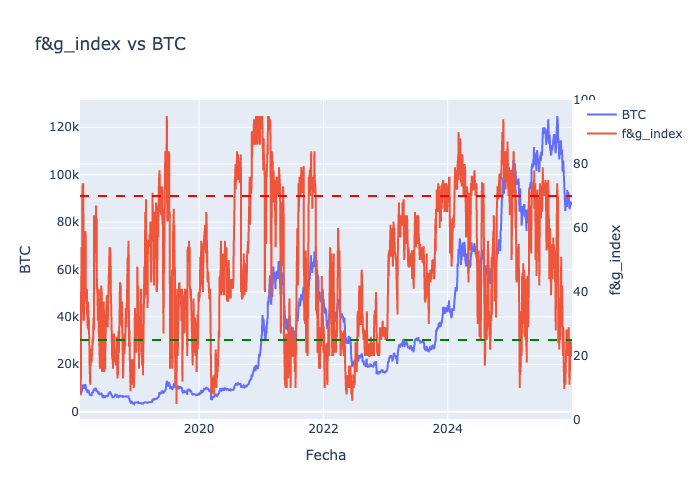

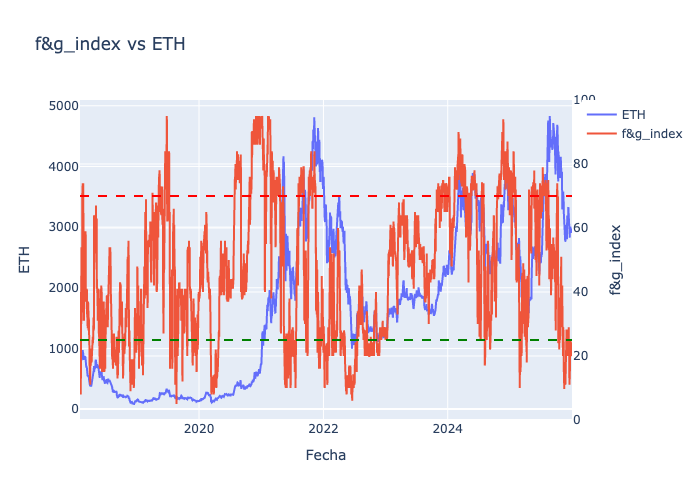

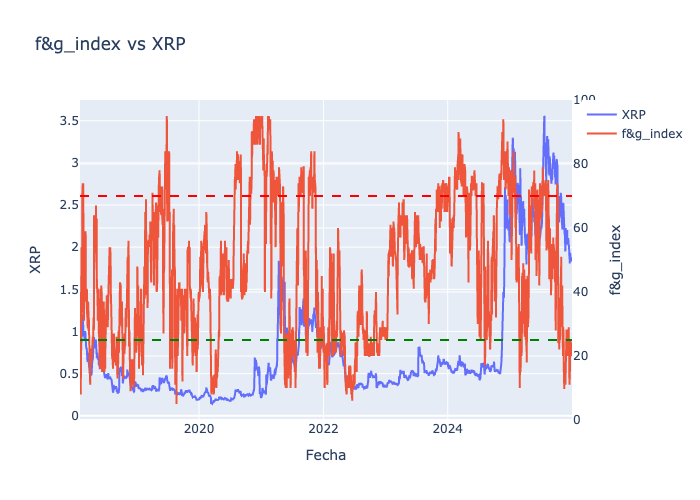

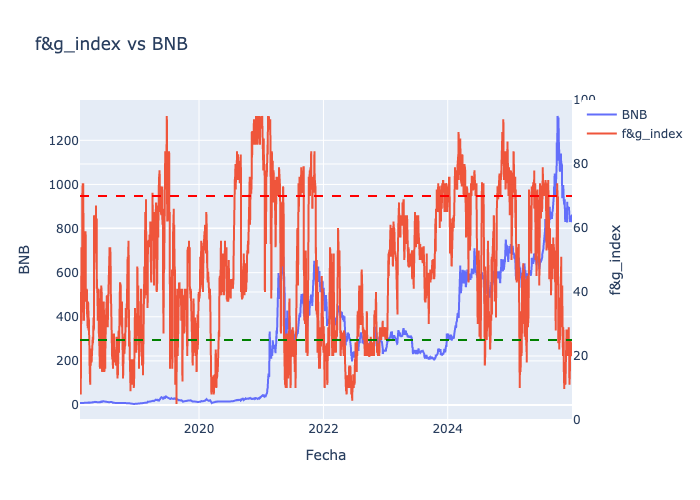

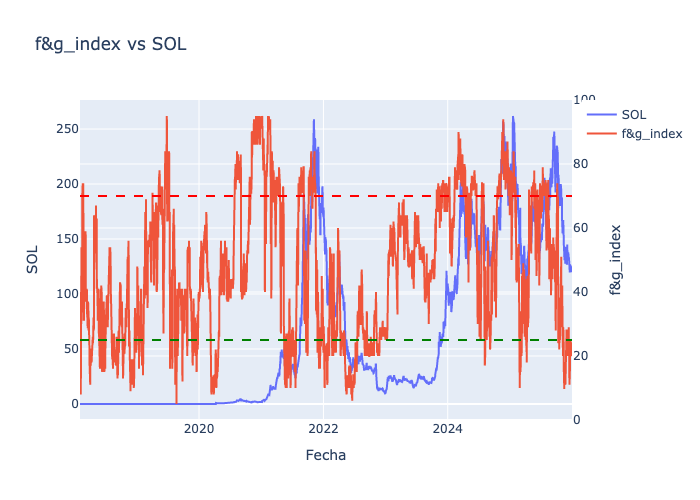

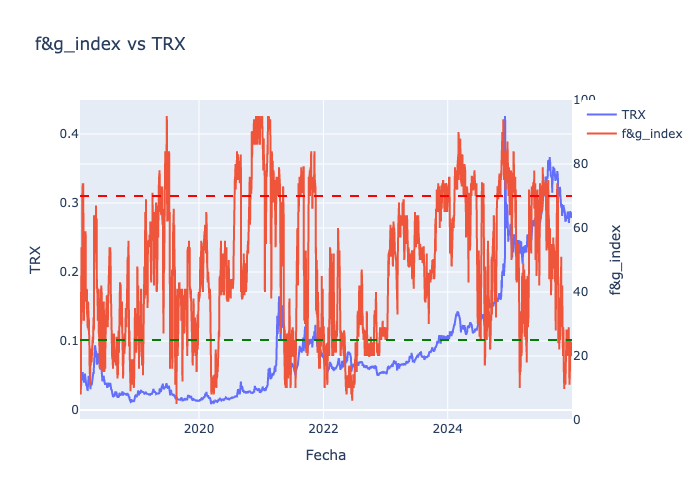

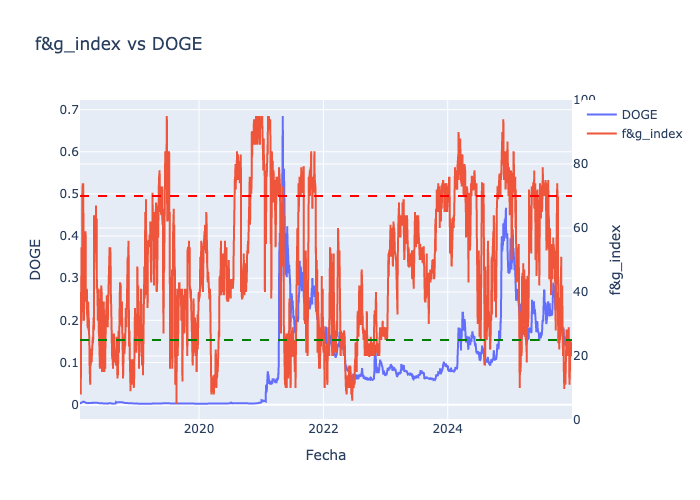

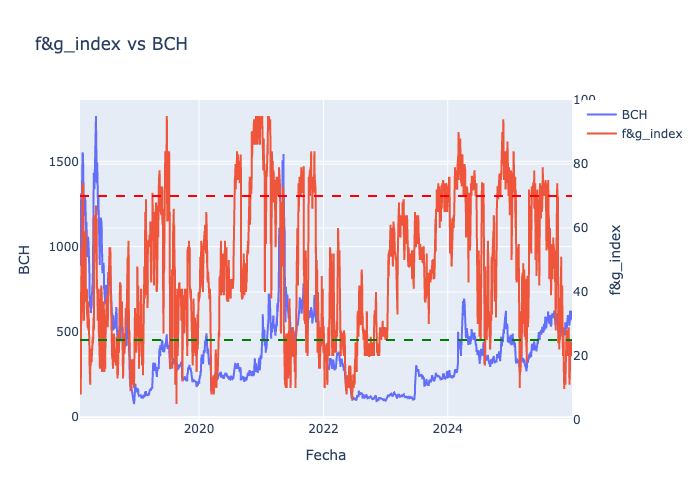

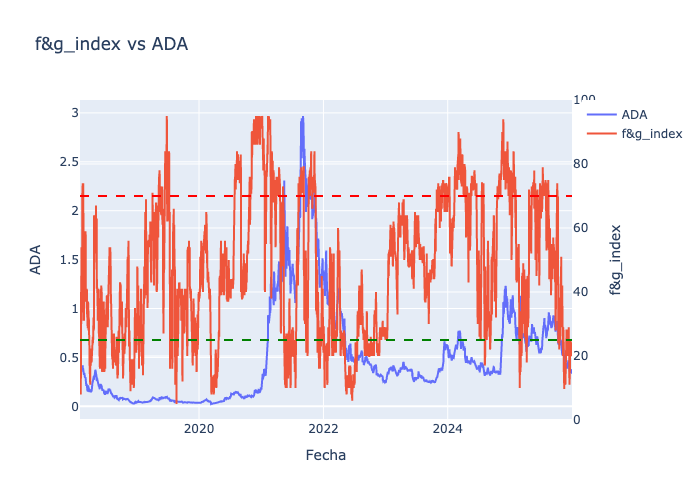

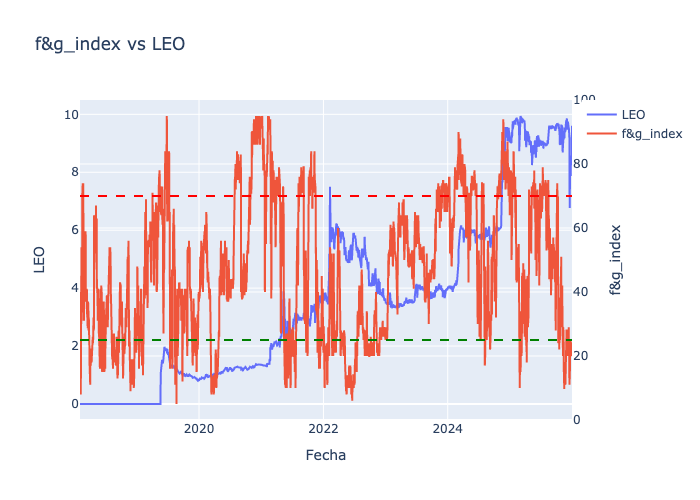

In [359]:
# Este indicador indica que con numéros mayores de 70 hay codicia (greed) y con números menores de 20 hay miedo (fear). Por lo que cuando llega a 70 puede ser señal de venta y cuando se situa por debajo o cercano
# a 20 puede ser indicador de que es una oportunidad de compra. He puesto dos lineas en el eje X para señalar el miedo y la codicia segun el indicador.
# se puede observar como en la mayoría de veces en distintas criptos cuando el indicador está por debajo de 20 es buena opción para comprar si mantienes a largo plazo. 
# También se puede observar que una en las que peores se comporta es en LEO
criptos = ["BTC","ETH","XRP","BNB","SOL","TRX","DOGE","BCH","ADA","LEO"]
for i in criptos:
  grafico_doble_eje(df,i,"f&g_index")

#### INDICADOR FRENTE AL ORO Y AL S&P500

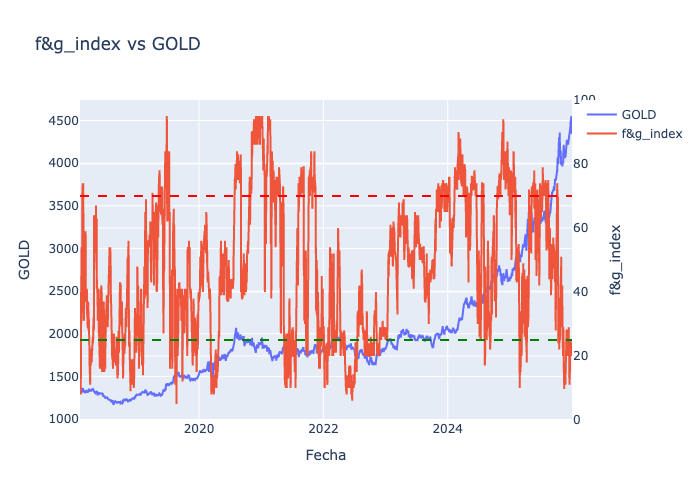

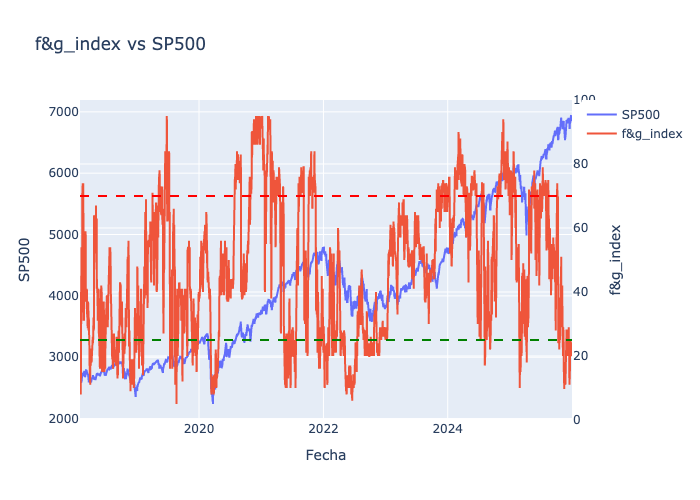

In [362]:
# Pese a que el indicador está diseñado para las criptomonedas se puede observar que no funciona mal frente al oro y al S&P500
grafico_doble_eje(df,"GOLD","f&g_index")
grafico_doble_eje(df,"SP500","f&g_index")

#### INDICADOR FRENTE A VOLUMEN Y VOLATILIDAD 

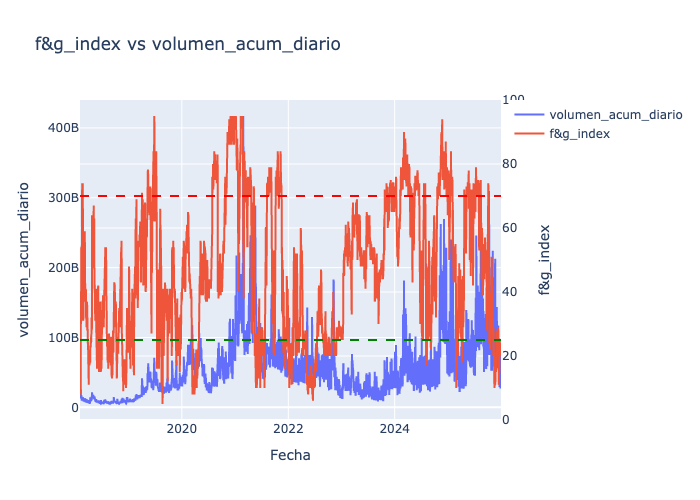

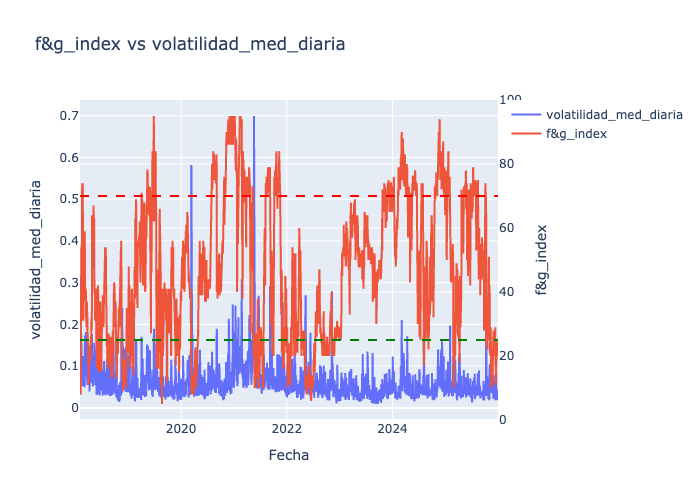

In [365]:
# En el gráfico en el que se compara el volumen acumulado diario se puede observar que la mayoría de veces que ha repuntado el volumen diario (si lo comparamos con lo que era normal) 
# el indicador marcaba codicia o valores cercanos a codicia,como por ejemplo en 2021, en marzo de 2024 o en Noviembre de 2024.
# En cuanto a la volatilidad media diaria es más dificil apreciar si tiene relación con el indicador o no.
grafico_doble_eje(df,"volumen_acum_diario","f&g_index")
grafico_doble_eje(df,"volatilidad_med_diaria","f&g_index")

#### INDICADOR FRENTE A DOMINANCIA DE BITCOIN


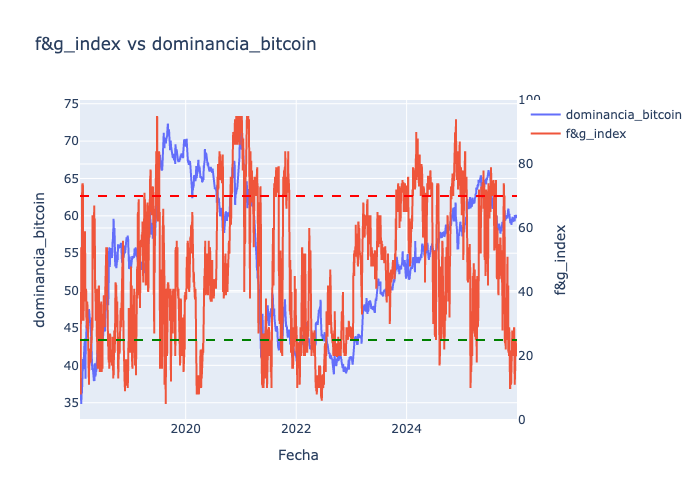

In [368]:
# La dominancia de Bitcoin suele mostrar el miedo en el mercado cripto. Los inversores suelen refugiarse en Bitcoin cuando hay tendencias bajistas y suelen optar por opciones más arriesgadas cuando 
# hay tendencias alcistas. Se puede observar este acontecimiento en periodos como el 2019-2020 cuando el indicador marcaba miedo extremo mientras que la dominancia de Bitcoin estaba muy alta y que 
# cuando el indicador empieza a marcar señales de codicia la dominancia cae debido a que los inversores o bien sacan el dinero del mercado o bien optan por alternativas más arriesgadas dentro del mercado
#cripto.
grafico_doble_eje(df,"dominancia_bitcoin","f&g_index")

#### INDICADOR FRENTE A LOS SENTIMIENTOS DEL MERCADO

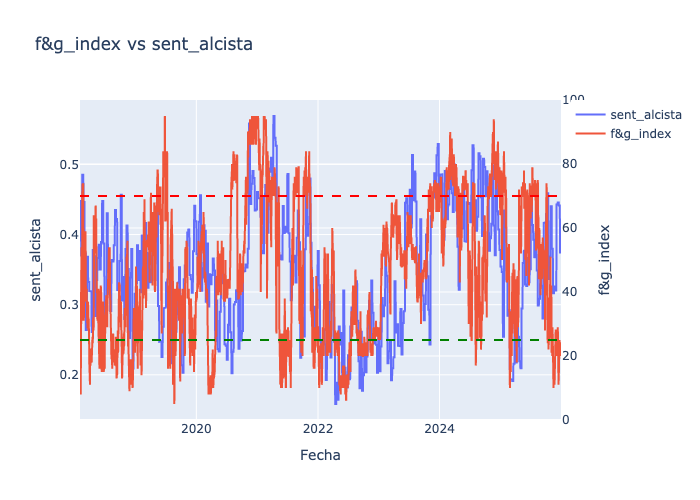

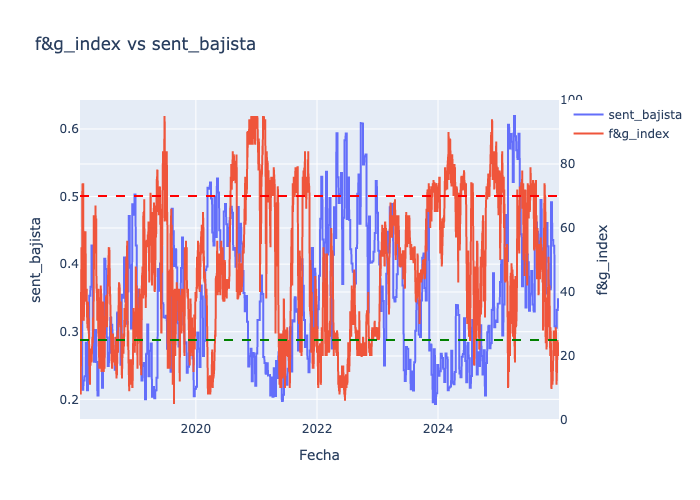

In [371]:
# Pese a ser los sentimientos sobre el S&P500 el indicador capta bien el sentimiento alcista y el bajista. Esto da lugar a pensar que entre el S&P500 y las criptomonedas hay una correlación positiva
# en el periodo que estamos examinando. De hecho, este indicador, se comporta muy parecido al sentimiento alcista y al contrario que el bajista.
grafico_doble_eje(df,"sent_alcista","f&g_index")
grafico_doble_eje(df,"sent_bajista","f&g_index")

#### INDICADOR FRENTE A BÚSQUEDAS

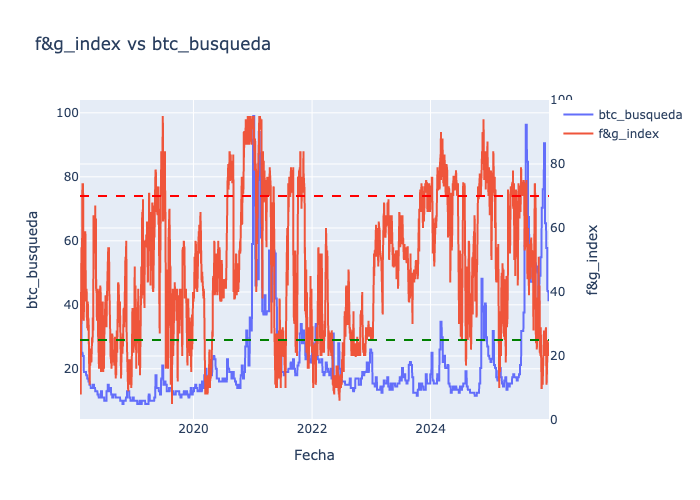

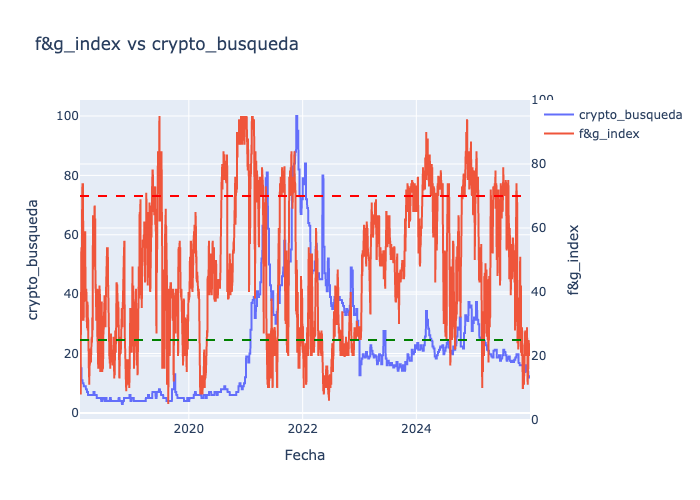

In [374]:
# Como cabía esperar, cuando el mercado cripto está en tendencia alcista y los inversores están ganando dinero se producen más busquedas sobre bitcoin, que es la criptomoneda por excelencia, y el mercado
# cripto en general. Podemos observar también que es la búsqueda de Bitcoin la que se comporta mejor frente a este indicador.
grafico_doble_eje(df,"btc_busqueda","f&g_index")
grafico_doble_eje(df,"crypto_busqueda","f&g_index")

### OTRAS COMPARACIONES INTERESANTES

#### BITCOIN FRENTE A S&P500 Y ORO

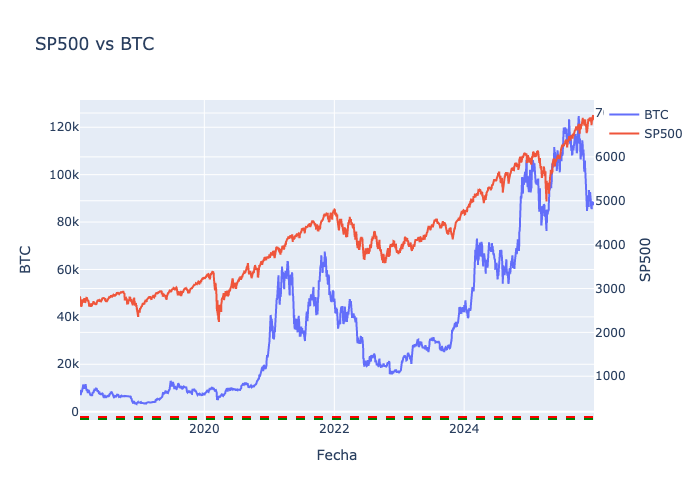

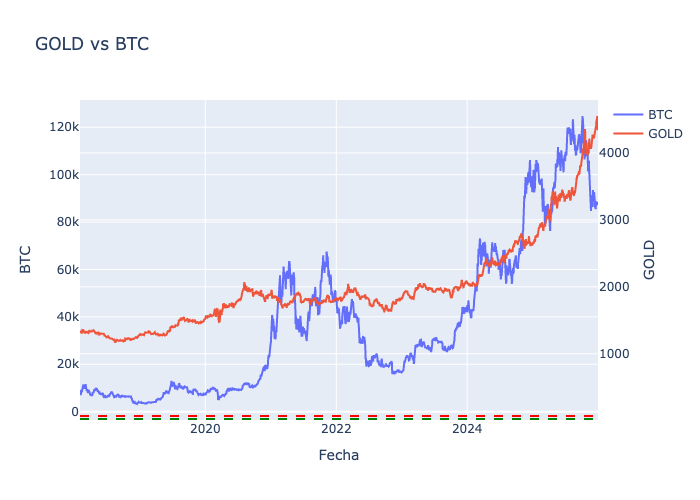

In [378]:
# Se puede observar como entre Bitcoin y el S&P500 hay correlación (se produjeron periodos alcistas entre 2020-2021 y periodos de
# corrección entre 2022-2024 y después seguieron subiendo a partir de mediados de 2024) y que ambas tienen tendencia alcista si las miramos en el largo plazo. 
# Si comparamos bitcoin y el oro no hay tanta relación entre ellos aunque ambos activos hayan tenido un comportamiento alcista en los últimos 10 años.
# Tras hacer la comparación del S&P500 con Bitcoin y ver que se comportan de manera similar cabe esperar que el fear&greed index sea parecido en ambos mercados.
grafico_doble_eje(df,"BTC","SP500")
grafico_doble_eje(df,"BTC","GOLD")

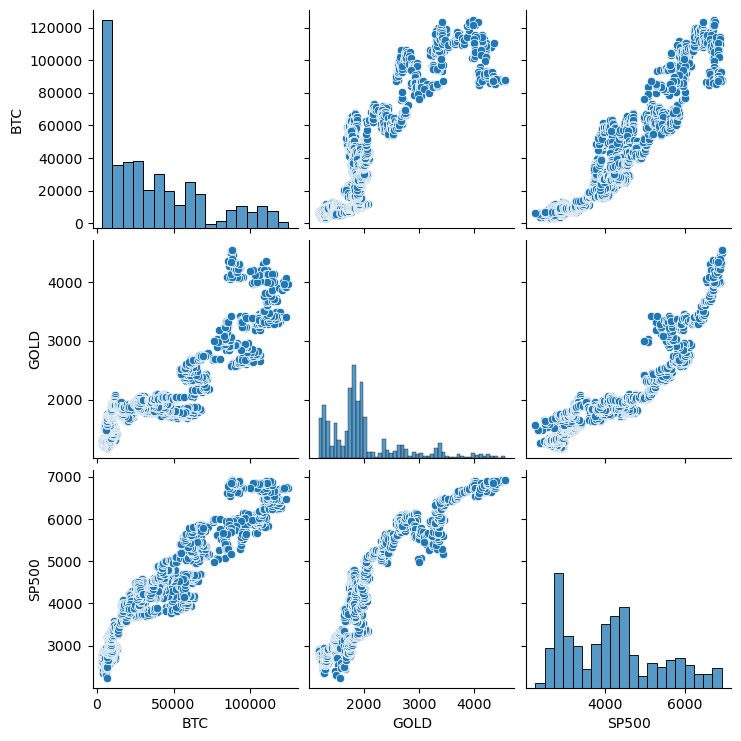

In [380]:
sns.pairplot(df[["BTC","GOLD","SP500"]])

#### BITCOIN FRENTE A BUSQUEDA "BITCOIN"

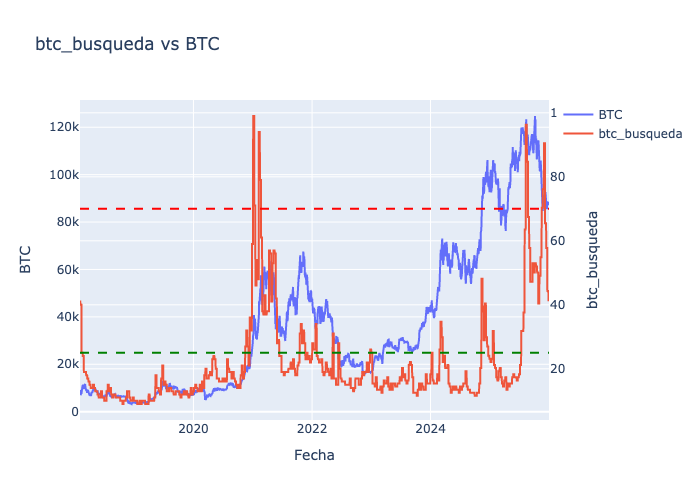

In [383]:
# Se puede observar como la gente busca más la palabra bitcoin cuando bitcoin sube de valor mientras que cuando está en tendencia bajista la gente se interesa menos por Bitcoin.
grafico_doble_eje(df,"BTC","btc_busqueda")

#### BTC FRENTE A VOLUMEN ACUMULADO DIARIO

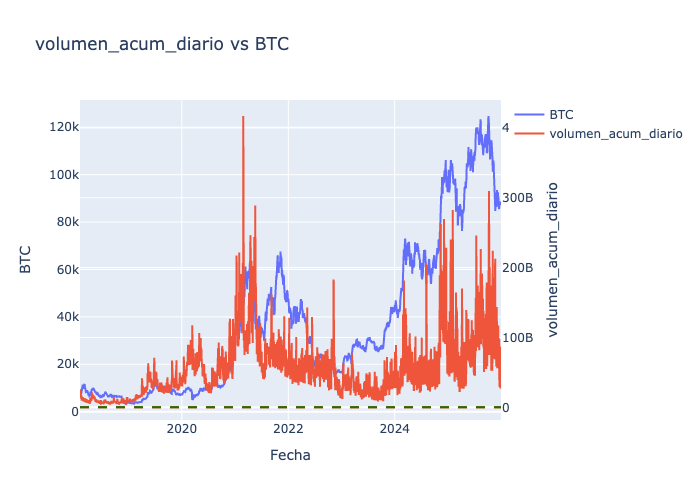

In [386]:
# Se puede observar que hay un mayor volumen (y picos de volumne) cuando hay una tendencia alcista 
# ya que más inversores entran al mercado atraidos por grandes ganancias de los inversores del mercado.
grafico_doble_eje(df,"BTC","volumen_acum_diario")

#### SENTIMIENTO BAJISTA EN LOS DIFERENTES MERCADOS

----------------------- ALCISTA -----------------------


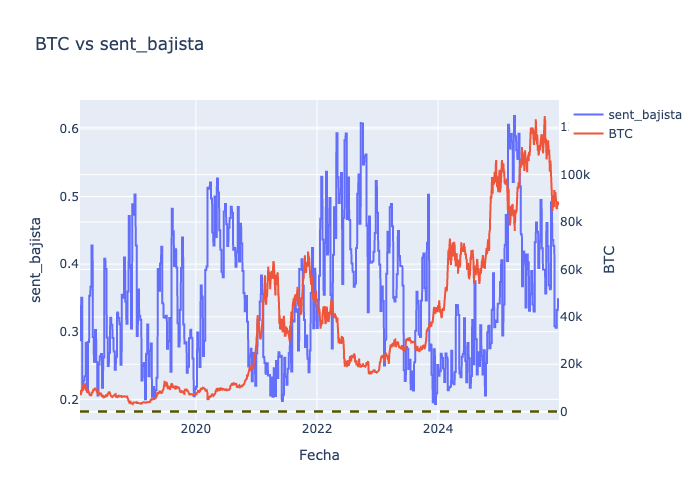

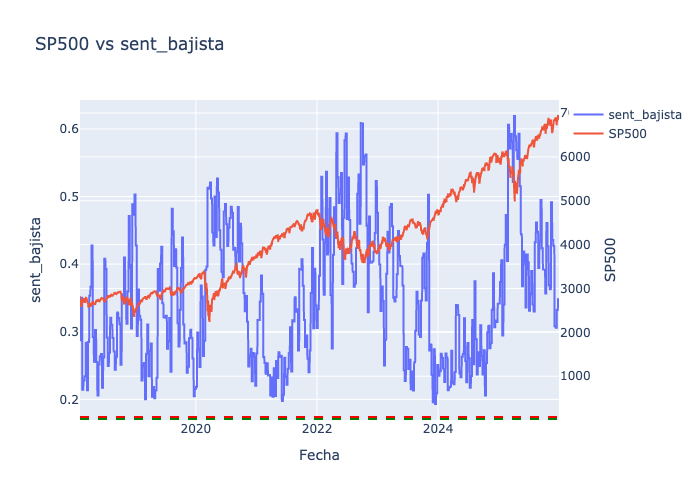

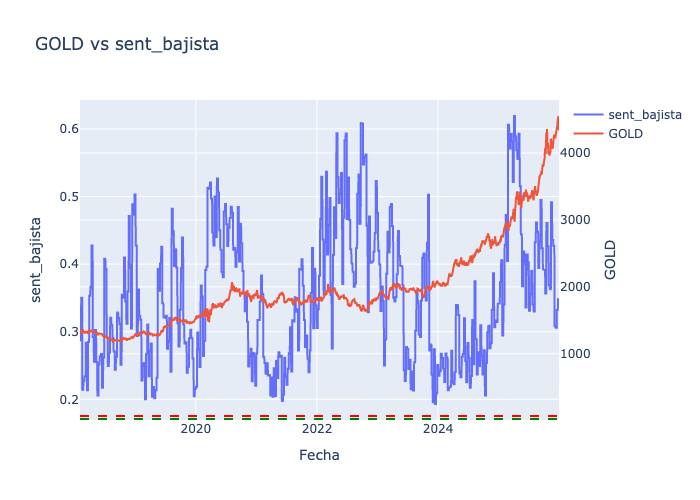

In [389]:
print("-"*23,"ALCISTA","-"*23)
grafico_doble_eje(df,"sent_bajista","BTC")
grafico_doble_eje(df,"sent_bajista","SP500")
grafico_doble_eje(df,"sent_bajista","GOLD")

### ANÁLISIS MULTIVARIANTE

<Axes: >

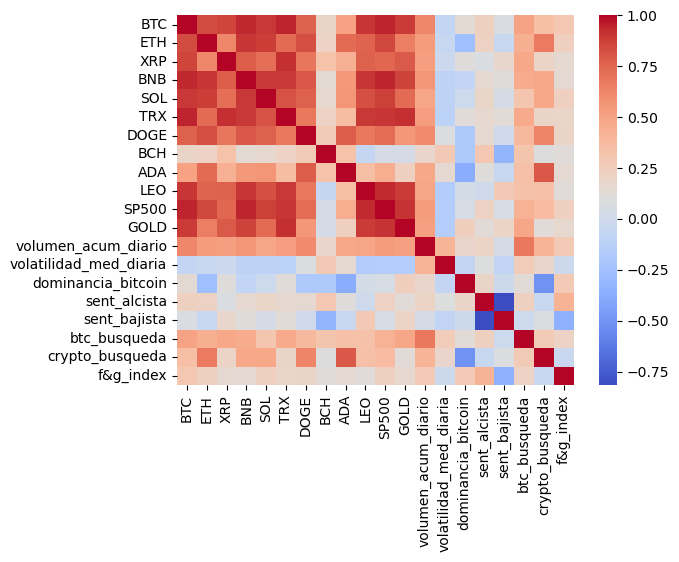

In [392]:
# Como era de esperar vemos que tantos las criptomonedas como los otros mercados están relacionados entre sí
# pero no hay ninguna variable muy fuertemente relacionada con la variable "target"
sns.heatmap(df.corr(), cmap = "coolwarm")

In [394]:
# Se puede observar que las variables más importantes si hablamos de correlación son el sentimiento alcista de la encuesta AAII, el sentimiento bajista
# de la misma encuesta, el precio de Bitcoin, el volumen acumulado diario de las 10 criptomonedas más importantes actualmente y la dominancia de Bitcoin.
# También se puede observar que el precio del índice del S&P500 está relacionado con el indicador como comentábamos anteriormente.
df.corr()["f&g_index"].sort_values(ascending = True)

sent_bajista             -0.352853
crypto_busqueda          -0.033592
volatilidad_med_diaria   -0.018832
BCH                       0.116233
LEO                       0.116714
BNB                       0.145311
ADA                       0.145567
XRP                       0.154813
GOLD                      0.159259
TRX                       0.188236
DOGE                      0.193226
btc_busqueda              0.206656
SOL                       0.234605
ETH                       0.238566
SP500                     0.240114
dominancia_bitcoin        0.281035
volumen_acum_diario       0.281738
BTC                       0.304286
sent_alcista              0.421368
f&g_index                 1.000000
Name: f&g_index, dtype: float64

In [396]:
df.columns

Index(['BTC', 'ETH', 'XRP', 'BNB', 'SOL', 'TRX', 'DOGE', 'BCH', 'ADA', 'LEO',
       'SP500', 'GOLD', 'volumen_acum_diario', 'volatilidad_med_diaria',
       'dominancia_bitcoin', 'sent_alcista', 'sent_bajista', 'btc_busqueda',
       'crypto_busqueda', 'f&g_index'],
      dtype='object')

<Axes: >

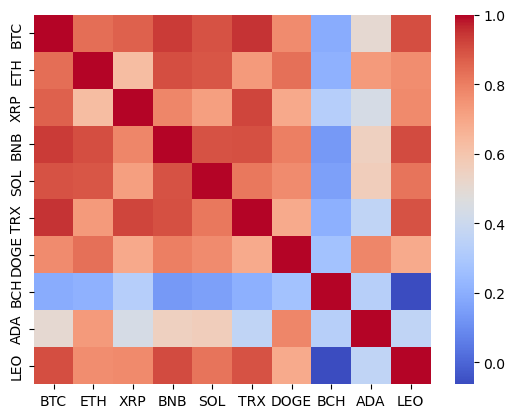

In [398]:
#Correlación entre altcoins
altcoins = df[["BTC","ETH","XRP","BNB","SOL","TRX","DOGE","BCH","ADA","LEO"]]
sns.heatmap(altcoins.corr(),cmap = "coolwarm")
# se puede observar que hay una alta correlación entre la mayoria de altcoins

### FEATURE ENGINEERING

In [401]:
# Eliminamos la mayoría de Alcoins ya que tienen una alta correlación entre ellas,
# por lo que voy a dejar BTC y ETH solo
df = df.drop(["XRP","BNB","SOL","TRX","DOGE","BCH","ADA","LEO"], axis = 1)

In [403]:
# Eliminamos la variable de sentimiento alcista ya que la de sentimiento bajista es la unica con correlación negativa
# con nuestra target

df = df.drop("sent_bajista", axis = 1)

In [405]:
# 1. añadimos una variable que muestre el cambio porcentual de BTC diariamente
df["BTC_var"] = df["BTC"].pct_change()
df["BTC_var"] = df["BTC_var"].ffill().bfill()

In [407]:
# 2. añadimos el RSI
delta = df['BTC'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
df['RSI'] = 100 - (100 / (1 + rs))
# sabemos que va a haber 13 nulos al principio ya que utiliza el rolling de 14 días
# por lo que vamos a hacer un fillna backfill
df["RSI"] = df["RSI"].ffill().bfill()

In [409]:
# 3. Distancias a medias moviles 50 periodos
df['dist_SMA_50'] = (df['BTC'] / df['BTC'].rolling(50).mean()) - 1
# igual que en la variable anterior, sabemos que se van a producir nulos con lo que hacemos un backfill
df["dist_SMA_50"] = df["dist_SMA_50"].ffill().bfill()

In [411]:
# 5. VIX
vix = yf.download("^VIX", start = "2018-01-01", end = "2026-01-01")
vix = vix["Close"].rename(columns={"Close":"vix"})
df["vix"] = vix
df["vix"] = df["vix"].ffill()
df["var_vix"] = df["vix"].pct_change()
df["var_vix"] = df["var_vix"].ffill().bfill()

df['roc_15d'] = btc['Close'].pct_change(periods=15)
df["roc_15d"] = df["roc_15d"].ffill().bfill()

# Variación de hoy comparada con la media de variación de los ultimos 20 días
btc['diario_range'] = (btc['High'] - btc['Low']) / btc['Close']
df['range_relative'] = btc['diario_range'] / btc['diario_range'].rolling(20).mean()
df['range_relative'] = df['range_relative'].ffill().bfill()


[*********************100%***********************]  1 of 1 completed


In [413]:
# 4. Volatilidad 7 días
df['BTC_vol_7'] = df['BTC_var'].rolling(window=7).std() * 100
df["BTC_vol_7"] = df["BTC_vol_7"].ffill().bfill()

In [415]:
## 6. BANDAS DE BOLLINGER
# Media móvil 20 días
df['sma_20'] = btc['Close'].rolling(window=20).mean()
# Desviación estándar
df['std_20'] = btc['Close'].rolling(window=20).std()
# Banda Inferior y Superior
df['bollinger_low'] = df['sma_20'] - (2 * df['std_20'])
# LA VARIABLE PARA EL MODELO: ¿A qué distancia está el precio de la banda inferior?
df['dist_bollinger_low'] = (btc['Close'] - df['bollinger_low']) / df['bollinger_low']

df["dist_bollinger_low"] = df["dist_bollinger_low"].ffill().bfill()

df = df.drop(["bollinger_low","std_20","sma_20"], axis = 1)

In [417]:
# 7. Ratio de cambio (comparación del precio actual con el precio de hace 15 días)
df['roc_15d'] = btc['Close'].pct_change(periods=15)
df["roc_15d"] = df["roc_15d"].ffill().bfill()


In [419]:
# 8. Variación de hoy comparada con la media de variación de los ultimos 20 días
btc['diario_range'] = (btc['High'] - btc['Low']) / btc['Close']
df['range_relative'] = btc['diario_range'] / btc['diario_range'].rolling(20).mean()
df['range_relative'] = df['range_relative'].ffill().bfill()

In [421]:
# 9. Drawdown de 30 y 60 días (comparación del precio más alto con el actual)
btc['max_60d'] = btc['Close'].rolling(window=60).max()
df['drawdown_60d'] = (btc['Close'] - btc['max_60d']) / btc['max_60d']
df['drawdown_60d'] = df['drawdown_60d'].ffill().bfill()

btc['max_30d'] = btc['Close'].rolling(window=30).max()
df['drawdown_30d'] = (btc['Close'] - btc['max_30d']) / btc['max_30d']
df['drawdown_30d'] = df['drawdown_30d'].ffill().bfill()

In [423]:
df.isna().sum()

BTC                       0
ETH                       0
SP500                     0
GOLD                      0
volumen_acum_diario       0
volatilidad_med_diaria    0
dominancia_bitcoin        0
sent_alcista              0
btc_busqueda              0
crypto_busqueda           0
f&g_index                 0
BTC_var                   0
RSI                       0
dist_SMA_50               0
vix                       0
var_vix                   0
roc_15d                   0
range_relative            0
BTC_vol_7                 0
dist_bollinger_low        0
drawdown_60d              0
drawdown_30d              0
dtype: int64

In [425]:
df.head()

,BTC,ETH,SP500,GOLD,volumen_acum_diario,volatilidad_med_diaria,dominancia_bitcoin,sent_alcista,btc_busqueda,crypto_busqueda,...,RSI,dist_SMA_50,vix,var_vix,roc_15d,range_relative,BTC_vol_7,dist_bollinger_low,drawdown_60d,drawdown_30d
Date,,,,,,,,,,,,,,,,,,,,,
2018-02-01,9170.540039,1036.790039,2821.979980,1344.300049,1.829553e+10,0.245634,37.149679,0.447712,41.0,16.0,...,52.138108,-0.080058,13.470000,0.285078,0.115954,0.54983,8.887554,0.716288,-0.408619,-0.027824
2018-02-02,8830.750000,915.784973,2762.129883,1333.699951,2.579074e+10,0.315503,36.867967,0.447712,41.0,16.0,...,52.138108,-0.080058,17.309999,0.285078,0.115954,0.54983,8.887554,0.716288,-0.408619,-0.027824
2018-02-03,9174.910156,964.018982,2762.129883,1333.699951,1.467033e+10,0.224081,36.090989,0.447712,41.0,16.0,...,52.138108,-0.080058,17.309999,0.000000,0.115954,0.54983,8.887554,0.716288,-0.408619,-0.027824
2018-02-04,8277.009766,834.682007,2762.129883,1333.699951,1.296530e+10,0.213996,36.831309,0.447712,40.0,15.0,...,52.138108,-0.080058,17.309999,0.000000,0.115954,0.54983,8.887554,0.716288,-0.408619,-0.027824
2018-02-05,6955.270020,697.950989,2648.939941,1333.000000,1.630273e+10,0.301624,38.316608,0.447712,40.0,15.0,...,52.138108,-0.080058,37.320000,1.155979,0.115954,0.54983,8.887554,0.716288,-0.408619,-0.027824


### PREPARACIÓN Y ESCALADO DE DATOS

In [428]:
# SEPARAMOS LOS DATOS DEL 2018-2023 (TRAIN) Y DEL 2024-2025 (TEST) PARA VER SI SOMOS CAPACES DE PREDECIR EL FEAR & GREED CON LAS VARIABLES QUE TENEMOS
X = df.drop(["f&g_index"], axis = 1)
Y = df["f&g_index"]
X_train = X.loc[:"2023-12-31"]
X_test = X.loc["2024-01-01":]
Y_train = Y.loc[:"2023-12-31"]
Y_test = Y.loc["2024-01-01":]

In [430]:
# COMPROBAMOS QUE ESTÁN BIEN SEPARADOS
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(2160, 21)
(731, 21)
(2160,)
(731,)


In [432]:
# ESTANDARIZAMOS LOS DATOS
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [434]:
X_train_scaled

array([[-0.79033302, -0.19467053, -1.12666745, ...,  3.26405266,
        -1.91595895,  0.73757509],
       [-0.81145839, -0.30146574, -1.21337186, ...,  3.26405266,
        -1.91595895,  0.73757509],
       [-0.79006132, -0.25889594, -1.21337186, ...,  3.26405266,
        -1.91595895,  0.73757509],
       ...,
       [ 1.25691425,  0.9208078 ,  1.69516916, ..., -0.75285157,
         0.82297773,  0.54465221],
       [ 1.26048913,  0.91319543,  1.69516916, ..., -0.73973908,
         0.83283303,  0.5578851 ],
       [ 1.26722142,  0.9038453 ,  1.69516916, ..., -0.75013039,
         0.85139274,  0.58280554]], shape=(2160, 21))

### DESARROLLO DE LOS MODELOS DE APRENDIZAJE AUTOMÁTICO

In [437]:
# REGRESIÓN LINEAL
lr = LinearRegression()
lr.fit(X_train,Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [439]:
# tenemos resultados muy malos en estos modelos lo que sugiere que 
Y_pred = lr.predict(X_test)
print("RMSE:", root_mean_squared_error(Y_test, Y_pred))
print("R2:", r2_score(Y_test, Y_pred))

RMSE: 47.17704013210759
R2: -4.6135247981210314


In [441]:
# RANDOM FOREST
rf = RandomForestRegressor(random_state = 42)
rf_params = {
    "n_estimators": [50,100,200],
    "max_features": ["sqrt",None],
    "max_depth": [10,20,30,None],
    "min_samples_split":[2,5,10]}

In [443]:
rf_random = RandomizedSearchCV(rf,rf_params,
                               n_iter = 20, 
                               cv = 5, 
                               verbose = 2,
                               random_state = 42,
                               n_jobs = -1)

In [446]:
rf_random.fit(X_train_scaled,Y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END max_depth=10, max_features=sqrt, min_samples_split=5, n_estimators=100; total time=   0.5s
[CV] END max_depth=10, max_features=sqrt, min_samples_split=5, n_estimators=100; total time=   0.5s
[CV] END max_depth=10, max_features=sqrt, min_samples_split=5, n_estimators=100; total time=   0.5s
[CV] END max_depth=10, max_features=sqrt, min_samples_split=5, n_estimators=100; total time=   0.5s
[CV] END max_depth=10, max_features=sqrt, min_samples_split=5, n_estimators=100; total time=   0.5s
[CV] END max_depth=20, max_features=sqrt, min_samples_split=2, n_estimators=50; total time=   0.4s
[CV] END max_depth=20, max_features=sqrt, min_samples_split=2, n_estimators=50; total time=   0.4s
[CV] END max_depth=20, max_features=sqrt, min_samples_split=2, n_estimators=50; total time=   0.4s
[CV] END max_depth=None, max_features=sqrt, min_samples_split=10, n_estimators=200; total time=   1.2s
[CV] END max_depth=None, max_features=

,estimator,RandomForestR...ndom_state=42)
,param_distributions,"{'max_depth': [10, 20, ...], 'max_features': ['sqrt', None], 'min_samples_split': [2, 5, ...], 'n_estimators': [50, 100, ...]}"
,n_iter,20
,scoring,None
,n_jobs,-1
,refit,True
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [448]:
print(f"Mejores resultados:{rf_random.best_params_}")

Mejores resultados:{'n_estimators': 100, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': 20}


In [450]:
best_rf = rf_random.best_estimator_

In [452]:
y_pred = best_rf.predict(X_test_scaled)
print("RMSE:", root_mean_squared_error(Y_test, y_pred))
print("R2:", r2_score(Y_test, y_pred))

RMSE: 13.64911919917599
R2: 0.5301237233963032


In [454]:
# Se puede observar que la variable f&g_ayer tiene demasiado peso
importancias_rf = pd.Series(best_rf.feature_importances_, index=X_train.columns)
print(importancias_rf.sort_values(ascending=False))

dist_SMA_50               0.237869
drawdown_60d              0.169857
drawdown_30d              0.065986
roc_15d                   0.064985
sent_alcista              0.055165
btc_busqueda              0.050493
BTC                       0.047542
dominancia_bitcoin        0.045386
RSI                       0.037299
ETH                       0.028763
crypto_busqueda           0.028749
vix                       0.027519
GOLD                      0.026749
SP500                     0.025780
volumen_acum_diario       0.025264
dist_bollinger_low        0.023137
BTC_vol_7                 0.011883
BTC_var                   0.010761
volatilidad_med_diaria    0.008188
range_relative            0.004902
var_vix                   0.003722
dtype: float64


In [456]:
# XGBOOST
xgb = XGBRegressor(random_state = 42)
xgb_params = { "colsample_bytree": [0.5,0.7,1],
               "eta": [0.01,0.05,0.1],
               "n_estimators": [200,500,1000],
               "max_depth": [3,5,10] }


In [458]:
xgb_random = RandomizedSearchCV(xgb,
                                xgb_params,
                                n_iter = 20, 
                               cv = 5, 
                               verbose = 2,
                               random_state = 42,
                               n_jobs = -1)
xgb_random.fit(X_train_scaled,Y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END colsample_bytree=0.5, eta=0.01, max_depth=3, n_estimators=200; total time=   0.2s
[CV] END colsample_bytree=0.5, eta=0.01, max_depth=3, n_estimators=200; total time=   0.2s
[CV] END colsample_bytree=0.5, eta=0.01, max_depth=3, n_estimators=200; total time=   0.2s
[CV] END colsample_bytree=0.5, eta=0.01, max_depth=3, n_estimators=200; total time=   0.1s
[CV] END colsample_bytree=0.5, eta=0.01, max_depth=3, n_estimators=200; total time=   0.1s
[CV] END colsample_bytree=0.7, eta=0.01, max_depth=5, n_estimators=200; total time=   0.4s
[CV] END colsample_bytree=0.7, eta=0.01, max_depth=5, n_estimators=200; total time=   0.4s
[CV] END colsample_bytree=0.7, eta=0.01, max_depth=5, n_estimators=200; total time=   0.4s
[CV] END colsample_bytree=0.7, eta=0.01, max_depth=5, n_estimators=200; total time=   0.5s
[CV] END colsample_bytree=0.7, eta=0.01, max_depth=5, n_estimators=200; total time=   0.5s
[CV] END colsample_bytree=0.

,estimator,"XGBRegressor(...ree=None, ...)"
,param_distributions,"{'colsample_bytree': [0.5, 0.7, ...], 'eta': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], 'n_estimators': [200, 500, ...]}"
,n_iter,20
,scoring,None
,n_jobs,-1
,refit,True
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [460]:
print(f"Mejores parametros:",xgb_random.best_params_)
best_xgb = xgb_random.best_estimator_

Mejores parametros: {'n_estimators': 500, 'max_depth': 3, 'eta': 0.05, 'colsample_bytree': 0.5}


In [462]:
y_pred_xgb = best_xgb.predict(X_test_scaled)
print("RMSE:", root_mean_squared_error(Y_test, y_pred_xgb))
print("R2:", r2_score(Y_test, y_pred_xgb))

RMSE: 16.06812833287623
R2: 0.34881430884773834


In [464]:
# aunque la variable f&g_ayer es la principal no tiene tanto peso como tenía en RandomForest
# Por lo que hace que este modelo sea mejor al no ser tan dependiente.
importancias_xgb = pd.Series(best_xgb.feature_importances_, index=X_train.columns)
print(importancias_xgb.sort_values(ascending=False))

dist_SMA_50               0.348960
drawdown_60d              0.149380
drawdown_30d              0.141905
btc_busqueda              0.049540
roc_15d                   0.039809
sent_alcista              0.037217
volumen_acum_diario       0.029851
vix                       0.029222
BTC                       0.028550
dominancia_bitcoin        0.027923
crypto_busqueda           0.027278
RSI                       0.017729
GOLD                      0.015584
BTC_var                   0.013127
ETH                       0.012597
SP500                     0.009967
dist_bollinger_low        0.005854
volatilidad_med_diaria    0.005364
range_relative            0.004259
BTC_vol_7                 0.003280
var_vix                   0.002604
dtype: float32


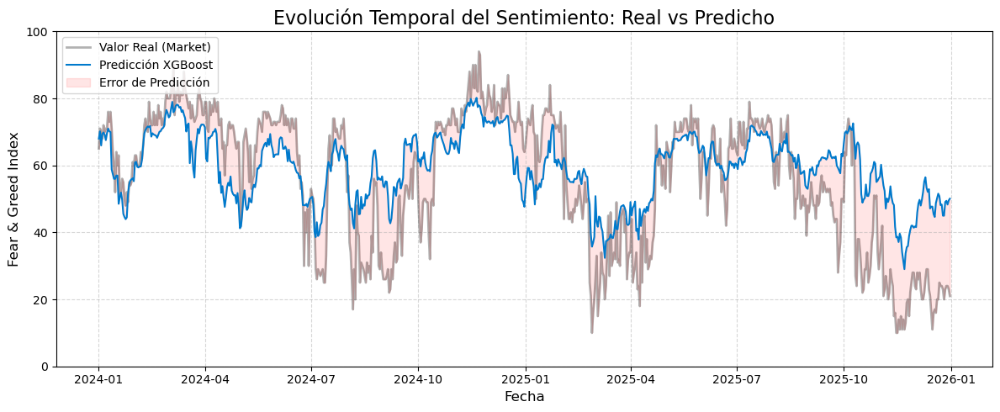

In [466]:
plt.figure(figsize=(12, 5))

# fear & greed original
plt.plot(X_test.index, Y_test, color='black', label='Valor Real (Market)', alpha=0.3, linewidth=2)

# 2. fear & greed propio
plt.plot(X_test.index, y_pred, color='#007acc', label='Predicción XGBoost', linewidth=1.5)

# diferencias (sombras)
plt.fill_between(X_test.index, Y_test, y_pred, color='red', alpha=0.1, label='Error de Predicción')

# Personalización
plt.title('Evolución Temporal del Sentimiento: Real vs Predicho', fontsize=16)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Fear & Greed Index', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

# eje Y
plt.ylim(0, 100)

plt.tight_layout()
plt.show()



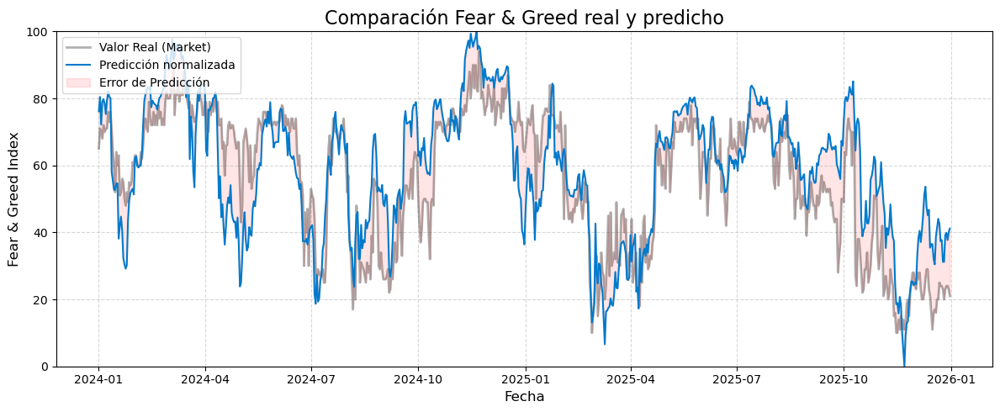

RMSE: 12.850266014251483
R2: 0.5835158273687906


In [468]:
# debido a que nuestro modelo es muy conservador y no logra detectar los puntos
# de mayor codicia o mayor miedo se va a proceder a normalizar 
from sklearn.preprocessing import MinMaxScaler
scaler_min_max = MinMaxScaler(feature_range=(0,100))
y_pred_reshaped = y_pred.reshape(-1, 1)
y_pred_norm = scaler_min_max.fit_transform(y_pred_reshaped)

plt.figure(figsize=(12, 5))

# fear & greed real
plt.plot(X_test.index, Y_test, color='black', label='Valor Real (Market)', alpha=0.3, linewidth=2)

# fear & greed propio
plt.plot(X_test.index, y_pred_norm.flatten(), color='#007acc', label='Predicción normalizada', linewidth=1.5)

# diferencia entre ambas (sombra)
plt.fill_between(X_test.index, Y_test, y_pred_norm.flatten(), color='red', alpha=0.1, label='Error de Predicción')


plt.title('Comparación Fear & Greed real y predicho', fontsize=16)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Fear & Greed Index', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

# rango eje Y
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

print("RMSE:", root_mean_squared_error(Y_test, y_pred_norm.flatten()))
print("R2:", r2_score(Y_test, y_pred_norm.flatten()))


### COMPARACIÓN DE ESTRATEGIAS 


In [471]:
# EN TODAS LAS ESTRATEGIAS SE VAN A PONER UN PRESUPUESTO DE 10.000€ Y LA ESTRATEGIA TERMINA EL 
# 31 DE DICIEMBRE DE 2025 QUE ES CUANDO TENEMOS EL ULTIMO DATO DISPONIBLE
# SE VAN A HACER UNA ESTRATEGIA DE COMPRA DE BTC Y OTRA DE ETH PARA VER COMO DE DIFERENTES SON
presupuesto = 10000
precio_final_btc = btc["Close"].loc["2025-12-31"]
precio_final_eth = eth["Close"].loc["2025-12-31"]
df_2024 = df.loc["2024-01-01":]

#### ESTRATEGIAS A LARGO PLAZO

##### DCA (2018-2026)

======================= BTC ======================= 

La cantidad invertida por mes ha sido 105.26315789473684
La cantidad de BTC comprado ha sido de 0.6613396819988876
El beneficio del Dollar Cost Average en Bitcoin es 47873.061
La rentabilidad es de 478.731%


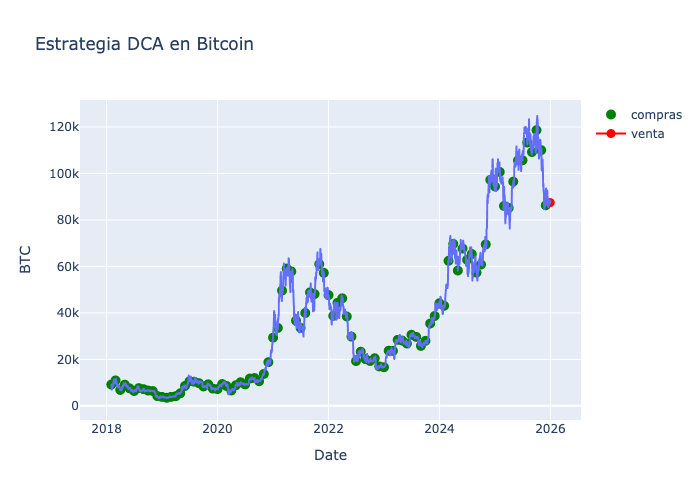

======================= ETH ======================= 

La cantidad invertida por mes ha sido 105.26315789473684
La cantidad de ETH comprado ha sido de 19.319998978815185
El beneficio del Dollar Cost Average en Ethereum es 47323.163
La rentabilidad es de 473.232%


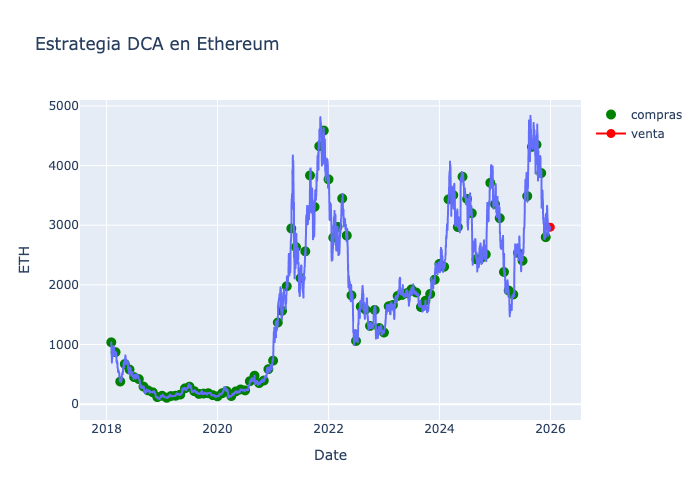

In [475]:
#DCA 2018-2026
# BTC
# creamos dataframe con las fechas de las compras
print("="*23, "BTC", "="*23, "\n")
compras_mensuales_btc_2018 = df.resample("MS").first()
num_cuotas_2018 = len(compras_mensuales_btc_2018)
cuota_btc_2018 = presupuesto / num_cuotas_2018
btc_acumulados_2018 = (cuota_btc_2018 / compras_mensuales_btc_2018["BTC"]).sum()

valor_final_dca_btc_2018 = btc_acumulados_2018 * precio_final_btc
beneficio_dca_btc_2018 = valor_final_dca_btc_2018 - presupuesto
rentabilidad_dca_btc_2018 = beneficio_dca_btc_2018 / presupuesto * 100
print(f"La cantidad invertida por mes ha sido {cuota_btc_2018}")
print(f"La cantidad de BTC comprado ha sido de {btc_acumulados_2018}")
print(f"El beneficio del Dollar Cost Average en Bitcoin es {beneficio_dca_btc_2018.round(3)}")
print(f"La rentabilidad es de {rentabilidad_dca_btc_2018.round(3)}%")

# representación visual
dca_btc_2018 = px.line(df, 
                  x = df.index, 
                  y = df["BTC"], 
                  title = "Estrategia DCA en Bitcoin")
dca_btc_2018.add_scatter(x = compras_mensuales_btc_2018.index,
                    y = compras_mensuales_btc_2018["BTC"],
                    mode = "markers",
                    marker = dict(size = 10,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
dca_btc_2018.add_scatter(x = ["2025-12-31"],
                    y =  [precio_final_btc],
                    marker = dict(size = 9,
                                  color = "red",
                                  symbol = "circle"),
                                  name = "venta")
dca_btc_2018.show()

# ETH 
print("="*23, "ETH", "="*23, "\n")
compras_mensuales_eth_2018 = df.resample("MS").first()
num_cuotas_2018 = len(compras_mensuales_eth_2018)
cuota_eth_2018 = presupuesto / num_cuotas_2018
eth_acumulados_2018 = (cuota_eth_2018 / compras_mensuales_eth_2018["ETH"]).sum()

valor_final_dca_eth_2018 = eth_acumulados_2018 * precio_final_eth
beneficio_dca_eth_2018 = valor_final_dca_eth_2018 - presupuesto
rentabilidad_dca_eth_2018 = beneficio_dca_eth_2018 / presupuesto * 100

print(f"La cantidad invertida por mes ha sido {cuota_eth_2018}")
print(f"La cantidad de ETH comprado ha sido de {eth_acumulados_2018}")
print(f"El beneficio del Dollar Cost Average en Ethereum es {beneficio_dca_eth_2018.round(3)}")
print(f"La rentabilidad es de {rentabilidad_dca_eth_2018.round(3)}%")


dca_eth_2018 = px.line(df, 
                  x = df.index, 
                  y = df["ETH"], 
                  title = "Estrategia DCA en Ethereum")
dca_eth_2018.add_scatter(x = compras_mensuales_eth_2018.index,
                    y = compras_mensuales_eth_2018["ETH"],
                    mode = "markers",
                    marker = dict(size = 10,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
dca_eth_2018.add_scatter(x = ["2025-12-31"],
                    y =  [precio_final_eth],
                    marker = dict(size = 9,
                                  color = "red",
                                  symbol = "circle"),
                                  name = "venta")
dca_eth_2018.show()


##### FEAR & GREED & HOLD (2018-2026)

======================= BTC ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 17.88908765652952
La cantidad de BTC comprado ha sido de 0.9059700981806474
El beneficio del Fear & Greed & Hold en Bitcoin es 69280.382
La rentabilidad es de 692.804%


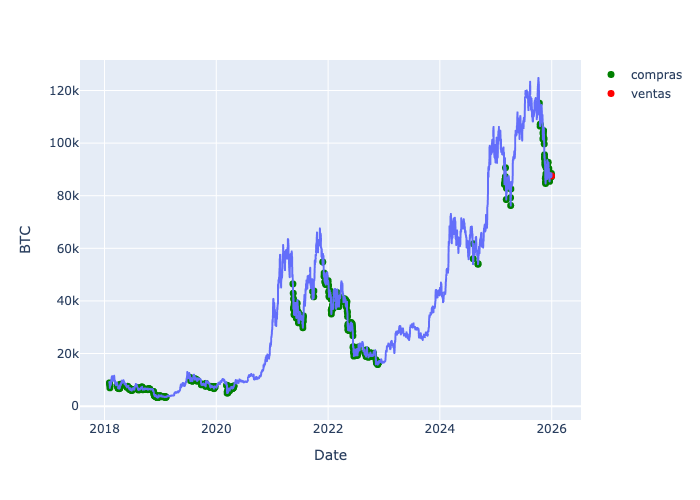

======================= ETH ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 17.88908765652952
La cantidad de ETH comprado ha sido de 27.240021631367195
El beneficio del Fear & Greed & Hold en Ethereum es 70822.168
La rentabilidad es de 708.222%


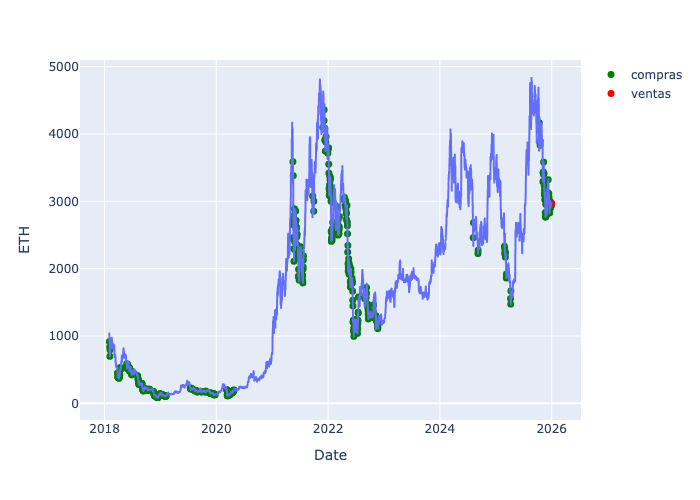

In [478]:
# A. FEAR & GREED & HOLD
print("="*23, "BTC", "="*23, "\n")
compras_real_btc_2018 = df[df["f&g_index"] < 25]
cant_compras_real_btc_2018 = df[df["f&g_index"] < 25].shape[0]
dinero_por_compra_real_btc_2018 = presupuesto / cant_compras_real_btc_2018
cantidad_btc_real_2018 = (dinero_por_compra_real_btc_2018 / compras_real_btc_2018["BTC"]).sum()
beneficio_real_btc_2018 = precio_final_btc * cantidad_btc_real_2018 - presupuesto
rentabilidad_real_btc_2018 = (beneficio_real_btc_2018 / presupuesto) * 100
print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_real_btc_2018}")
print(f"La cantidad de BTC comprado ha sido de {cantidad_btc_real_2018}")
print(f"El beneficio del Fear & Greed & Hold en Bitcoin es {beneficio_real_btc_2018.round(3)}")
print(f"La rentabilidad es de {rentabilidad_real_btc_2018.round(3)}%")


fig_real_btc_2018 = px.line(df,
                   x = df.index,
                   y = df["BTC"])
fig_real_btc_2018.add_scatter( x = compras_real_btc_2018.index,
                      y = compras_real_btc_2018["BTC"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_real_btc_2018.add_scatter( x = ["2025-12-31"],
                      y = [precio_final_btc],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_real_btc_2018.show()


print("="*23, "ETH", "="*23, "\n")
compras_real_eth_2018 = df[df["f&g_index"] < 25]
cant_compras_real_eth_2018 = df[df["f&g_index"] < 25].shape[0]
dinero_por_compra_real_eth_2018 = presupuesto / cant_compras_real_eth_2018
cantidad_eth_real_2018 = (dinero_por_compra_real_eth_2018 / compras_real_eth_2018["ETH"]).sum()
beneficio_real_eth_2018 = precio_final_eth * cantidad_eth_real_2018 - presupuesto
rentabilidad_real_eth_2018 = (beneficio_real_eth_2018 / presupuesto) * 100
print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_real_eth_2018}")
print(f"La cantidad de ETH comprado ha sido de {cantidad_eth_real_2018}")
print(f"El beneficio del Fear & Greed & Hold en Ethereum es {beneficio_real_eth_2018.round(3)}")
print(f"La rentabilidad es de {rentabilidad_real_eth_2018.round(3)}%")


fig_real_eth_2018 = px.line(df,
                   x = df.index,
                   y = df["ETH"])
fig_real_eth_2018.add_scatter( x = compras_real_eth_2018.index,
                      y = compras_real_eth_2018["ETH"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_real_eth_2018.add_scatter( x = ["2025-12-31"],
                      y = [precio_final_eth],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_real_eth_2018.show()

### ESTRATEGIAS EN PERIODO DE TEST (2024-2025)

##### COMPRA ÚNICA EN FEBRERO DE 2024

======================= BTC ======================= 

El dinero invertido en esta estrategia es 10000€
La cantidad de BTC comprado ha sido de 0.23214905275024988
El beneficio ha sido de 10315.092€
La rentabilidad ha sido de 103.151%


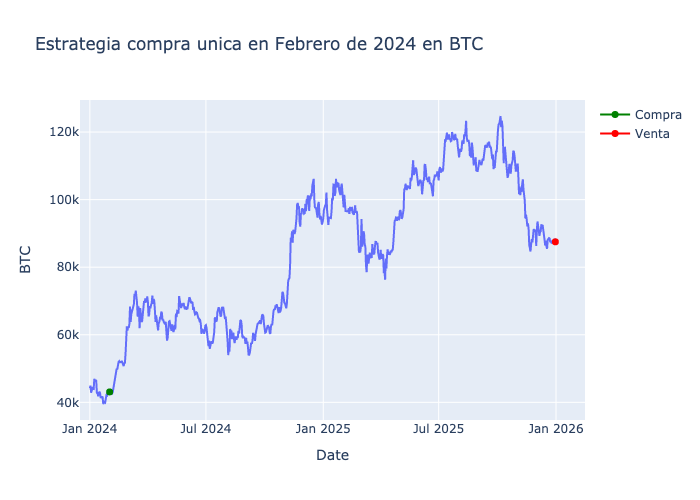

======================= ETH ======================= 

El dinero invertido en esta estrategia es 10000€
La cantidad de ETH comprado ha sido de 4.340608019993926
El beneficio ha sido de 2878.747€
La rentabilidad ha sido de 28.787%


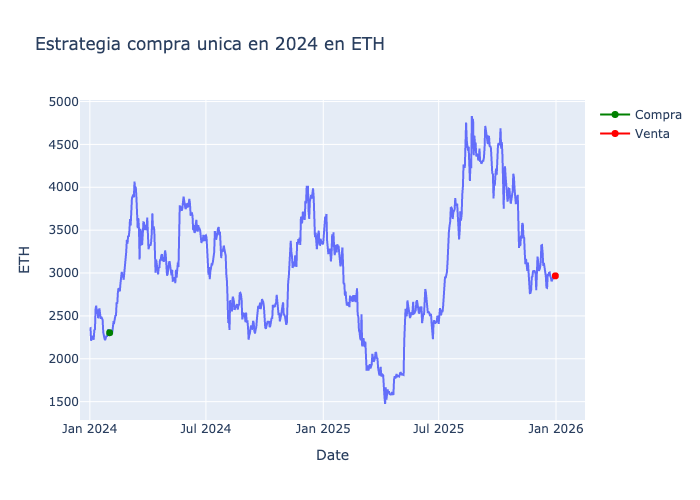

In [482]:
# UNICA COMPRA (febrero 2024)
#BTC
print("="*23, "BTC", "="*23, "\n")
precio_inicio_2024_btc = btc['Close'].loc['2024-02-01']
btc_comprados_2024_btc = presupuesto / precio_inicio_2024_btc
beneficio_2024_btc = precio_final_btc * btc_comprados_2024_btc - presupuesto
rentabilidad_2024_btc = beneficio_2024_btc / presupuesto * 100
print(f"El dinero invertido en esta estrategia es {presupuesto}€")
print(f"La cantidad de BTC comprado ha sido de {btc_comprados_2024_btc}")
print(f"El beneficio ha sido de {beneficio_2024_btc.round(3)}€")
print(f"La rentabilidad ha sido de {rentabilidad_2024_btc.round(3)}%")

fig_btc_2024 = px.line(df_2024,
                       x = df_2024.index,
                       y = df_2024["BTC"],
                       title = "Estrategia compra unica en Febrero de 2024 en BTC")
fig_btc_2024.add_scatter( x = ["2024-02-01"],
                          y = [btc["Close"].loc["2024-02-01"]],
                          marker = dict( size = 7,
                                         color = "green",
                                         symbol = "circle"),
                         name = "Compra")
fig_btc_2024.add_scatter( x = ["2025-12-31"],
                          y = [precio_final_btc],
                          marker = dict( size = 7,
                                         color = "red",
                                         symbol = "circle"),
                         name = "Venta")
fig_btc_2024.show()

# ETH
print("="*23, "ETH", "="*23, "\n")
precio_inicio_2024_eth = eth['Close'].loc['2024-02-01']
eth_comprados_2024_eth = presupuesto / precio_inicio_2024_eth
beneficio_2024_eth = precio_final_eth * eth_comprados_2024_eth - presupuesto
rentabilidad_2024_eth = beneficio_2024_eth / presupuesto * 100
print(f"El dinero invertido en esta estrategia es {presupuesto}€")
print(f"La cantidad de ETH comprado ha sido de {eth_comprados_2024_eth}")
print(f"El beneficio ha sido de {beneficio_2024_eth.round(3)}€")
print(f"La rentabilidad ha sido de {rentabilidad_2024_eth.round(3)}%")

fig_eth_2024 = px.line(df_2024,
                       x = df_2024.index,
                       y = df_2024["ETH"],
                       title = "Estrategia compra unica en 2024 en ETH")
fig_eth_2024.add_scatter( x = ["2024-02-01"],
                          y = [df_2024["ETH"].loc["2024-02-01"]],
                          marker = dict( size = 7,
                                         color = "green",
                                         symbol = "circle"),
                         name = "Compra")
fig_eth_2024.add_scatter( x = ["2025-12-31"],
                          y = [precio_final_eth],
                          marker = dict( size = 7,
                                         color = "red",
                                         symbol = "circle"),
                         name = "Venta")
fig_eth_2024.show()


##### COMPRA ÚNICA EN DICIEMBRE DE 2024

======================= BTC ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad de BTC comprado ha sido de 0.10794099102141777
El beneficio ha sido de -554.2103690645836€
La rentabilidad ha sido de -5.542103690645836%


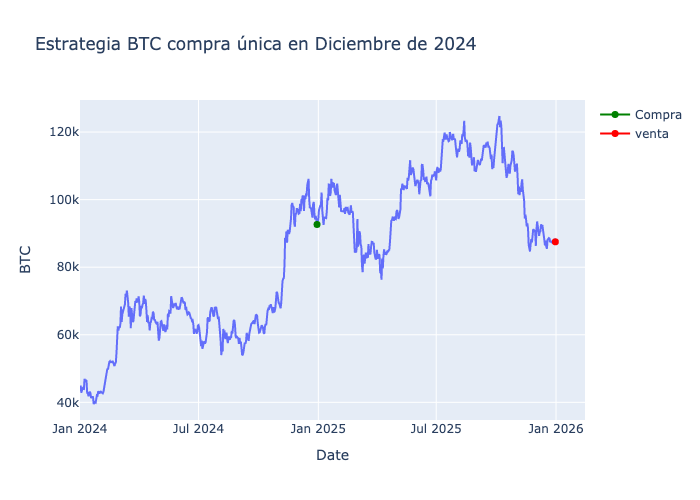

======================= ETH ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad de ETH comprado ha sido de 2.979389260116394
El beneficio ha sido de -1160.0400471814228€
La rentabilidad ha sido de -11.600400471814227%


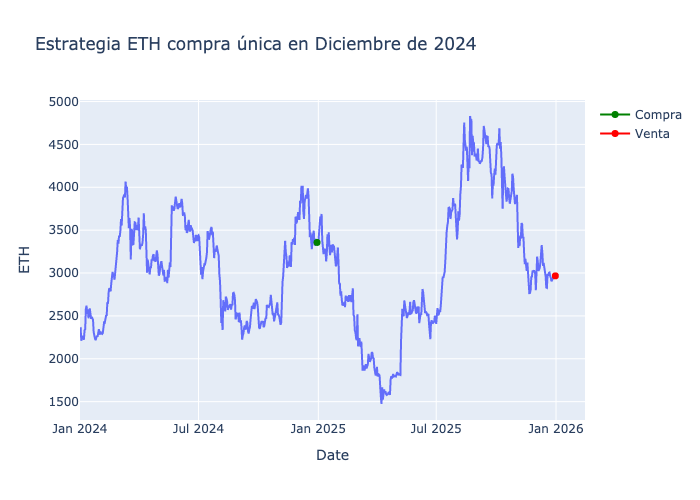

In [485]:
# UNICA COMPRA (30 de Diciembre 2024)
#BTC
print("="*23, "BTC", "="*23, "\n")
precio_inicio_2025_btc = btc['Close'].loc['2024-12-30']
btc_comprados_2025_btc = presupuesto / precio_inicio_2025_btc
beneficio_2025_btc = precio_final_btc * btc_comprados_2025_btc - presupuesto
rentabilidad_2025_btc = beneficio_2025_btc / presupuesto * 100
print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad de BTC comprado ha sido de {btc_comprados_2025_btc}")
print(f"El beneficio ha sido de {beneficio_2025_btc}€")
print(f"La rentabilidad ha sido de {rentabilidad_2025_btc}%")

# representación visual
fig_btc_2025 = px.line(df_2024, 
                       x = df_2024.index, 
                       y = df_2024["BTC"], 
                       title = "Estrategia BTC compra única en Diciembre de 2024")
fig_btc_2025.add_scatter(x = ["2024-12-30"],
                         y = [precio_inicio_2025_btc],
                         marker=dict(size=7, color='green', symbol='circle'),
                         name = "Compra")
fig_btc_2025.add_scatter(x = ["2025-12-31"],
                         y = [precio_final_btc],
                         marker=dict(size=7, color='red', symbol='circle'),
                         name = "venta")
                         
fig_btc_2025.show()


# ETH
print("="*23, "ETH", "="*23, "\n")
precio_inicio_2025_eth = eth['Close'].loc['2024-12-30']
eth_comprados_2025_eth = presupuesto / precio_inicio_2025_eth
beneficio_2025_eth = precio_final_eth * eth_comprados_2025_eth - presupuesto
rentabilidad_2025_eth = beneficio_2025_eth / presupuesto * 100
print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad de ETH comprado ha sido de {eth_comprados_2025_eth}")
print(f"El beneficio ha sido de {beneficio_2025_eth}€")
print(f"La rentabilidad ha sido de {rentabilidad_2025_eth}%")

# representación visual
fig_eth_2025 = px.line(df_2024, 
                       x = df_2024.index, 
                       y = df_2024["ETH"], 
                       title = "Estrategia ETH compra única en Diciembre de 2024")
fig_eth_2025.add_scatter(x = ["2024-12-30"],
                         y = [precio_inicio_2025_eth],
                         marker=dict(size=7, color='green', symbol='circle'),
                         name = "Compra")
fig_eth_2025.add_scatter(x = ["2025-12-31"],
                         y = [precio_final_eth],
                         marker=dict(size=7, color='red', symbol='circle'),
                         name = "Venta")
                         
fig_eth_2025.show()

##### DOLLAR COST AVERAGE 

======================= BTC ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por mes ha sido 416.6666666666667
La cantidad de BTC comprado ha sido de 0.13257269754678289
El beneficio del Dollar Cost Average en Bitcoin es 1601.281
La rentabilidad es de 16.013%


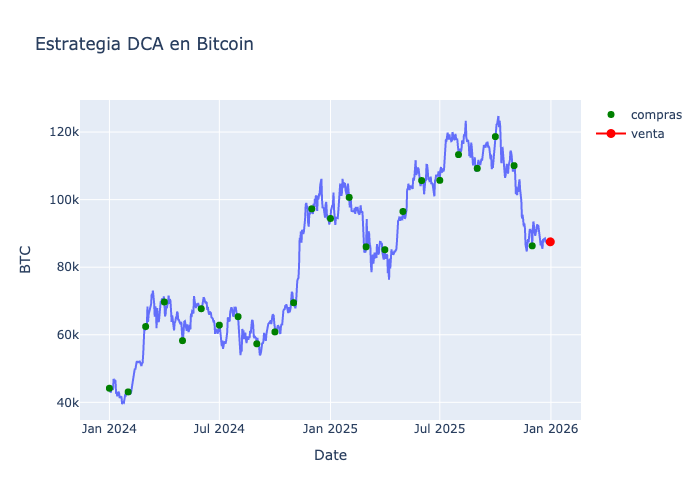

======================= ETH ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por mes ha sido 416.6666666666667
La cantidad de BTC comprado ha sido de 3.515557697912648
El beneficio del Dollar Cost Average en Ethereum es 430.792
La rentabilidad es de 4.308%


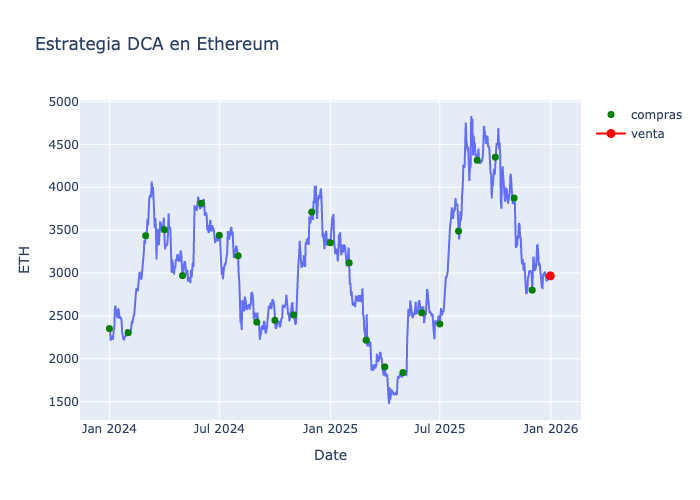

In [488]:
# DOLLAR COST AVERAGE MENSUAL, COMPRAMOS MES A MES SIENDO EL ULTIMO MES DICIEMBRE 
# DE 2025 Y VENDEMOS EL 31 DE DICIEMBRE DE 2025

# BTC
# creamos dataframe con las fechas de las compras
print("="*23, "BTC", "="*23, "\n")
compras_mensuales_btc = df_2024.resample("MS").first()
num_cuotas = len(compras_mensuales_btc)
cuota_btc = presupuesto / num_cuotas
btc_acumulados = (cuota_btc / compras_mensuales_btc["BTC"]).sum()

valor_final_dca_btc = btc_acumulados * precio_final_btc
beneficio_dca_btc = valor_final_dca_btc - presupuesto
rentabilidad_dca_btc = beneficio_dca_btc / presupuesto * 100
print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por mes ha sido {cuota_btc}")
print(f"La cantidad de BTC comprado ha sido de {btc_acumulados}")
print(f"El beneficio del Dollar Cost Average en Bitcoin es {beneficio_dca_btc.round(3)}")
print(f"La rentabilidad es de {rentabilidad_dca_btc.round(3)}%")

# representación visual
dca_btc = px.line(df_2024, 
                  x = df_2024.index, 
                  y = df_2024["BTC"], 
                  title = "Estrategia DCA en Bitcoin")
dca_btc.add_scatter(x = compras_mensuales_btc.index,
                    y = compras_mensuales_btc["BTC"],
                    mode = "markers",
                    marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
dca_btc.add_scatter(x = ["2025-12-31"],
                    y =  [precio_final_btc],
                    marker = dict(size = 9,
                                  color = "red",
                                  symbol = "circle"),
                                  name = "venta")
dca_btc.show()

# ETH 
print("="*23, "ETH", "="*23, "\n")
compras_mensuales_eth = df_2024.resample("MS").first()
num_cuotas = len(compras_mensuales_eth)
cuota_eth = presupuesto / num_cuotas
eth_acumulados = (cuota_eth / compras_mensuales_eth["ETH"]).sum()

valor_final_dca_eth = eth_acumulados * precio_final_eth
beneficio_dca_eth = valor_final_dca_eth - presupuesto
rentabilidad_dca_eth = beneficio_dca_eth / presupuesto * 100

print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por mes ha sido {cuota_eth}")
print(f"La cantidad de BTC comprado ha sido de {eth_acumulados}")
print(f"El beneficio del Dollar Cost Average en Ethereum es {beneficio_dca_eth.round(3)}")
print(f"La rentabilidad es de {rentabilidad_dca_eth.round(3)}%")


dca_eth = px.line(df_2024, 
                  x = df_2024.index, 
                  y = df_2024["ETH"], 
                  title = "Estrategia DCA en Ethereum")
dca_eth.add_scatter(x = compras_mensuales_eth.index,
                    y = compras_mensuales_eth["ETH"],
                    mode = "markers",
                    marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
dca_eth.add_scatter(x = ["2025-12-31"],
                    y =  [precio_final_eth],
                    marker = dict(size = 9,
                                  color = "red",
                                  symbol = "circle"),
                                  name = "venta")
dca_eth.show()


##### FEAR & GREED & HOLD (REAL Y PREDICHO)

======================= BTC (REAL) ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 82.64462809917356
La cantidad de BTC comprado ha sido de 0.1254829692617732
El beneficio del Fear & Greed (Real) & Hold en Bitcoin es 980.868
La rentabilidad es de 9.809%


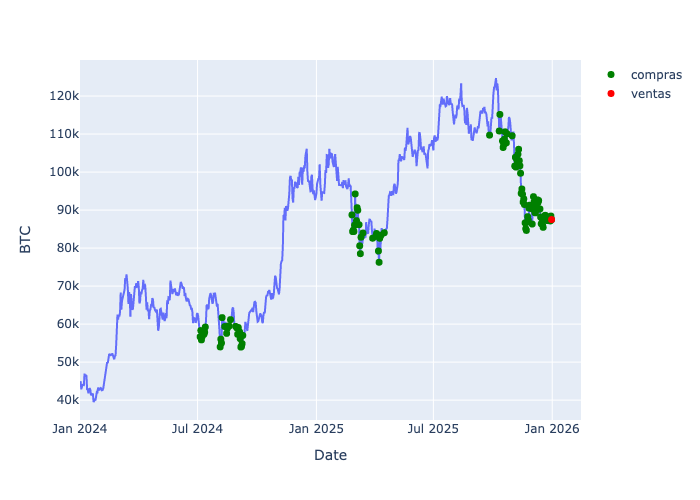

======================= ETH (REAL) ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 82.64462809917356
La cantidad de ETH comprado ha sido de 3.6759660904605638
El beneficio del Fear & Greed (Real) & Hold en Ethereum es 906.73
La rentabilidad es de 9.067%


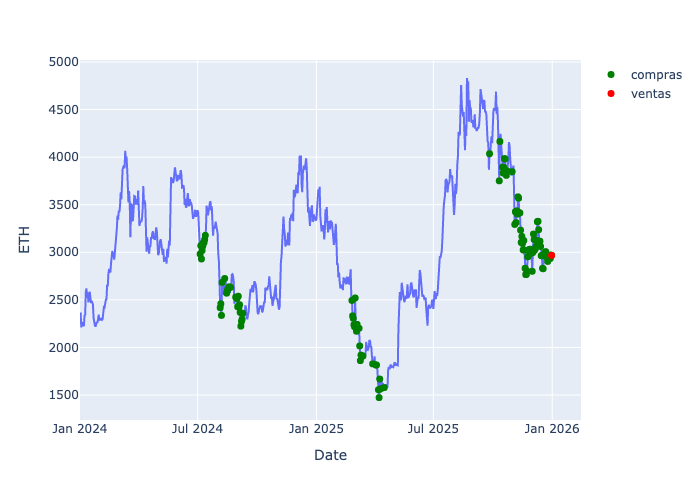

======================= BTC (PREDICHO) ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 222.22222222222223
La cantidad de BTC comprado ha sido de 0.12459789402968917
El beneficio del Fear & Greed (Predicho) & Hold en Bitcoin es 903.416
La rentabilidad es de 9.034%


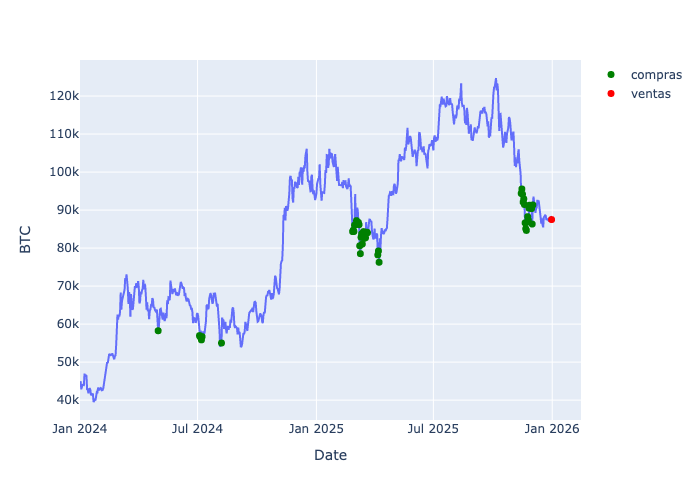

======================= ETH (PREDICHO) ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 222.22222222222223
La cantidad de ETH comprado ha sido de 4.2608080882797745
El beneficio del Fear & Greed (Predicho) & Hold en Ethereum es 2641.978
La rentabilidad es de 26.42%


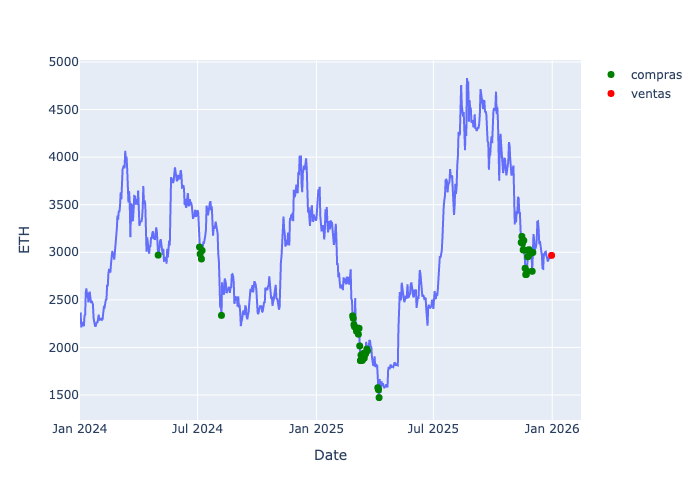

In [491]:
# A. FEAR & GREED REAL

# BTC
print("="*23, "BTC (REAL)", "="*23, "\n")
compras_real_btc = df_2024[df_2024["f&g_index"] < 30]
cant_compras_real_btc = df_2024[df_2024["f&g_index"] < 30].shape[0]
dinero_por_compra_real_btc = presupuesto / cant_compras_real_btc
cantidad_btc_real = (dinero_por_compra_real_btc / compras_real_btc["BTC"]).sum()
beneficio_real_btc = precio_final_btc * cantidad_btc_real - presupuesto
rentabilidad_real_btc = (beneficio_real_btc / presupuesto) * 100

print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_real_btc}")
print(f"La cantidad de BTC comprado ha sido de {cantidad_btc_real}")
print(f"El beneficio del Fear & Greed (Real) & Hold en Bitcoin es {beneficio_real_btc.round(3)}")
print(f"La rentabilidad es de {rentabilidad_real_btc.round(3)}%")


fig_real_btc = px.line(df_2024,
                   x = df_2024.index,
                   y = df_2024["BTC"])
fig_real_btc.add_scatter( x = compras_real_btc.index,
                      y = compras_real_btc["BTC"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_real_btc.add_scatter( x = ["2025-12-31"],
                      y = [precio_final_btc],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_real_btc.show()


# ETH
print("="*23, "ETH (REAL)", "="*23, "\n")
compras_real_eth = df_2024[df_2024["f&g_index"] < 30]
cant_compras_real_eth = df_2024[df_2024["f&g_index"] < 30].shape[0]
dinero_por_compra_real_eth = presupuesto / cant_compras_real_eth
cantidad_eth_real = (dinero_por_compra_real_eth / compras_real_eth["ETH"]).sum()
beneficio_real_eth = precio_final_eth * cantidad_eth_real - presupuesto
rentabilidad_real_eth = (beneficio_real_eth / presupuesto) * 100

print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_real_eth}")
print(f"La cantidad de ETH comprado ha sido de {cantidad_eth_real}")
print(f"El beneficio del Fear & Greed (Real) & Hold en Ethereum es {beneficio_real_eth.round(3)}")
print(f"La rentabilidad es de {rentabilidad_real_eth.round(3)}%")


fig_real_eth = px.line(df_2024,
                   x = df_2024.index,
                   y = df_2024["ETH"])
fig_real_eth.add_scatter( x = compras_real_eth.index,
                      y = compras_real_eth["ETH"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_real_eth.add_scatter( x = ["2025-12-31"],
                      y = [precio_final_eth],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_real_eth.show()




# B. FEAR & GREED SINTÉTICO

df_2024_pred = df_2024.copy() # creamos dataframe para añadir variable predicha
df_2024_pred = df_2024_pred.drop("f&g_index", axis = 1)
df_2024_pred["f&g_index_pred"] = y_pred_norm

# BITCOIN 
print("="*23, "BTC (PREDICHO)", "="*23, "\n")
compras_pred_btc = df_2024_pred[df_2024_pred["f&g_index_pred"] < 25]
cant_compras_pred_btc = df_2024_pred[df_2024_pred["f&g_index_pred"] < 25].shape[0]
dinero_por_compra_pred_btc = presupuesto / cant_compras_pred_btc
cantidad_btc_pred = (dinero_por_compra_pred_btc / compras_pred_btc["BTC"]).sum()
beneficio_pred_btc = precio_final_btc * cantidad_btc_pred - presupuesto
rentabilidad_pred_btc = (beneficio_pred_btc / presupuesto) * 100

print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_pred_btc}")
print(f"La cantidad de BTC comprado ha sido de {cantidad_btc_pred}")
print(f"El beneficio del Fear & Greed (Predicho) & Hold en Bitcoin es {beneficio_pred_btc.round(3)}")
print(f"La rentabilidad es de {rentabilidad_pred_btc.round(3)}%")


fig_pred_btc = px.line(df_2024_pred,
                   x = df_2024_pred.index,
                   y = df_2024_pred["BTC"])
fig_pred_btc.add_scatter( x = compras_pred_btc.index,
                      y = compras_pred_btc["BTC"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_pred_btc.add_scatter( x = ["2025-12-31"],
                      y = [precio_final_btc],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_pred_btc.show()

# ETHEREUM 
print("="*23, "ETH (PREDICHO)", "="*23, "\n")
compras_real_eth = df_2024_pred[df_2024_pred["f&g_index_pred"] < 25]
cant_compras_real_eth = df_2024_pred[df_2024_pred["f&g_index_pred"] < 25].shape[0]
dinero_por_compra_real_eth = presupuesto / cant_compras_real_eth
cantidad_eth_real = (dinero_por_compra_real_eth / compras_real_eth["ETH"]).sum()
beneficio_real_eth = (precio_final_eth * cantidad_eth_real) - presupuesto
rentabilidad_real_eth = (beneficio_real_eth / presupuesto) * 100

print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_real_eth}")
print(f"La cantidad de ETH comprado ha sido de {cantidad_eth_real}")
print(f"El beneficio del Fear & Greed (Predicho) & Hold en Ethereum es {beneficio_real_eth.round(3)}")
print(f"La rentabilidad es de {rentabilidad_real_eth.round(3)}%")


fig_real_eth = px.line(df_2024_pred,
                   x = df_2024_pred.index,
                   y = df_2024_pred["ETH"])
fig_real_eth.add_scatter( x = compras_real_eth.index,
                      y = compras_real_eth["ETH"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_real_eth.add_scatter( x = ["2025-12-31"],
                      y = [precio_final_eth],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_real_eth.show()



##### ESTRATEGIA DE COMPRA EN MIEDO Y VENTA EN CODICIA (MODELO PREDICHO)

======================= BTC ======================= 

La cantidad con la que se ha empezado es 10000€
Beneficio de BTC: 3549.138514213062
La rentabilidad de esta estrategia en BTC ha sido 35.491%


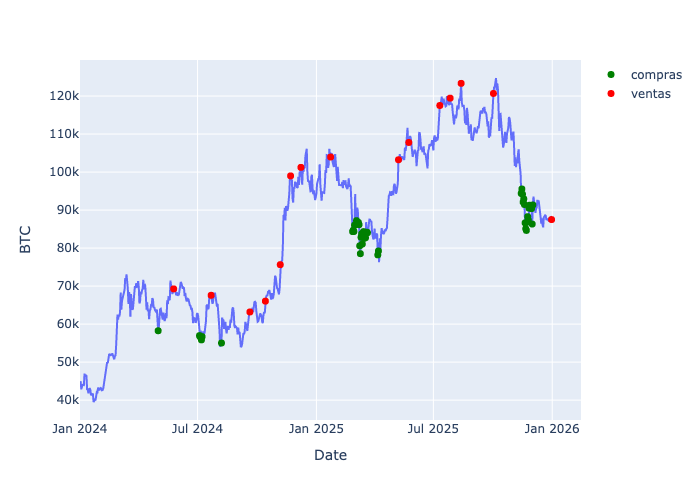

======================= ETH ======================= 

La cantidad con la que se ha empezado es 10000€
Beneficio de ETH: 3299.6976893327337
La rentabilidad de esta estrategia en ETH ha sido 32.997%


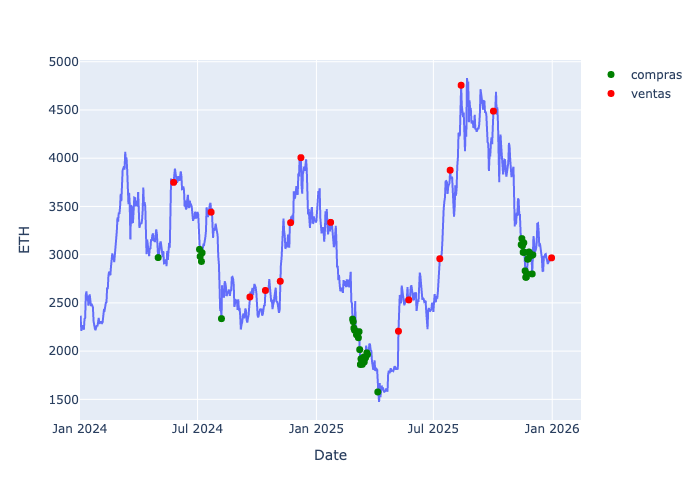

In [494]:
# CONSTRUCCIÓN DE ESTRATEGIA QUE COMPRE 500€ POR OPERACIÓN CUANDO EL MODELO ESTE POR DEBAJO DE 25 (MIEDO)
# SIEMPRE Y CUANDO HAYA EFECTIVO (10000€) Y QUE VENDA EL 50% EN CODICIA (SOLO CUANDO EN LOS 7 DÍAS ANTERIORES 
# EL MODELO NO HAYA INDICADO CODICIA TAMBIÉN) Y MANTENGA EL RESTANTE
# NOTA: SE HA AGREGADO LO DE QUE NO VENDA SI EN LOS 7 ÚLTIMOS DÍAS HA INDICADO CODICIA YA QUE SI HAY UN PERIODO
# CON MUCHA CODICIA SEGUIDO LA ESTRATEGIA SE QUEDA SIN DINERO INVERTIDO.


fechas_compra, precios_compra = [], []
fechas_venta, precios_venta = [], []
balance_efectivo = 10000
posicion_btc = 0
inversion_fija = 500
dias_sin_euforia = 8

#BTC
print("="*23, "BTC", "="*23, "\n")
for i in range(len(df_2024_pred)):
    dias_sin_euforia += 1
    precio = df_2024_pred["BTC"].iloc[i]
    sentimiento = df_2024_pred["f&g_index_pred"].iloc[i]
    fecha = df_2024_pred.index[i]
    
    if sentimiento < 25 and balance_efectivo >= inversion_fija:
        posicion_btc += inversion_fija / precio
        balance_efectivo -= inversion_fija
        # Guardamos en listas
        fechas_compra.append(fecha)
        precios_compra.append(precio)
            
    elif sentimiento > 75 and posicion_btc > 0 and dias_sin_euforia > 15:
        balance_efectivo += posicion_btc * 0.5 * precio
        posicion_btc *= 0.5
        dias_sin_euforia = 0
        # Guardamos en listas
        fechas_venta.append(fecha)
        precios_venta.append(precio)

if posicion_btc > 0:
    balance_efectivo += posicion_btc * precio_final_btc
    posicion_btc = 0
    # Opcional: registrar esta venta final en las listas para el gráfico
    fechas_venta.append(df_2024_pred.index[-1])
    precios_venta.append(precio_final_btc)
beneficio_btc = balance_efectivo - presupuesto
rentabilidad_btc = beneficio_btc / presupuesto * 100

print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"Beneficio de BTC: {beneficio_btc}")
print(f"La rentabilidad de esta estrategia en BTC ha sido {rentabilidad_btc.round(3)}%") 

df_compras_estrategia_btc = pd.DataFrame({"Fecha":fechas_compra,"Precio":precios_compra})
df_ventas_estrategia_btc = pd.DataFrame({"Fecha":fechas_venta,"Precio":precios_venta})

fig_swing_btc = px.line(df_2024_pred,
                        x = df_2024_pred.index,
                        y = df_2024_pred["BTC"])
fig_swing_btc.add_scatter(x = df_compras_estrategia_btc["Fecha"],
                      y = df_compras_estrategia_btc["Precio"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_swing_btc.add_scatter(x = df_ventas_estrategia_btc["Fecha"],
                      y = df_ventas_estrategia_btc["Precio"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
fig_swing_btc.show()
# ETH 
print("="*23, "ETH", "="*23, "\n")

dias_sin_euforia = 15
posicion_eth = 0
balance_efectivo_eth = 10000
fechas_compra_eth, precios_compra_eth = [], []
fechas_venta_eth, precios_venta_eth = [], []

for i in range(len(df_2024_pred)):
    dias_sin_euforia += 1
    precio_eth = df_2024_pred["ETH"].iloc[i]
    sentimiento = df_2024_pred["f&g_index_pred"].iloc[i]
    fecha = df_2024_pred.index[i]
    
    if sentimiento < 25 and balance_efectivo_eth >= inversion_fija:
        posicion_eth += inversion_fija / precio_eth
        balance_efectivo_eth -= inversion_fija
        # Guardamos en listas
        fechas_compra_eth.append(fecha)
        precios_compra_eth.append(precio_eth)
            
    elif sentimiento > 75 and posicion_eth > 0 and dias_sin_euforia > 15:
        balance_efectivo_eth += posicion_eth * 0.5 * precio_eth
        posicion_eth *= 0.5
        dias_sin_euforia = 0
        # Guardamos en listas
        fechas_venta_eth.append(fecha)
        precios_venta_eth.append(precio_eth)

if posicion_eth > 0:
    balance_efectivo_eth += posicion_eth * precio_final_eth
    posicion_eth = 0
    # Opcional: registrar esta venta final en las listas para el gráfico
    fechas_venta_eth.append(df_2024_pred.index[-1])
    precios_venta_eth.append(precio_final_eth)

beneficio_eth = balance_efectivo_eth - presupuesto
rentabilidad_eth = beneficio_eth / presupuesto * 100

print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"Beneficio de ETH: {beneficio_eth}")
print(f"La rentabilidad de esta estrategia en ETH ha sido {rentabilidad_eth.round(3)}%")           
        
df_compras_estrategia_eth = pd.DataFrame({"Fecha":fechas_compra_eth,"Precio":precios_compra_eth})
df_ventas_estrategia_eth = pd.DataFrame({"Fecha":fechas_venta_eth,"Precio":precios_venta_eth})

fig_swing_eth = px.line(df_2024_pred,
                        x = df_2024_pred.index,
                        y = df_2024_pred["ETH"])
fig_swing_eth.add_scatter(x = df_compras_estrategia_eth["Fecha"],
                      y = df_compras_estrategia_eth["Precio"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_swing_eth.add_scatter(x = df_ventas_estrategia_eth["Fecha"],
                      y = df_ventas_estrategia_eth["Precio"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")            
fig_swing_eth.show()
    

# FEAR AND GREED EN MERCADOS TRADICIONALES

# S&P 500

#### ANÁLISIS EXPLORATORIO 

### CONSTRUCCIÓN DEL DATAFRAME PARA EL ÍNDICE SINTETICO PARA EL S&P500

In [504]:
# vamos a añadir un tipo de búsqueda a este mercado sacada de Google Trends

sp500_busqueda_1 = pd.read_csv("../data/google_trends/sp500-2018-2022.csv")
sp500_busqueda_2 = pd.read_csv("../data/google_trends/sp500-2022-2025.csv")
sp500_busqueda_1 = sp500_busqueda_1.iloc[1:]
sp500_busqueda_2 = sp500_busqueda_2.iloc[1:]
sp500_busqueda_1 = sp500_busqueda_1.rename(columns={"Categoría: Todas las categorías":"sp500_busqueda"})
sp500_busqueda_2 = sp500_busqueda_2.rename(columns={"Categoría: Todas las categorías":"sp500_busqueda"})
sp500_busqueda_1.index.name = "Date" # ponemos el nombre del index en todos
sp500_busqueda_1.index = pd.to_datetime(sp500_busqueda_1.index)
sp500_busqueda_2.index.name = "Date" # ponemos el nombre del index en todos
sp500_busqueda_2.index = pd.to_datetime(sp500_busqueda_2.index)
sp500_busqueda_1["sp500_busqueda"] = pd.to_numeric(sp500_busqueda_1["sp500_busqueda"], errors='coerce')
sp500_busqueda_2["sp500_busqueda"] = pd.to_numeric(sp500_busqueda_2["sp500_busqueda"], errors='coerce')

#escalamos
factor_sp500 = sp500_busqueda_1["sp500_busqueda"].iloc[-1] / sp500_busqueda_2["sp500_busqueda"].iloc[0] # Factor de empalme 1
sp500_busqueda_2_scaled = sp500_busqueda_2["sp500_busqueda"] * factor_btc # hacemos factor para empalmar
sp500_busqueda = pd.concat([sp500_busqueda_1["sp500_busqueda"],sp500_busqueda_2_scaled])

#dataframe
df_sp500_busqueda = sp500_busqueda.to_frame(name="sp500_busqueda")
df_sp500_busqueda.index = pd.to_datetime(df_sp500_busqueda.index, format="%d-%m-%Y")
df_sp500_busqueda = df_sp500_busqueda[~df_sp500_busqueda.index.duplicated(keep='first')] # borramos los duplicados 
df_sp500_busqueda = df_sp500_busqueda.resample('D').ffill() #convertimos en diario el semanal
df_sp500_busqueda = df_sp500_busqueda.loc["2018-02-01":"2025-12-31"]

df_sp500_busqueda.tail()

,sp500_busqueda
Date,
2025-12-24,26.962963
2025-12-25,26.962963
2025-12-26,26.962963
2025-12-27,26.962963
2025-12-28,27.925926


In [506]:
### CONSTRUCCIÓN DEL DATAFRAME DEL SP500 EN EL MISMO ORDEN DE LAS VARIABLES DEL DATAFRAME DE CRYPTO PARA HACER DESPUÉS UN TRANSFER LEARNING
df_sp500 = pd.DataFrame()
df_sp500["BTC"] = df["BTC"]
df_sp500["ETH"] = df["ETH"]
df_sp500["SP500"] = df["SP500"]
df_sp500["GOLD"] = df["GOLD"]
df_sp500["volumen_acum_diario"] = sp500["Volume"]
df_sp500["volatilidad_med_diaria"] = (sp500["High"] - sp500["Low"]) / sp500["Close"]
# dominancia de bitcoin (luego se puede cambiar por gold/silver o algo así). Vamos a ver como funciona
df_sp500["dominancia_bitcoin"] = df["dominancia_bitcoin"]
df_sp500["sent_alcista"] = survey_sentiments["Bullish"]
# se procede a añadir las busquedas sacadas de google trends, vamos a dejar la variable de "bitcoin" igual para añadir al modelo
# algo más de volatilidad, ya que en el pasado todos nuestros modelos han sido demasiado conservadores y vamos a añadir
# la busqueda de "s&p500"
df_sp500["btc_busqueda"] = df["btc_busqueda"] # la misma que en crypto
# la variable crypto_busqueda se ha cambiado por "sp500" para adaptarla mejor al mercado 
df_sp500["sp500_busqueda"] = df_sp500_busqueda["sp500_busqueda"]

df_sp500["f&g_crypto"] = df["f&g_index"]

df_sp500["SP500_var"] = df_sp500["SP500"].pct_change()


#RSI
delta = df_sp500['SP500'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
df_sp500['RSI'] = 100 - (100 / (1 + rs))


# media móvil de 50 periodos del SP500
df_sp500['dist_SMA_50'] = (df_sp500['SP500'] / df_sp500['SP500'].rolling(50).mean()) - 1


# varianza de VIX
vix = yf.download("^VIX", start = "2018-01-01", end = "2026-01-01")
vix = vix["Close"].rename(columns={"Close":"vix"})
df_sp500["vix"] = vix
# el var vix va a tener 901 nulos por lo que si hago el pct_change() del var_vix ya esos nulos se van a 
# llenar con 0 por lo que tengo que tratar el vix aquí
df_sp500["vix"] = df_sp500["vix"].ffill()
df_sp500["var_vix"] = df_sp500["vix"].pct_change()


#roc 15 días
df_sp500['roc_15d'] = df_sp500["SP500"].pct_change(periods=15)


# Variación de hoy comparada con la media de variación de los ultimos 20 días
sp500['diario_range'] = (sp500['High'] - sp500['Low']) / sp500['Close']
df_sp500['range_relative'] = sp500['diario_range'] / sp500['diario_range'].rolling(20).mean()

# Volatilidad 7 días
df_sp500['SP500_vol_7'] = df_sp500['SP500_var'].rolling(window=7).std() * 100


## BANDAS DE BOLLINGER
# Media móvil 20 días
df_sp500['sma_20'] = df_sp500['SP500'].rolling(window=20).mean()
# Desviación estándar
df_sp500['std_20'] = df_sp500['SP500'].rolling(window=20).std()
# Banda Inferior y Superior
df_sp500['bollinger_low'] = df_sp500['sma_20'] - (2 * df_sp500['std_20'])
# LA VARIABLE PARA EL MODELO: ¿A qué distancia está el precio de la banda inferior?
df_sp500['dist_bollinger_low'] = (df_sp500['SP500'] - df_sp500['bollinger_low']) / df_sp500['bollinger_low']
df_sp500 = df_sp500.drop(["bollinger_low","std_20","sma_20"], axis = 1)

# distancia al máximo de 30 y 60 días
max_60d = df_sp500["SP500"].rolling(window=60).max()
df_sp500['drawdown_60d'] = (df_sp500["SP500"] - max_60d) / max_60d

max_30d = df_sp500["SP500"].rolling(window=30).max()
df_sp500['drawdown_30d'] = (df_sp500["SP500"] - max_30d) / max_30d



[*********************100%***********************]  1 of 1 completed


### ANÁLISIS EXPLORATORIO 

In [509]:
# lo primero vamos a comparar el dataframe de crypto con el del s&p500
# ya que queremos que sea exactamente igual
print(f"El dataframe del S&P 500 tiene {df_sp500.shape[0]} filas y {df_sp500.shape[1]} columnas")
print(f"El dataframe de criptomonedas tiene {df.shape[0]} filas y {df.shape[1]} columnas")

El dataframe del S&P 500 tiene 2891 filas y 22 columnas
El dataframe de criptomonedas tiene 2891 filas y 22 columnas


In [511]:
# podemos observar que hay muchas variables con nulos por lo que habrá que mirar por qué
df_sp500.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2891 entries, 2018-02-01 to 2025-12-31
Freq: D
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   BTC                     2891 non-null   float64
 1   ETH                     2891 non-null   float64
 2   SP500                   2891 non-null   float64
 3   GOLD                    2891 non-null   float64
 4   volumen_acum_diario     1990 non-null   float64
 5   volatilidad_med_diaria  1990 non-null   float64
 6   dominancia_bitcoin      2891 non-null   float64
 7   sent_alcista            2891 non-null   object 
 8   btc_busqueda            2891 non-null   float64
 9   sp500_busqueda          2888 non-null   float64
 10  f&g_crypto              2891 non-null   float64
 11  SP500_var               2890 non-null   float64
 12  RSI                     2878 non-null   float64
 13  dist_SMA_50             2842 non-null   float64
 14  vix           

#### ANALISIS UNIVARIANTE

(Solo se van a representar variables que no han sido representadas en el mercado cripto)

In [515]:
# cambiamos esta variable a float ya que no la voy a representar por que ya la representé en cripto
df_sp500["sent_alcista"] = df_sp500["sent_alcista"].astype("float")

##### volumen_acum_diario

-----Estamos analizando la columna volumen_acum_diario -----
Esta columna tiene 901 nulos
Sus estadísticos descriptivos son:
 count    1.990000e+03
mean     4.280457e+09
std      1.061020e+09
min      0.000000e+00
25%      3.598265e+09
50%      4.041040e+09
75%      4.736568e+09
max      9.976520e+09
Name: volumen_acum_diario, dtype: float64


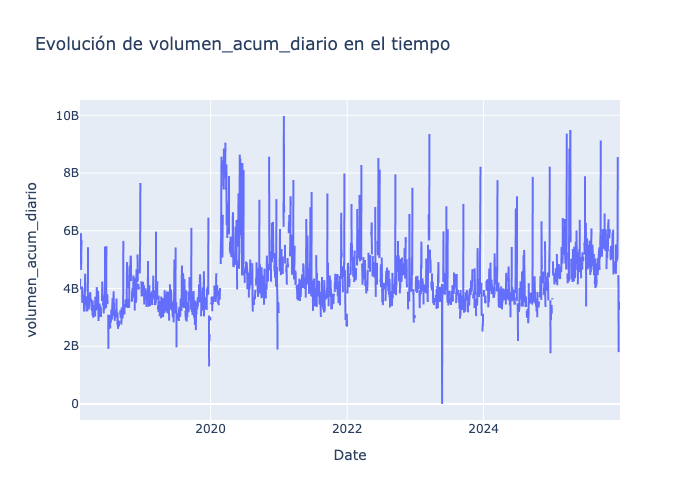

In [518]:
cuantitativa(df_sp500,"volumen_acum_diario")
grafico(df_sp500,"volumen_acum_diario")

In [520]:
# el unico problema de esta variable son los nulos 
df_sp500["volumen_acum_diario"] = df_sp500["volumen_acum_diario"].ffill()
print(f"La cantidad de nulos en la variables es {df_sp500['volumen_acum_diario'].isna().sum()}")

La cantidad de nulos en la variables es 0


#### volatilidad_med_diaria

-----Estamos analizando la columna volatilidad_med_diaria -----
Esta columna tiene 901 nulos
Sus estadísticos descriptivos son:
 count    1990.000000
mean        0.012072
std         0.009012
min         0.001647
25%         0.006426
50%         0.009663
75%         0.014522
max         0.097658
Name: volatilidad_med_diaria, dtype: float64


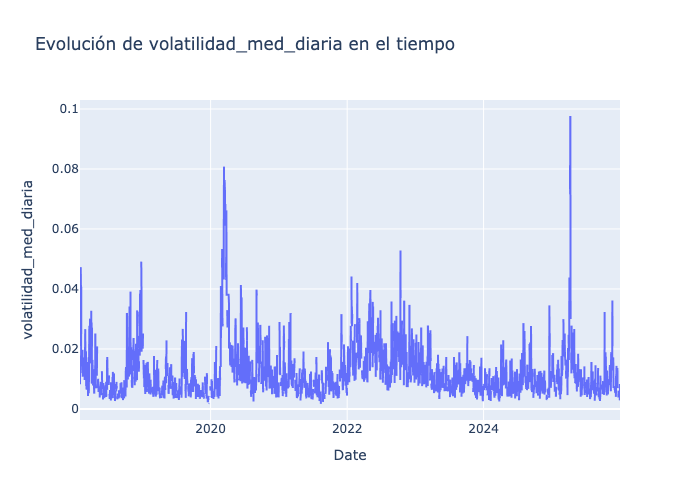

In [523]:
cuantitativa(df_sp500,"volatilidad_med_diaria")
grafico(df_sp500,"volatilidad_med_diaria")
# se pueden observar picos de volatilidad tanto en 2020 en lo que fue el comienzo del covid tanto en 2025 debido a las guerras comerciales
# entre EEUU y otros países

In [525]:
# mismo proble, habrá muchas variables que el hecho de que no cotizan ciertos dias tendremos que realizar un ffill()
df_sp500["volatilidad_med_diaria"] = df_sp500["volatilidad_med_diaria"].ffill()
print(f"La cantidad de nulos en la variables es {df_sp500['volatilidad_med_diaria'].isna().sum()}")

La cantidad de nulos en la variables es 0


#### sp500_busqueda

-----Estamos analizando la columna sp500_busqueda -----
Esta columna tiene 3 nulos
Sus estadísticos descriptivos son:
 count    2888.000000
mean       24.454537
std        11.841851
min        10.592593
25%        16.000000
50%        22.000000
75%        30.000000
max       100.000000
Name: sp500_busqueda, dtype: float64


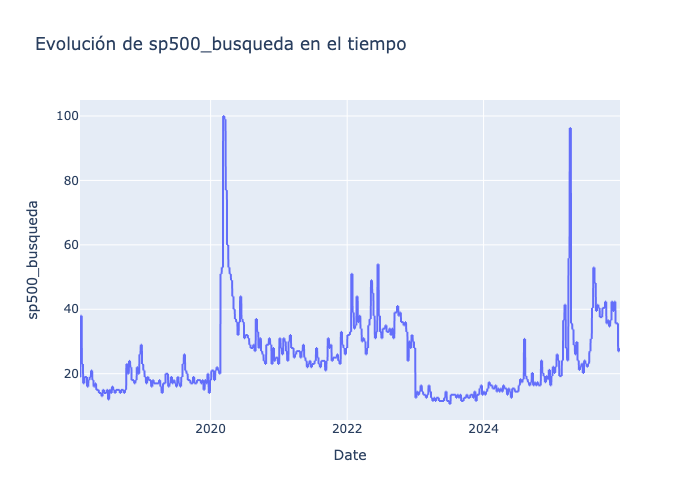

In [527]:
cuantitativa(df_sp500,"sp500_busqueda")
grafico(df_sp500,"sp500_busqueda")

In [530]:
# solo hay 3 nulos vamos a comprobar que pasa
df_sp500["sp500_busqueda"] = df_sp500["sp500_busqueda"].ffill()
# son los 3 ultimos datos de la serie, simplemente no parecen estar disponibles en la fuente con lo que se realiza un ffill()
print(f"La cantidad de nulos en la variables es {df_sp500['sp500_busqueda'].isna().sum()}")

La cantidad de nulos en la variables es 0


#### SP500_var

-----Estamos analizando la columna SP500_var -----
Esta columna tiene 1 nulos
Sus estadísticos descriptivos son:
 count    2890.000000
mean        0.000360
std         0.010288
min        -0.119841
25%        -0.001603
50%         0.000000
75%         0.003595
max         0.095154
Name: SP500_var, dtype: float64


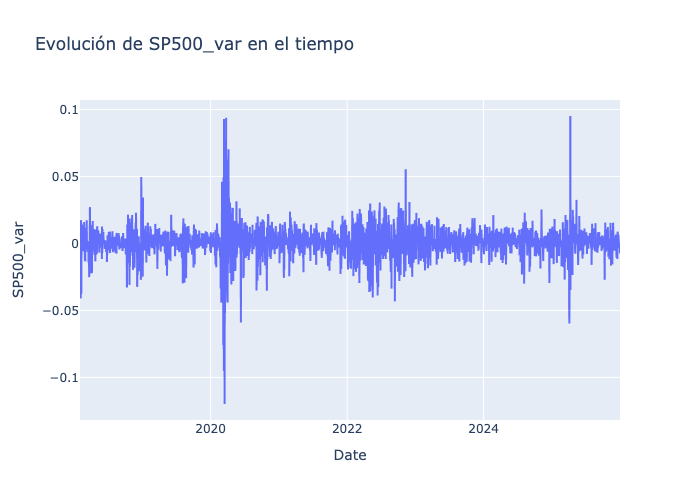

In [532]:
cuantitativa(df_sp500,"SP500_var")
grafico(df_sp500,"SP500_var")

In [535]:
# esta variable tiene un solo nulo por lo que se va a rellenar con un ffill ya que va a ser seguramente el primer dato de la serie
df_sp500[df_sp500["SP500_var"].isna()]


,BTC,ETH,SP500,GOLD,volumen_acum_diario,volatilidad_med_diaria,dominancia_bitcoin,sent_alcista,btc_busqueda,sp500_busqueda,...,RSI,dist_SMA_50,vix,var_vix,roc_15d,range_relative,SP500_vol_7,dist_bollinger_low,drawdown_60d,drawdown_30d
Date,,,,,,,,,,,,,,,,,,,,,
2018-02-01,9170.540039,1036.790039,2821.97998,1344.300049,3.977380e+09,0.008242,37.149679,0.447712,41.0,19.0,...,NaN,NaN,13.47,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [537]:
# efectivamente es el primer dato de la serie ya que esta variable ha sido construida utilizando el pct_change
df_sp500["SP500_var"] = df_sp500["SP500_var"].bfill() # se utiliza un bfill ya que es el primer dato
print(f"La cantidad de nulos en la variables es {df_sp500['SP500_var'].isna().sum()}")

La cantidad de nulos en la variables es 0


#### RSI


-----Estamos analizando la columna RSI -----
Esta columna tiene 13 nulos
Sus estadísticos descriptivos son:
 count    2878.000000
mean       56.925157
std        19.434033
min         3.465427
25%        43.460083
50%        58.118441
75%        70.866769
max        99.558554
Name: RSI, dtype: float64


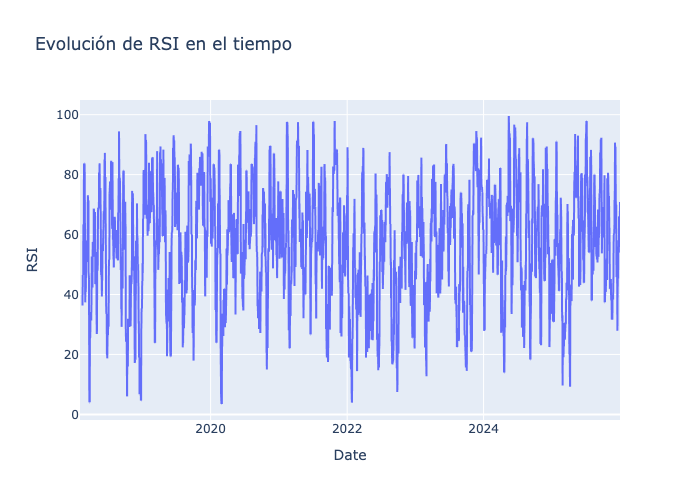

In [540]:
cuantitativa(df_sp500,"RSI")
grafico(df_sp500,"RSI")

In [542]:
# tiene 13 nulos, vamos a ver si tienen algo en común
df_sp500[df_sp500["RSI"].isna()]# son los primeros 13 datos de la serie


,BTC,ETH,SP500,GOLD,volumen_acum_diario,volatilidad_med_diaria,dominancia_bitcoin,sent_alcista,btc_busqueda,sp500_busqueda,...,RSI,dist_SMA_50,vix,var_vix,roc_15d,range_relative,SP500_vol_7,dist_bollinger_low,drawdown_60d,drawdown_30d
Date,,,,,,,,,,,,,,,,,,,,,
2018-02-01,9170.540039,1036.790039,2821.979980,1344.300049,3.977380e+09,0.008242,37.149679,0.447712,41.0,19.0,...,NaN,NaN,13.470000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-02,8830.750000,915.784973,2762.129883,1333.699951,4.340220e+09,0.017722,36.867967,0.447712,41.0,19.0,...,NaN,NaN,17.309999,0.285078,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-03,9174.910156,964.018982,2762.129883,1333.699951,4.340220e+09,0.017722,36.090989,0.447712,41.0,19.0,...,NaN,NaN,17.309999,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-04,8277.009766,834.682007,2762.129883,1333.699951,4.340220e+09,0.017722,36.831309,0.447712,40.0,38.0,...,NaN,NaN,17.309999,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-05,6955.270020,697.950989,2648.939941,1333.000000,5.310840e+09,0.047272,38.316608,0.447712,40.0,38.0,...,NaN,NaN,37.320000,1.155979,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-06,7754.000000,793.122009,2695.139893,1326.099976,5.917350e+09,0.040061,36.901627,0.447712,40.0,38.0,...,NaN,NaN,29.980000,-0.196677,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-07,7621.299805,757.067993,2681.659912,1311.599976,4.646300e+09,0.017280,37.288085,0.447712,40.0,38.0,...,NaN,NaN,27.730000,-0.075050,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-08,8265.589844,817.807007,2581.000000,1316.900024,5.333840e+09,0.040570,36.483433,0.370277,40.0,38.0,...,NaN,NaN,33.459999,0.206635,NaN,NaN,2.152094,NaN,NaN,NaN
2018-02-09,8736.980469,883.864990,2619.550049,1313.099976,5.690110e+09,0.040457,34.829151,0.370277,40.0,38.0,...,NaN,NaN,29.059999,-0.131500,NaN,NaN,2.333435,NaN,NaN,NaN


In [544]:
# al construir la variable y utilizar rolling(window=14) se generan 13 nulos 
df_sp500["RSI"] = df_sp500["RSI"].bfill()
print(f"La cantidad de nulos en la variables es {df_sp500['RSI'].isna().sum()}")

La cantidad de nulos en la variables es 0


#### dist_SMA_50

-----Estamos analizando la columna dist_SMA_50 -----
Esta columna tiene 49 nulos
Sus estadísticos descriptivos son:
 count    2842.000000
mean        0.008248
std         0.035508
min        -0.257528
25%        -0.007045
50%         0.016486
75%         0.028997
max         0.109441
Name: dist_SMA_50, dtype: float64


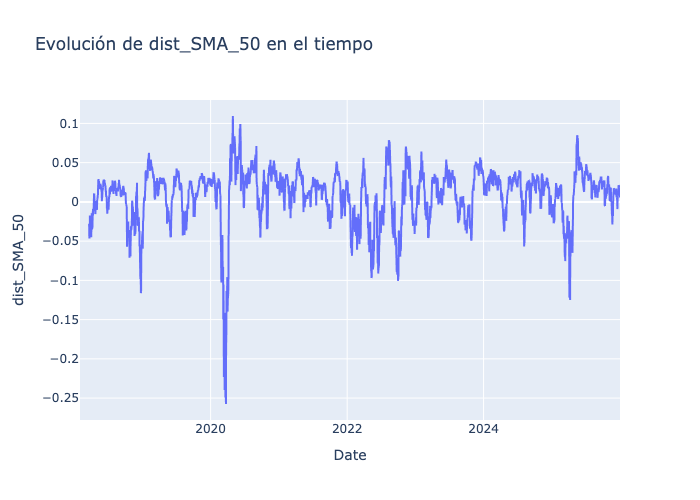

In [547]:
cuantitativa(df_sp500,"dist_SMA_50")
grafico(df_sp500,"dist_SMA_50")

In [549]:
# al ser la media movil de 50 periodos los 50 prieros periodos no se va a tener media por que no se tienen los datos antes
# del 2 de Febrero por lo que serán nulos
df_sp500[df_sp500["dist_SMA_50"].isna()].head()


,BTC,ETH,SP500,GOLD,volumen_acum_diario,volatilidad_med_diaria,dominancia_bitcoin,sent_alcista,btc_busqueda,sp500_busqueda,...,RSI,dist_SMA_50,vix,var_vix,roc_15d,range_relative,SP500_vol_7,dist_bollinger_low,drawdown_60d,drawdown_30d
Date,,,,,,,,,,,,,,,,,,,,,
2018-02-01,9170.540039,1036.790039,2821.979980,1344.300049,3.977380e+09,0.008242,37.149679,0.447712,41.0,19.0,...,36.325119,NaN,13.470000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-02,8830.750000,915.784973,2762.129883,1333.699951,4.340220e+09,0.017722,36.867967,0.447712,41.0,19.0,...,36.325119,NaN,17.309999,0.285078,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-03,9174.910156,964.018982,2762.129883,1333.699951,4.340220e+09,0.017722,36.090989,0.447712,41.0,19.0,...,36.325119,NaN,17.309999,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-04,8277.009766,834.682007,2762.129883,1333.699951,4.340220e+09,0.017722,36.831309,0.447712,40.0,38.0,...,36.325119,NaN,17.309999,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
2018-02-05,6955.270020,697.950989,2648.939941,1333.000000,5.310840e+09,0.047272,38.316608,0.447712,40.0,38.0,...,36.325119,NaN,37.320000,1.155979,NaN,NaN,NaN,NaN,NaN,NaN


In [550]:
df_sp500["dist_SMA_50"] = df_sp500["dist_SMA_50"].bfill()
print(f"La cantidad de nulos en la variables es {df_sp500['dist_SMA_50'].isna().sum()}")

La cantidad de nulos en la variables es 0


#### vix

-----Estamos analizando la columna vix -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean       19.734652
std         7.351608
min        10.850000
25%        14.850000
50%        17.879999
75%        22.520000
max        82.690002
Name: vix, dtype: float64


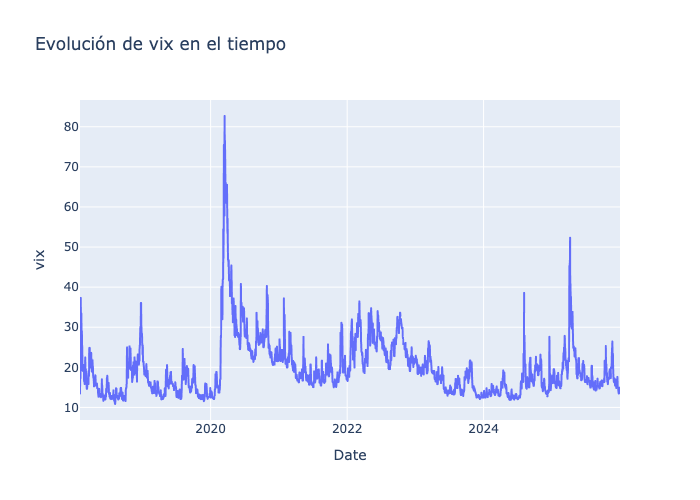

In [554]:
cuantitativa(df_sp500,"vix")
grafico(df_sp500,"vix")

In [556]:
# se ha tenido que procesar al construir el dataframe ya que interferia de manera directa en el var_vix
print(f"La cantidad de nulos en la variables es {df_sp500['vix'].isna().sum()}")

La cantidad de nulos en la variables es 0


#### var_vix

-----Estamos analizando la columna var_vix -----
Esta columna tiene 1 nulos
Sus estadísticos descriptivos son:
 count    2890.000000
mean        0.002444
std         0.073419
min        -0.357539
25%        -0.025630
50%         0.000000
75%         0.012972
max         1.155979
Name: var_vix, dtype: float64


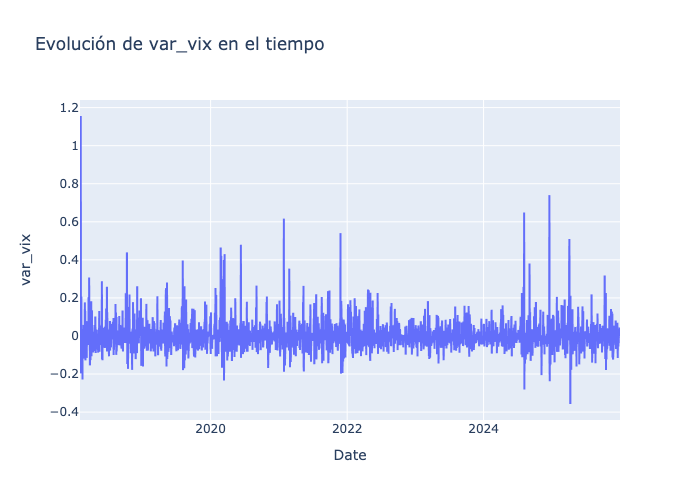

In [558]:
cuantitativa(df_sp500,"var_vix")
grafico(df_sp500,"var_vix")

In [ ]:
# solo un nulo, es el primer dato de la serie ya que se hizo un pct_change
# se procede a hacer un bfill()
df_sp500["var_vix"] = df_sp500["var_vix"].bfill()
print(f"La cantidad de nulos en la variables es {df_sp500['var_vix'].isna().sum()}")

#### roc_15d

-----Estamos analizando la columna roc_15d -----
Esta columna tiene 15 nulos
Sus estadísticos descriptivos son:
 count    2876.000000
mean        0.005541
std         0.035058
min        -0.247267
25%        -0.010829
50%         0.009667
75%         0.025223
max         0.188616
Name: roc_15d, dtype: float64


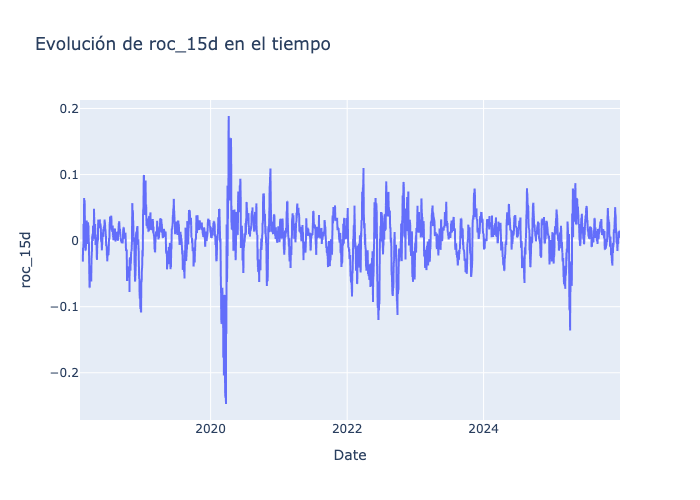

In [381]:
cuantitativa(df_sp500,"roc_15d")
grafico(df_sp500,"roc_15d")

In [383]:
# lo mismo que en las anteriores al ser roc_15 tenemos 15 nulos
df_sp500["roc_15d"] = df_sp500["roc_15d"].bfill()
print(f"La cantidad de nulos en la variables es {df_sp500['roc_15d'].isna().sum()}")

La cantidad de nulos en la variables es 0


#### range_relative

-----Estamos analizando la columna range_relative -----
Esta columna tiene 920 nulos
Sus estadísticos descriptivos son:
 count    1971.000000
mean        1.012740
std         0.520641
min         0.198984
25%         0.654081
50%         0.893941
75%         1.231032
max         4.762742
Name: range_relative, dtype: float64


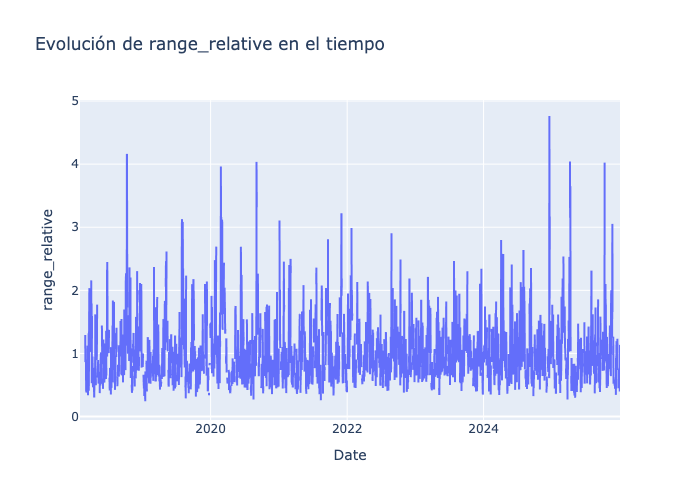

In [386]:
cuantitativa(df_sp500,"range_relative")
grafico(df_sp500,"range_relative")

In [388]:
# aquí vamos a tener 901 + 19 de los primeros por lo que hay que hacer un .ffill() y un .bfill()
df_sp500['range_relative'] = df_sp500['range_relative'].ffill().bfill()

#### SP500_vol_7

-----Estamos analizando la columna SP500_vol_7 -----
Esta columna tiene 7 nulos
Sus estadísticos descriptivos son:
 count    2884.000000
mean        0.805035
std         0.659920
min         0.071798
25%         0.433345
50%         0.662028
75%         0.955853
max         7.795197
Name: SP500_vol_7, dtype: float64


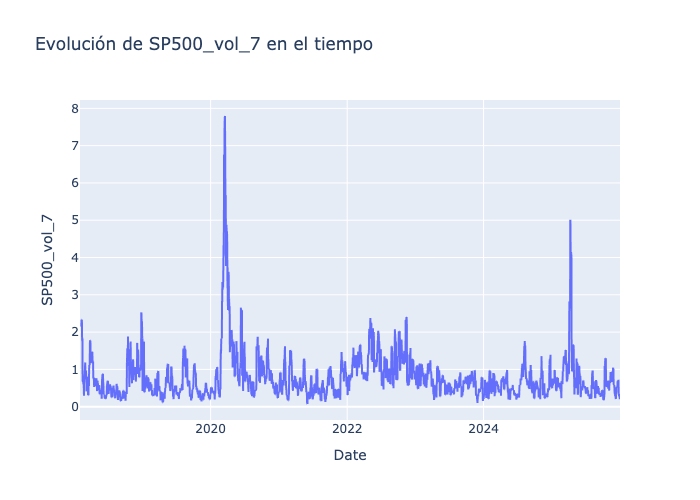

In [391]:
cuantitativa(df_sp500,"SP500_vol_7")
grafico(df_sp500,"SP500_vol_7")

In [393]:
#exactamente lo mismo al ser volatilidad de los ultimos 7 días, en los primeros 7 días no se tendran datos para el rolling(window=7)
# con lo que se generarán 7 nulos
df_sp500[df_sp500["SP500_vol_7"].isna()].head()


,BTC,ETH,SP500,GOLD,volumen_acum_diario,volatilidad_med_diaria,dominancia_bitcoin,sent_alcista,btc_busqueda,sp500_busqueda,...,RSI,dist_SMA_50,vix,var_vix,roc_15d,range_relative,SP500_vol_7,dist_bollinger_low,drawdown_60d,drawdown_30d
Date,,,,,,,,,,,,,,,,,,,,,
2018-02-01,9170.540039,1036.790039,2821.979980,1344.300049,3.977380e+09,0.008242,37.149679,0.447712,41.0,19.0,...,36.325119,-0.027806,13.470000,0.285078,-0.031807,1.292222,NaN,NaN,NaN,NaN
2018-02-02,8830.750000,915.784973,2762.129883,1333.699951,4.340220e+09,0.017722,36.867967,0.447712,41.0,19.0,...,36.325119,-0.027806,17.309999,0.285078,-0.031807,1.292222,NaN,NaN,NaN,NaN
2018-02-03,9174.910156,964.018982,2762.129883,1333.699951,4.340220e+09,0.017722,36.090989,0.447712,41.0,19.0,...,36.325119,-0.027806,17.309999,0.000000,-0.031807,1.292222,NaN,NaN,NaN,NaN
2018-02-04,8277.009766,834.682007,2762.129883,1333.699951,4.340220e+09,0.017722,36.831309,0.447712,40.0,38.0,...,36.325119,-0.027806,17.309999,0.000000,-0.031807,1.292222,NaN,NaN,NaN,NaN
2018-02-05,6955.270020,697.950989,2648.939941,1333.000000,5.310840e+09,0.047272,38.316608,0.447712,40.0,38.0,...,36.325119,-0.027806,37.320000,1.155979,-0.031807,1.292222,NaN,NaN,NaN,NaN


In [395]:
df_sp500["SP500_vol_7"] = df_sp500["SP500_vol_7"].bfill()
print(f"La cantidad de nulos en la variables es {df_sp500['SP500_vol_7'].isna().sum()}")

La cantidad de nulos en la variables es 0


#### dist_bollinger_low

-----Estamos analizando la columna dist_bollinger_low -----
Esta columna tiene 19 nulos
Sus estadísticos descriptivos son:
 count    2872.000000
mean        0.033426
std         0.028325
min        -0.046101
25%         0.015304
50%         0.028450
75%         0.044852
max         0.245606
Name: dist_bollinger_low, dtype: float64


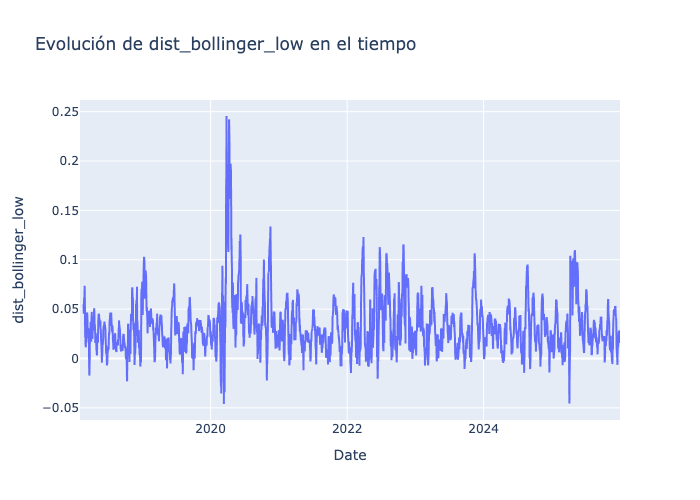

In [398]:
cuantitativa(df_sp500,"dist_bollinger_low")
grafico(df_sp500,"dist_bollinger_low")

In [400]:
df_sp500[df_sp500["dist_bollinger_low"].isna()].head()

,BTC,ETH,SP500,GOLD,volumen_acum_diario,volatilidad_med_diaria,dominancia_bitcoin,sent_alcista,btc_busqueda,sp500_busqueda,...,RSI,dist_SMA_50,vix,var_vix,roc_15d,range_relative,SP500_vol_7,dist_bollinger_low,drawdown_60d,drawdown_30d
Date,,,,,,,,,,,,,,,,,,,,,
2018-02-01,9170.540039,1036.790039,2821.979980,1344.300049,3.977380e+09,0.008242,37.149679,0.447712,41.0,19.0,...,36.325119,-0.027806,13.470000,0.285078,-0.031807,1.292222,2.152094,NaN,NaN,NaN
2018-02-02,8830.750000,915.784973,2762.129883,1333.699951,4.340220e+09,0.017722,36.867967,0.447712,41.0,19.0,...,36.325119,-0.027806,17.309999,0.285078,-0.031807,1.292222,2.152094,NaN,NaN,NaN
2018-02-03,9174.910156,964.018982,2762.129883,1333.699951,4.340220e+09,0.017722,36.090989,0.447712,41.0,19.0,...,36.325119,-0.027806,17.309999,0.000000,-0.031807,1.292222,2.152094,NaN,NaN,NaN
2018-02-04,8277.009766,834.682007,2762.129883,1333.699951,4.340220e+09,0.017722,36.831309,0.447712,40.0,38.0,...,36.325119,-0.027806,17.309999,0.000000,-0.031807,1.292222,2.152094,NaN,NaN,NaN
2018-02-05,6955.270020,697.950989,2648.939941,1333.000000,5.310840e+09,0.047272,38.316608,0.447712,40.0,38.0,...,36.325119,-0.027806,37.320000,1.155979,-0.031807,1.292222,2.152094,NaN,NaN,NaN


In [402]:
# 19 por el .rolling(window=20) utilizado en la construcción de la variable
df_sp500["dist_bollinger_low"] = df_sp500["dist_bollinger_low"].bfill() 
print(f"La cantidad de nulos en la variables es {df_sp500['dist_bollinger_low'].isna().sum()}")

La cantidad de nulos en la variables es 0


#### drawdown_60d

-----Estamos analizando la columna drawdown_60d -----
Esta columna tiene 59 nulos
Sus estadísticos descriptivos son:
 count    2832.000000
mean       -0.029896
std         0.043388
min        -0.339250
25%        -0.042292
50%        -0.011296
75%        -0.001260
max         0.000000
Name: drawdown_60d, dtype: float64


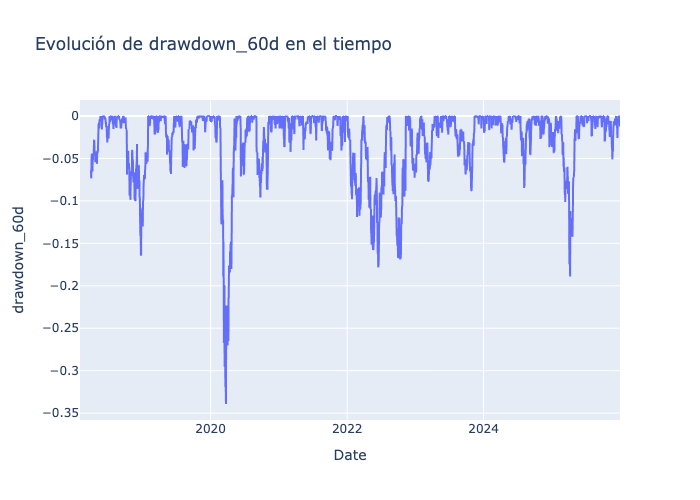

In [405]:
cuantitativa(df_sp500,"drawdown_60d")
grafico(df_sp500,"drawdown_60d")

In [407]:
# tiene 59 nulos del rolling(window=60) y lo mismo 
# pasará en la siguiente variable
df_sp500["drawdown_60d"] = df_sp500["drawdown_60d"].bfill() 
print(f"La cantidad de nulos en la variables es {df_sp500['drawdown_60d'].isna().sum()}")

La cantidad de nulos en la variables es 0


#### drawdown_30d

-----Estamos analizando la columna drawdown_30d -----
Esta columna tiene 29 nulos
Sus estadísticos descriptivos son:
 count    2862.000000
mean       -0.022064
std         0.034112
min        -0.329668
25%        -0.030600
50%        -0.008120
75%        -0.000159
max         0.000000
Name: drawdown_30d, dtype: float64


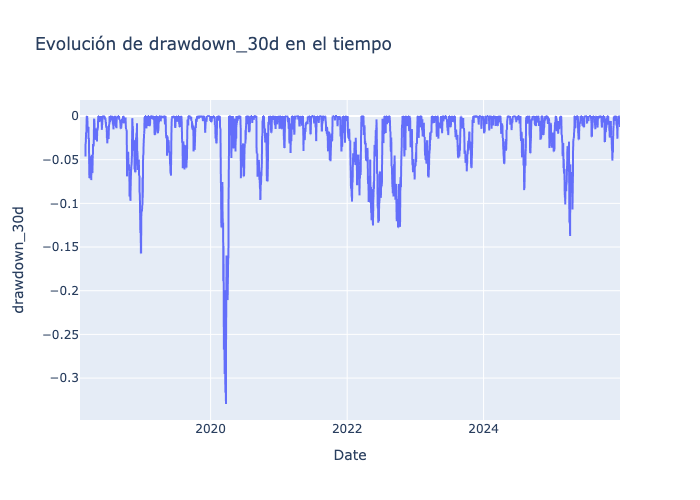

In [410]:
cuantitativa(df_sp500,"drawdown_30d")
grafico(df_sp500,"drawdown_30d")

In [412]:
# 29 nulos de exactamente lo mismo que la variable anterior
df_sp500["drawdown_30d"] = df_sp500["drawdown_30d"].bfill() # utilizamos tanto ffill como bfill
print(f"La cantidad de nulos en la variables es {df_sp500['drawdown_30d'].isna().sum()}")

La cantidad de nulos en la variables es 0


In [414]:
df_sp500.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2891 entries, 2018-02-01 to 2025-12-31
Freq: D
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   BTC                     2891 non-null   float64
 1   ETH                     2891 non-null   float64
 2   SP500                   2891 non-null   float64
 3   GOLD                    2891 non-null   float64
 4   volumen_acum_diario     2891 non-null   float64
 5   volatilidad_med_diaria  2891 non-null   float64
 6   dominancia_bitcoin      2891 non-null   float64
 7   sent_alcista            2891 non-null   float64
 8   btc_busqueda            2891 non-null   float64
 9   sp500_busqueda          2891 non-null   float64
 10  f&g_crypto              2891 non-null   float64
 11  SP500_var               2891 non-null   float64
 12  RSI                     2891 non-null   float64
 13  dist_SMA_50             2891 non-null   float64
 14  vix           

### ANÁLISIS BIVARIANTE

En este apartado se suele representar la variable target vs las predictoras pero no tenemos la variable "target" construida en este punto. Lo más parecido sería el Fear & Greed crypto y ese análisis 
bivariante ya se hizo en el apartado cripto por lo que aquí se van a 
representar pares de variables interesantes para ver su relación

##### vix vs sp500_busqueda

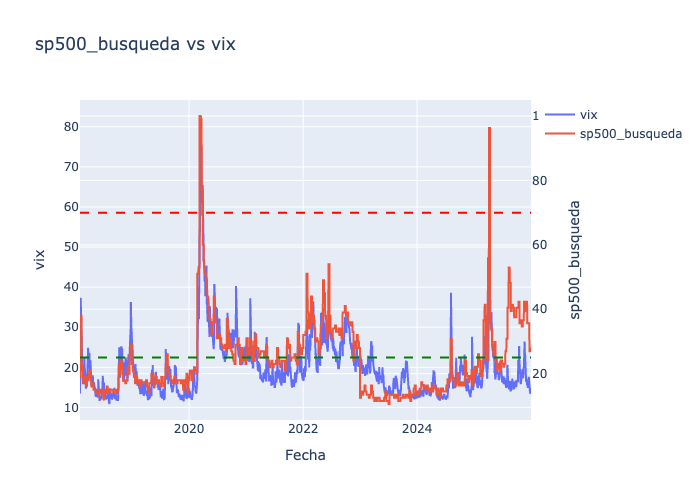

In [419]:
# son gráficos muy parecidos que presentan picos en los mismos puntos
# coincidiendo en marzo de 2020 y abril de 2025
grafico_doble_eje(df_sp500,"vix","sp500_busqueda")
# tienen que tener una correlación muy alta

##### btc_busqueda vs sp500_busqueda

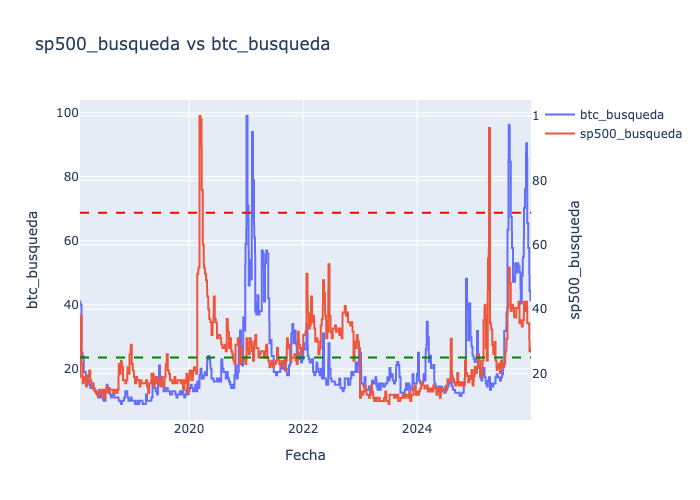

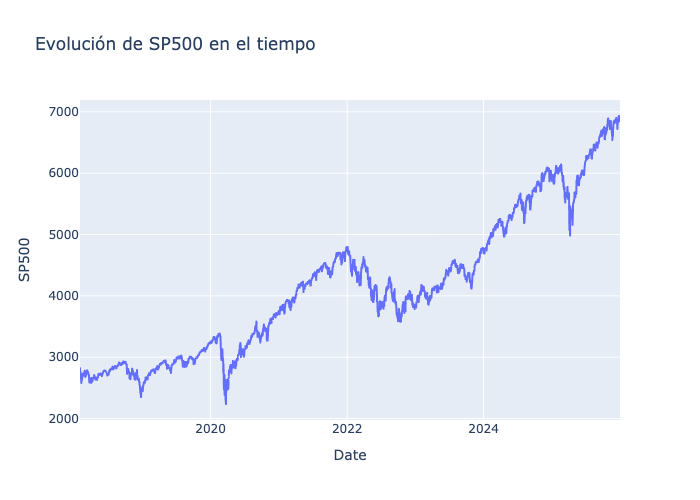

In [422]:
# en este grafico parece como que la gente primero se interese
# por el S&P 500 y luego se pasen a las criptomonedas en busqueda
# de mayor rentabilidad
grafico_doble_eje(df_sp500,"btc_busqueda","sp500_busqueda")
grafico(df,"SP500")

##### SP500_vol_7 vs vix

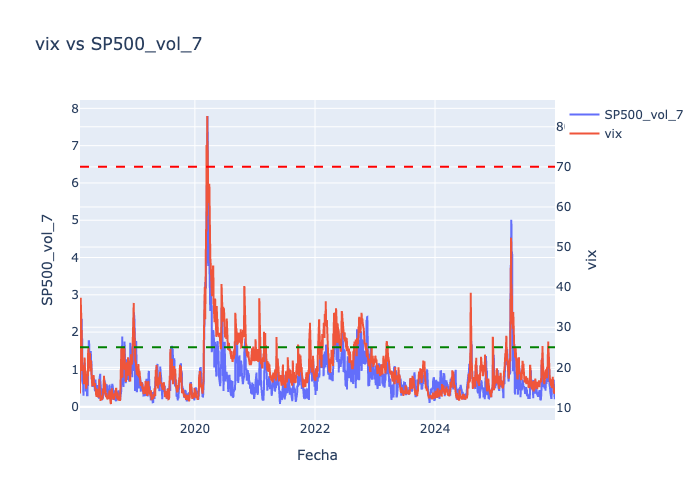

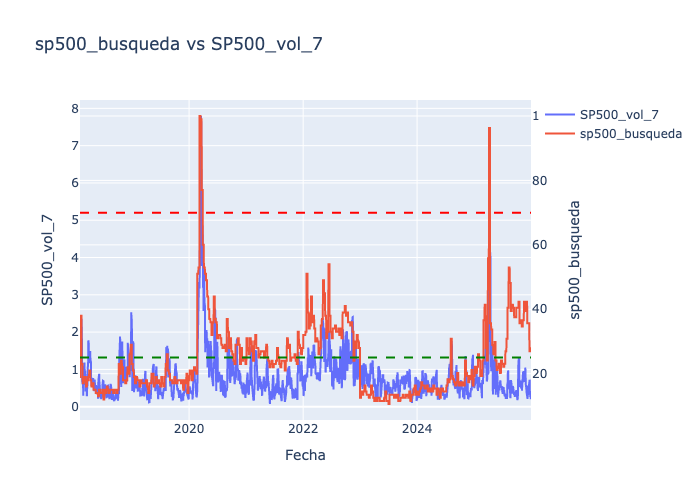

In [425]:
##### SP500_vol_7 vs vix
grafico_doble_eje(df_sp500,"SP500_vol_7","vix")
# son graficos muy parecidos al igual que vix y sp500_busqueda
# por lo que estas variables tendrán mucha correlación positiva
# entre ellas
grafico_doble_eje(df_sp500,"SP500_vol_7","sp500_busqueda")

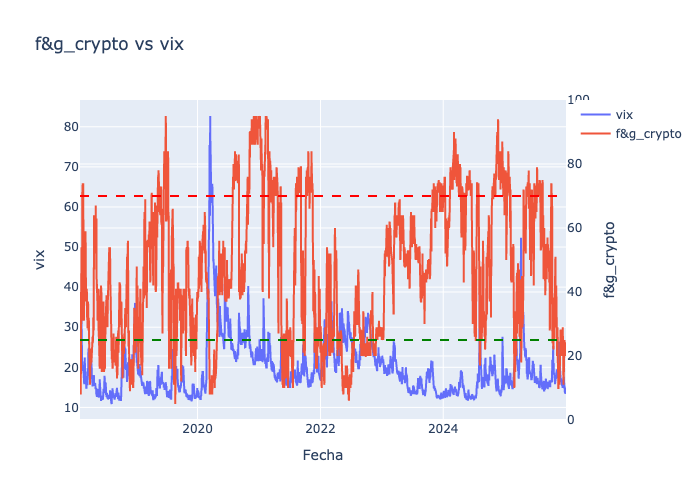

In [427]:
# se puede observar como en periodos de mayor VIX el fear & greed
# suele estar con valores bajos como en los sucesos de 2020 y 2025
# pero también en todo el año 2022, donde el VIX es más alto que en el 2021
# o en el 2024 y el fear & greed se mantiene en niveles bajos
grafico_doble_eje(df_sp500,"vix","f&g_crypto")

##### RSI vs Fear & greed Crypto

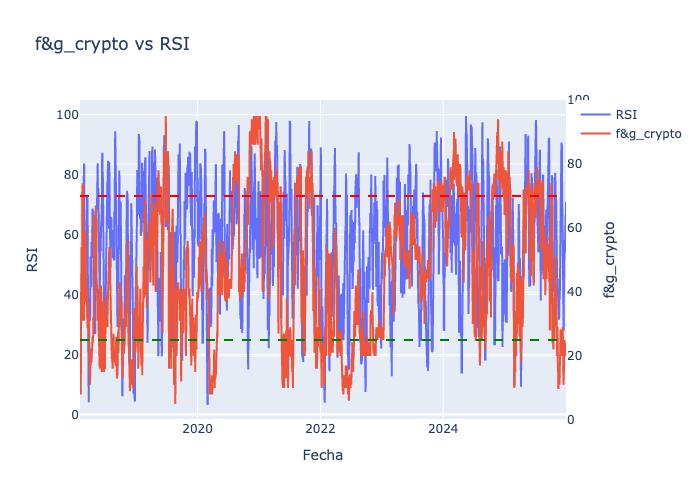

In [430]:
grafico_doble_eje(df_sp500,"RSI","f&g_crypto")

### ANÁLISIS MULTIVARIANTE

In [433]:
df_sp500.corr()["SP500"].sort_values(ascending = False)

SP500                     1.000000
BTC                       0.944028
GOLD                      0.912947
ETH                       0.857326
btc_busqueda              0.431052
drawdown_60d              0.256900
f&g_crypto                0.240114
sent_alcista              0.226465
drawdown_30d              0.208304
volumen_acum_diario       0.168149
dist_SMA_50               0.163708
roc_15d                   0.090997
RSI                       0.088402
sp500_busqueda            0.074969
dominancia_bitcoin        0.047166
SP500_var                 0.024155
var_vix                  -0.014114
range_relative           -0.016280
dist_bollinger_low       -0.086384
volatilidad_med_diaria   -0.169304
SP500_vol_7              -0.196192
vix                      -0.208521
Name: SP500, dtype: float64

<Axes: >

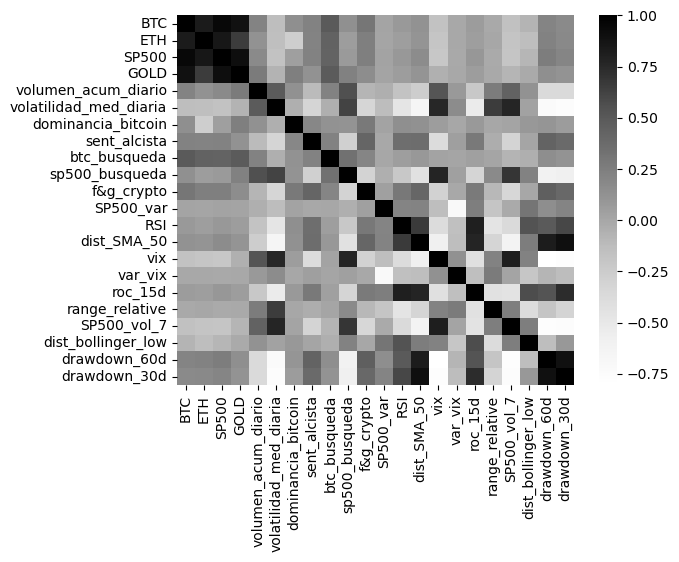

In [435]:
sns.heatmap(df_sp500.corr(), cmap = "Greys")

### BUSQUEDA HEURÍSTICA DE PARÁMETROS

In [437]:
df_sp500.corr()["f&g_crypto"].sort_values(ascending = False)

f&g_crypto                1.000000
drawdown_60d              0.458252
sent_alcista              0.421368
dist_SMA_50               0.408008
drawdown_30d              0.397076
BTC                       0.304286
RSI                       0.294149
dominancia_bitcoin        0.281035
roc_15d                   0.274975
SP500                     0.240114
ETH                       0.238566
btc_busqueda              0.206656
GOLD                      0.159259
SP500_var                 0.034337
dist_bollinger_low        0.000641
var_vix                  -0.005794
volumen_acum_diario      -0.079065
range_relative           -0.095828
vix                      -0.291134
sp500_busqueda           -0.303781
volatilidad_med_diaria   -0.330883
SP500_vol_7              -0.336382
Name: f&g_crypto, dtype: float64

In [439]:
# Escalamos las variables para que esten entre 0 y 100 y poder realizar el índice
df_sp500_norm = df_sp500.copy()
scaler_sp500 = MinMaxScaler(feature_range=(0,100))
columnas_sp500 = ['BTC', 'SP500', 'GOLD', 'f&g_crypto', 'sent_alcista', 'dist_SMA_50',
       'drawdown_60d', 'drawdown_30d', 'roc_15d', 'dist_bollinger_low']
for col in columnas_sp500:
    df_sp500_norm[col] = scaler_sp500.fit_transform(df_sp500[[col]])

qt = QuantileTransformer(output_distribution='uniform', n_quantiles=100)
vix_transformed = qt.fit_transform(df_sp500[['vix']]) * 100
df_sp500_norm['vix_inv'] = 100 - vix_transformed


In [441]:
# VAMOS A HACER LA VARIABLE SINTETICA PARA ELLO VAMOS A DIVIDIR LAS VARIABLES EN 3 BLOQUES
# VARIABLES DE MERCADO (SP500, BTC Y GOLD)
# VARIABLES TÉCNICAS (DIST_SMA_50, DRAWDOWN DE 30 Y 60, DISTANCIA DE BOLLINGER)
# VARIABLES DE SENTIMIENTO (F&G CRYPTO, SENTIMIENTO BAJISTA Y VIX)
# Los pesos de las variables se han asignado a mano teniendo en cuenta la correlación con el f&g crypto



var_mercado = (df_sp500_norm["BTC"] * 0.33 + 
                 df_sp500_norm["SP500"] * 0.33 + 
                 df_sp500_norm["GOLD"] * 0.33)

var_tecnico = (df_sp500_norm['drawdown_60d'] * 0.2 + 
                 df_sp500_norm['drawdown_30d'] * 0.2 + 
                 df_sp500_norm['dist_SMA_50'] * 0.30 + 
                 df_sp500_norm['dist_bollinger_low'] * 0.30)

var_sentimiento = (df_sp500_norm['sent_alcista'] * 0.3 + 
                     df_sp500_norm['f&g_crypto'] * 0.5 +
                     df_sp500_norm["vix_inv"] * 0.3)

df_sp500_norm["f&g_index"] = (var_mercado * 0.1 + 
                              var_tecnico * 0.3 +
                              var_sentimiento * 0.6)



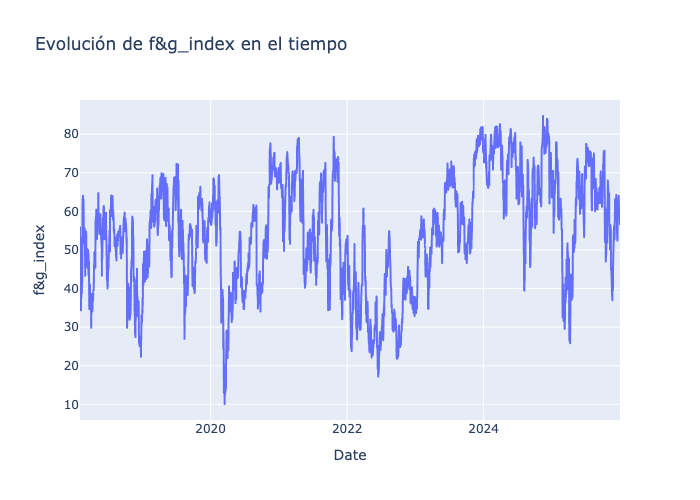

In [444]:
grafico(df_sp500_norm,"f&g_index")

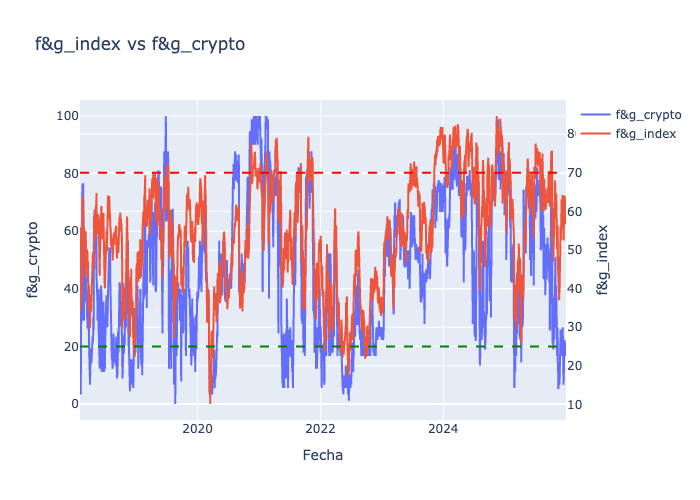

In [445]:
# comparamos el índice original con el índice sintético
grafico_doble_eje(df_sp500_norm,"f&g_crypto","f&g_index")
# se observa como nuestro índice sintético es algo más conservador. También puede ser debido a que el S&P500 sufre menos volatilidad
# que el mercado crypto.

### PCA

In [449]:
df_sp500.columns

Index(['BTC', 'ETH', 'SP500', 'GOLD', 'volumen_acum_diario',
       'volatilidad_med_diaria', 'dominancia_bitcoin', 'sent_alcista',
       'btc_busqueda', 'sp500_busqueda', 'f&g_crypto', 'SP500_var', 'RSI',
       'dist_SMA_50', 'vix', 'var_vix', 'roc_15d', 'range_relative',
       'SP500_vol_7', 'dist_bollinger_low', 'drawdown_60d', 'drawdown_30d'],
      dtype='object')

In [450]:
df_sp500.corr()["f&g_crypto"].sort_values(ascending = False)

f&g_crypto                1.000000
drawdown_60d              0.458252
sent_alcista              0.421368
dist_SMA_50               0.408008
drawdown_30d              0.397076
BTC                       0.304286
RSI                       0.294149
dominancia_bitcoin        0.281035
roc_15d                   0.274975
SP500                     0.240114
ETH                       0.238566
btc_busqueda              0.206656
GOLD                      0.159259
SP500_var                 0.034337
dist_bollinger_low        0.000641
var_vix                  -0.005794
volumen_acum_diario      -0.079065
range_relative           -0.095828
vix                      -0.291134
sp500_busqueda           -0.303781
volatilidad_med_diaria   -0.330883
SP500_vol_7              -0.336382
Name: f&g_crypto, dtype: float64

In [453]:
df_sp500_pca = df_sp500.copy()

------------------------- SIN ESCALAR -------------------------


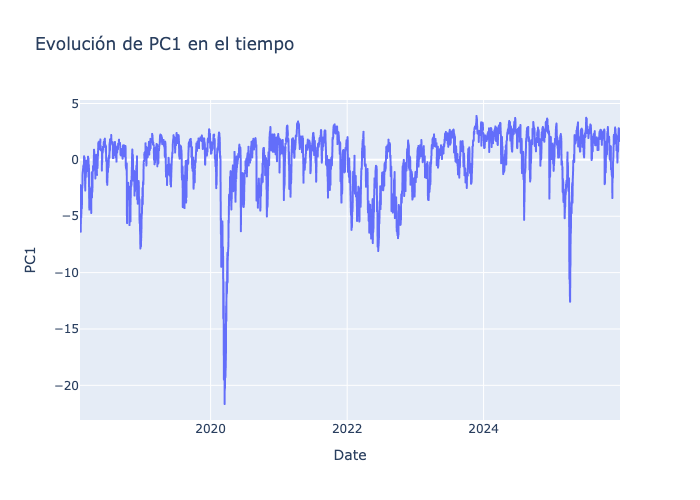

------------------------- ESCALADA -------------------------


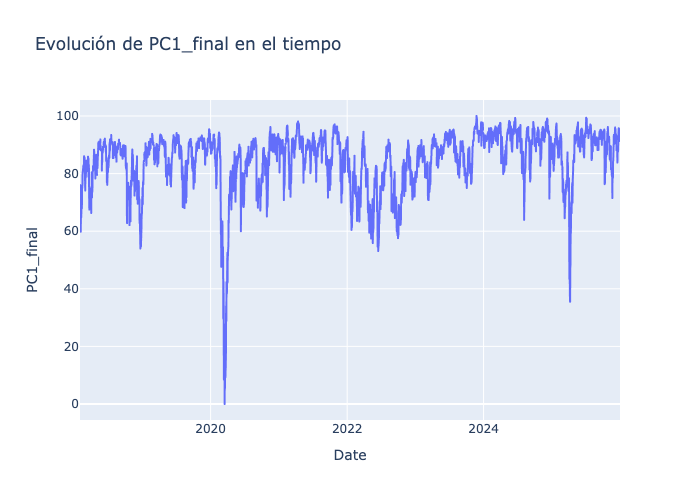

In [455]:
scaler_pca = StandardScaler()
df_sp500_pca_scaled = scaler_pca.fit_transform(df_sp500_pca)


pca = PCA(n_components=1)
pc1 = pca.fit_transform(df_sp500_pca_scaled)


# Usamos el mismo índice del dataframe original para no perder las fechas
df_sp500_pc1 = pd.DataFrame(data=pc1, columns=['PC1'], index=df_sp500_pca.index)
print("-"*25,"SIN ESCALAR","-"*25)
grafico(df_sp500_pc1,"PC1")

# debido a que tiene un pico muy grande se procede a hacer un RobustScaler
#
print("-" * 25, "ESCALADA", "-" * 25)

# 1. Configuración del minmaxscaler
final_scaler = MinMaxScaler(feature_range=(0, 100))

# escalamos para ver si se parece más al fear & greed 
df_sp500_pc1["PC1_final"] = final_scaler.fit_transform(df_sp500_pc1[["PC1"]])
grafico(df_sp500_pc1,"PC1_final")

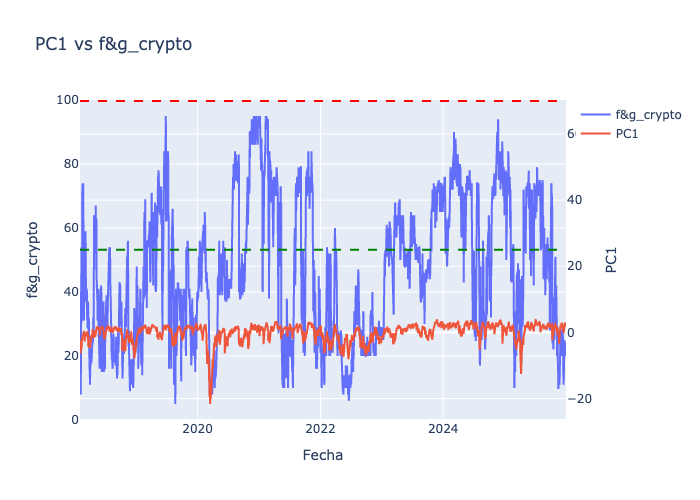

In [457]:
df_sp500_pc1["f&g_crypto"] = df_sp500_pca["f&g_crypto"]
grafico_doble_eje(df_sp500_pc1,"f&g_crypto","PC1")

In [459]:
df_sp500.columns

Index(['BTC', 'ETH', 'SP500', 'GOLD', 'volumen_acum_diario',
       'volatilidad_med_diaria', 'dominancia_bitcoin', 'sent_alcista',
       'btc_busqueda', 'sp500_busqueda', 'f&g_crypto', 'SP500_var', 'RSI',
       'dist_SMA_50', 'vix', 'var_vix', 'roc_15d', 'range_relative',
       'SP500_vol_7', 'dist_bollinger_low', 'drawdown_60d', 'drawdown_30d'],
      dtype='object')

In [461]:
# obtenemos los 'loadings' (las cargas del PC1)
loadings = pca.components_[0]

# # elevamos al cuadrado para obtener la varianza (importancia relativa)
# El cuadrado de los loadings representa la contribución de cada variable
importancia_varianza = loadings**2

# convertimos a porcentaje (normalizamos para que sumen 100%)
porcentajes = (importancia_varianza / importancia_varianza.sum()) * 100

# convertimos a dataframe
df_pesos = pd.DataFrame({
    'Variable': df_sp500_pca.columns,
    'Peso (%)': porcentajes
}).sort_values(by='Peso (%)', ascending=False)

print("Composición porcentual de tu Índice Sintético:")
print(df_pesos.round(2))

Composición porcentual de tu Índice Sintético:
                  Variable  Peso (%)
21            drawdown_30d     11.92
20            drawdown_60d     11.14
5   volatilidad_med_diaria     10.17
13             dist_SMA_50     10.15
14                     vix      9.66
18             SP500_vol_7      9.21
16                 roc_15d      7.34
12                     RSI      6.13
9           sp500_busqueda      5.71
10              f&g_crypto      3.55
7             sent_alcista      3.39
17          range_relative      2.69
4      volumen_acum_diario      2.63
2                    SP500      1.56
0                      BTC      1.26
1                      ETH      1.21
11               SP500_var      0.72
3                     GOLD      0.62
15                 var_vix      0.44
8             btc_busqueda      0.29
6       dominancia_bitcoin      0.11
19      dist_bollinger_low      0.09


#### TRANSFER LEARNING

In [464]:
df_sp500_transfer = df_sp500.copy()
df_sp500_transfer.columns

# tenemos que cambiar los nombres de las variables ya que vamos a hacer .fit con
# el mismo escalador con el que se hizo el modelo de las criptos
df_sp500_transfer = df_sp500_transfer.rename(columns={
    "SP500_var" : "BTC_var",
    "SP500_vol_7" : "BTC_vol_7",
    "sp500_busqueda" : "crypto_busqueda"})


In [466]:
df_sp500_transfer.columns

Index(['BTC', 'ETH', 'SP500', 'GOLD', 'volumen_acum_diario',
       'volatilidad_med_diaria', 'dominancia_bitcoin', 'sent_alcista',
       'btc_busqueda', 'crypto_busqueda', 'f&g_crypto', 'BTC_var', 'RSI',
       'dist_SMA_50', 'vix', 'var_vix', 'roc_15d', 'range_relative',
       'BTC_vol_7', 'dist_bollinger_low', 'drawdown_60d', 'drawdown_30d'],
      dtype='object')

In [467]:
df.columns

Index(['BTC', 'ETH', 'SP500', 'GOLD', 'volumen_acum_diario',
       'volatilidad_med_diaria', 'dominancia_bitcoin', 'sent_alcista',
       'btc_busqueda', 'crypto_busqueda', 'f&g_index', 'BTC_var', 'RSI',
       'dist_SMA_50', 'vix', 'var_vix', 'roc_15d', 'range_relative',
       'BTC_vol_7', 'dist_bollinger_low', 'drawdown_60d', 'drawdown_30d'],
      dtype='object')

In [470]:
# vamos a utilizar el modelo XGboost que utilizamos para las criptos para hacer un predict del S&P500 y ver como funciona
X_sp500_transfer = df_sp500_transfer.drop("f&g_crypto", axis = 1)

#normalizamos con el mismo scaler que se utilizó para las criptos
X_sp500_transfer_scaled = scaler.transform(X_sp500_transfer)

# hacemos el predict
fyg_sp500_transfer = best_xgb.predict(X_sp500_transfer_scaled)

df_sp500_transfer = pd.DataFrame()
df_sp500_transfer.index = df_sp500.index
df_sp500_transfer["f&g_index"] = fyg_sp500_transfer
df_sp500_transfer["f&g_crypto"] = df["f&g_index"]

In [472]:
df_sp500_transfer

,f&g_index,f&g_crypto
Date,,
2018-02-01,45.493496,30.0
2018-02-02,44.044662,15.0
2018-02-03,44.903385,40.0
2018-02-04,40.286877,24.0
2018-02-05,31.649851,11.0
...,...,...
2025-12-27,64.410698,23.0
2025-12-28,64.958839,24.0
2025-12-29,65.985886,24.0


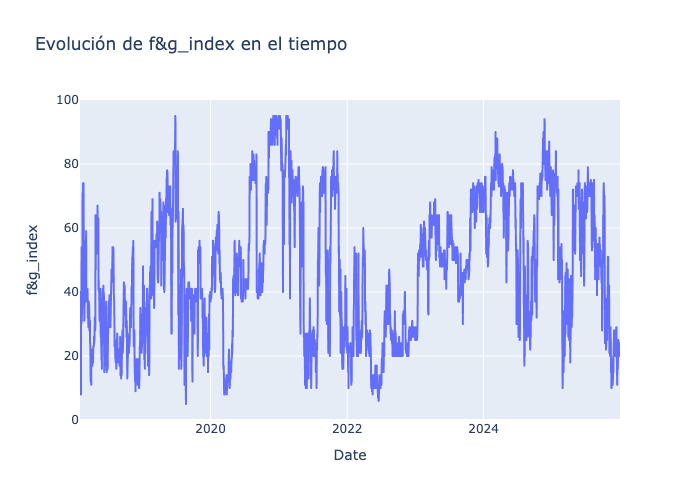

In [473]:
grafico(df,"f&g_index")

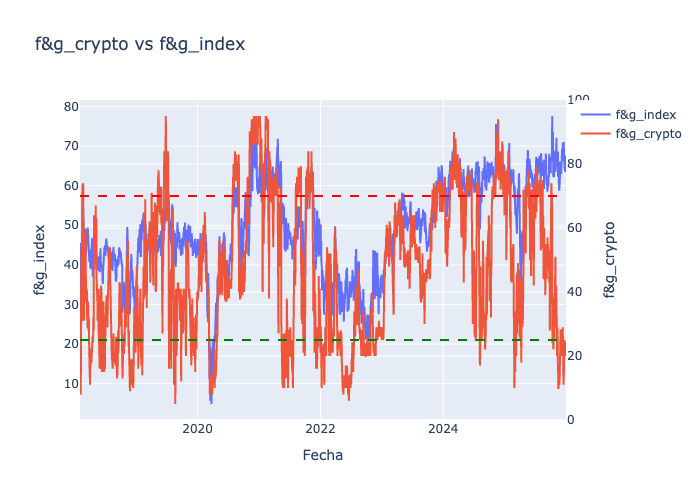

In [475]:
grafico_doble_eje(df_sp500_transfer,"f&g_index","f&g_crypto")

In [477]:
print("Numero de compras que va a realizar esta estrategia:",df_sp500[df_sp500_transfer["f&g_index"] < 25].shape[0])

Numero de compras que va a realizar esta estrategia: 62


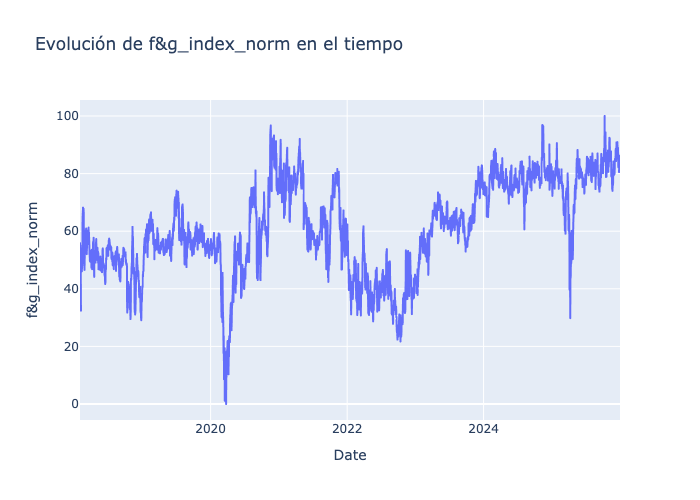

Numero de compras que va a realizar esta estrategia: 47


In [480]:
# podemos probar a normalizarlo como ya hicimos con el de las criptos
scaler_sp500_transfer = MinMaxScaler(feature_range = (0,100))
df_sp500_transfer["f&g_index_norm"] = scaler_sp500_transfer.fit_transform(df_sp500_transfer[["f&g_index"]])
grafico(df_sp500_transfer,"f&g_index_norm")
# parece que así es menos conservador
print("Numero de compras que va a realizar esta estrategia:",df_sp500[df_sp500_transfer["f&g_index_norm"] < 25].shape[0])                                                                        
                                                                          

#### COMPARACIÓN DE ESTRATEGIAS

##### DCA (2018-2026)

======================= S&P 500 ======================= 

La cantidad invertida por mes ha sido 105.26315789473684
El beneficio del Dollar Cost Average en el S&P500 es 7860.151
La rentabilidad es de 78.602%


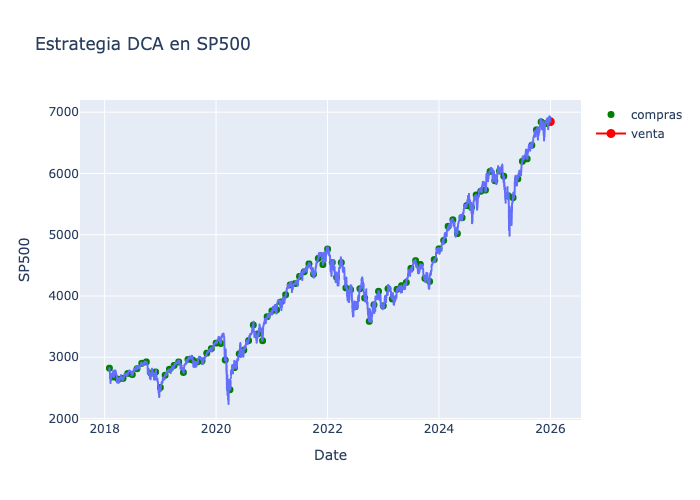

In [484]:
# creamos dataframe con las fechas de las compras
print("="*23, "S&P 500", "="*23, "\n")
compras_mensuales_sp500 = df.resample("MS").first()
num_cuotas_2018 = len(compras_mensuales_sp500)
cuota_sp500_2018 = presupuesto / num_cuotas_2018
sp500_acumulados_2018 = (cuota_sp500_2018 / compras_mensuales_sp500["SP500"]).sum()
precio_final_sp500 = df.loc["2025-12-31","SP500"]

valor_final_dca_sp500_2018 = sp500_acumulados_2018 * precio_final_sp500
beneficio_dca_sp500_2018 = valor_final_dca_sp500_2018 - presupuesto
rentabilidad_dca_sp500_2018 = beneficio_dca_sp500_2018 / presupuesto * 100
print(f"La cantidad invertida por mes ha sido {cuota_sp500_2018}")
print(f"El beneficio del Dollar Cost Average en el S&P500 es {beneficio_dca_sp500_2018.round(3)}")
print(f"La rentabilidad es de {rentabilidad_dca_sp500_2018.round(3)}%")

# representación visual
dca_sp500_2018 = px.line(df, 
                  x = df.index, 
                  y = df["SP500"], 
                  title = "Estrategia DCA en SP500")
dca_sp500_2018.add_scatter(x = compras_mensuales_sp500.index,
                    y = compras_mensuales_sp500["SP500"],
                    mode = "markers",
                    marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
dca_sp500_2018.add_scatter(x = ["2025-12-31"],
                    y =  [precio_final_sp500],
                    marker = dict(size = 9,
                                  color = "red",
                                  symbol = "circle"),
                                  name = "venta")
dca_sp500_2018.show()

##### INDICADOR FEAR & GREED CRYPTO (2018-2026)

======================= INDICADOR FEAR & GREED CRYPTO ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 17.88908765652952
La cantidad de BTC comprado ha sido de 2.851226436593112
El beneficio del Fear & Greed & Hold en Bitcoin es 9518.071
La rentabilidad es de 95.181%


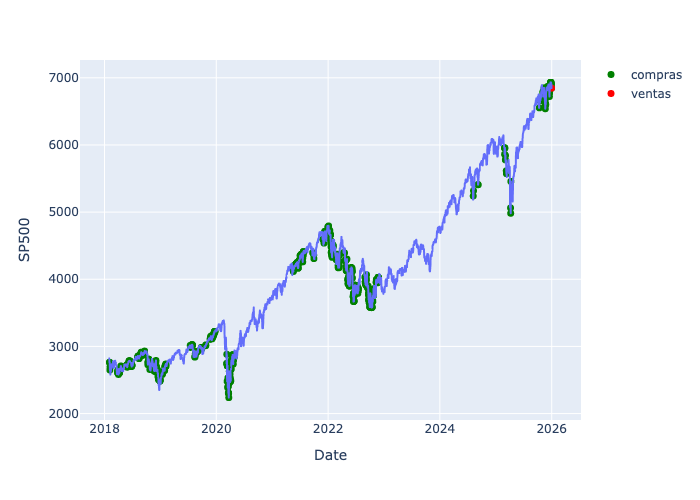

In [487]:
print("="*23, "INDICADOR FEAR & GREED CRYPTO", "="*23, "\n")
compras_sp500_2018 = df[df["f&g_index"] < 25]
cant_compras_sp500_2018 = df[df["f&g_index"] < 25].shape[0]
dinero_por_compra_sp500_2018 = presupuesto / cant_compras_sp500_2018
cantidad_sp500_2018 = (dinero_por_compra_sp500_2018 / compras_sp500_2018["SP500"]).sum()
beneficio_sp500_2018 = precio_final_sp500 * cantidad_sp500_2018 - presupuesto
rentabilidad_sp500_2018 = (beneficio_sp500_2018 / presupuesto) * 100
print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_sp500_2018}")
print(f"La cantidad de BTC comprado ha sido de {cantidad_sp500_2018}")
print(f"El beneficio del Fear & Greed & Hold en Bitcoin es {beneficio_sp500_2018.round(3)}")
print(f"La rentabilidad es de {rentabilidad_sp500_2018.round(3)}%")


fig_sp500_2018 = px.line(df,
                   x = df.index,
                   y = df["SP500"])
fig_sp500_2018.add_scatter( x = compras_sp500_2018.index,
                      y = compras_sp500_2018["SP500"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_sp500_2018.add_scatter( x = ["2025-12-31"],
                      y = [precio_final_sp500],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_sp500_2018.show()

##### BÚSQUEDA HEURÍSTICA DE PARÁMETROS (2018-2026)

======================= INDICADOR FEAR & GREED HEURÍSTICO ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 151.5151515151515
La cantidad de BTC comprado ha sido de 3.1027125715110104
El beneficio del Fear & Greed & Hold en S&P500 es 11239.619
La rentabilidad es de 112.396%


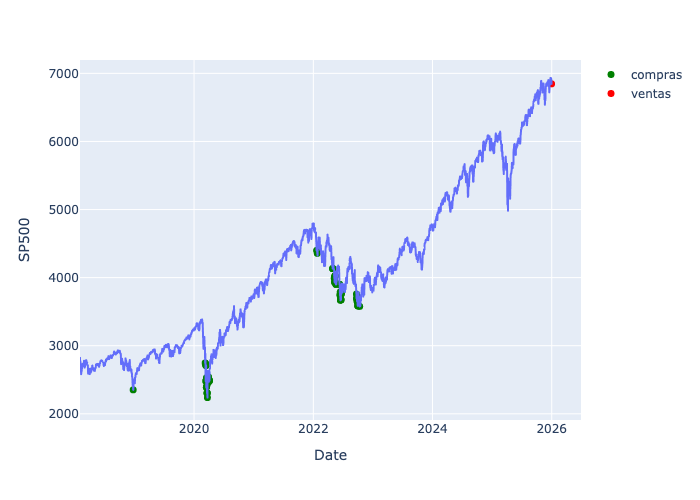

In [490]:
print("="*23, "INDICADOR FEAR & GREED HEURÍSTICO", "="*23, "\n")
compras_sp500_2018 = df_sp500[df_sp500_norm["f&g_index"] < 25]
cant_compras_sp500_2018 = df_sp500_norm[df_sp500_norm["f&g_index"] < 25].shape[0]
dinero_por_compra_sp500_2018 = presupuesto / cant_compras_sp500_2018
cantidad_sp500_2018 = (dinero_por_compra_sp500_2018 / compras_sp500_2018["SP500"]).sum()
beneficio_sp500_2018 = precio_final_sp500 * cantidad_sp500_2018 - presupuesto
rentabilidad_sp500_2018 = (beneficio_sp500_2018 / presupuesto) * 100
print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_sp500_2018}")
print(f"La cantidad de BTC comprado ha sido de {cantidad_sp500_2018}")
print(f"El beneficio del Fear & Greed & Hold en S&P500 es {beneficio_sp500_2018.round(3)}")
print(f"La rentabilidad es de {rentabilidad_sp500_2018.round(3)}%")


fig_sp500_2018 = px.line(df_sp500,
                   x = df_sp500.index,
                   y = df_sp500["SP500"])
fig_sp500_2018.add_scatter( x = compras_sp500_2018.index,
                      y = compras_sp500_2018["SP500"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_sp500_2018.add_scatter( x = ["2025-12-31"],
                      y = [precio_final_sp500],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_sp500_2018.show()

##### TRANSFER LEARNING (2018-2026)

###### TRANSFER LEARNING (INDICADOR SIN ESCALAR)

======================= INDICADOR FEAR & GREED MEDIANTE TRANSFER LEARNING SIN ESCALAR ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 161.29032258064515
La cantidad de SP500 comprado ha sido de 3.4495240747965754
El beneficio del Fear & Greed & Hold en SP500 es 13613.717
La rentabilidad es de 136.137%


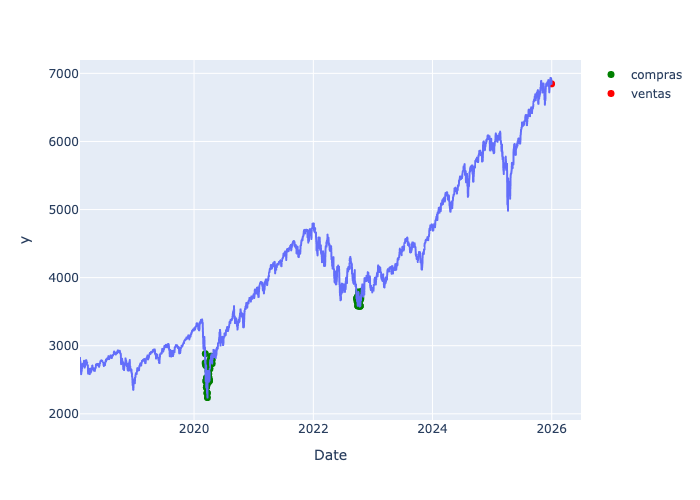

In [494]:
print("="*23, "INDICADOR FEAR & GREED MEDIANTE TRANSFER LEARNING SIN ESCALAR", "="*23, "\n")
compras_sp500_transfer = df_sp500[df_sp500_transfer["f&g_index"] < 25]
cant_compras_sp500_transfer = df_sp500[df_sp500_transfer["f&g_index"] < 25].shape[0]
dinero_por_compra_sp500_transfer = presupuesto / cant_compras_sp500_transfer
cantidad_sp500_transfer = (dinero_por_compra_sp500_transfer / compras_sp500_transfer["SP500"]).sum()
beneficio_sp500_transfer = df["SP500"].loc["2025-12-31"] * cantidad_sp500_transfer - presupuesto
rentabilidad_sp500_transfer = (beneficio_sp500_transfer / presupuesto) * 100
print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_sp500_transfer}")
print(f"La cantidad de SP500 comprado ha sido de {cantidad_sp500_transfer}")
print(f"El beneficio del Fear & Greed & Hold en SP500 es {beneficio_sp500_transfer.round(3)}")
print(f"La rentabilidad es de {rentabilidad_sp500_transfer.round(3)}%")


fig_sp500_transfer = px.line(df_sp500_transfer,
                   x = df_sp500_transfer.index,
                   y = df_sp500["SP500"])
fig_sp500_transfer.add_scatter( x = compras_sp500_transfer.index,
                      y = compras_sp500_transfer["SP500"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_sp500_transfer.add_scatter( x = ["2025-12-31"],
                      y = [df["SP500"].loc["2025-12-31"]],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_sp500_transfer.show()

###### TRANSFER LEARNING (INDICADOR ESCALADO)

======================= INDICADOR FEAR & GREED MEDIANTE TRANSFER LEARNING ESCALADO ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 212.7659574468085
La cantidad de SP500 comprado ha sido de 3.6070748137901725
El beneficio del Fear & Greed & Hold en SP500 es 14692.231
La rentabilidad es de 146.922%


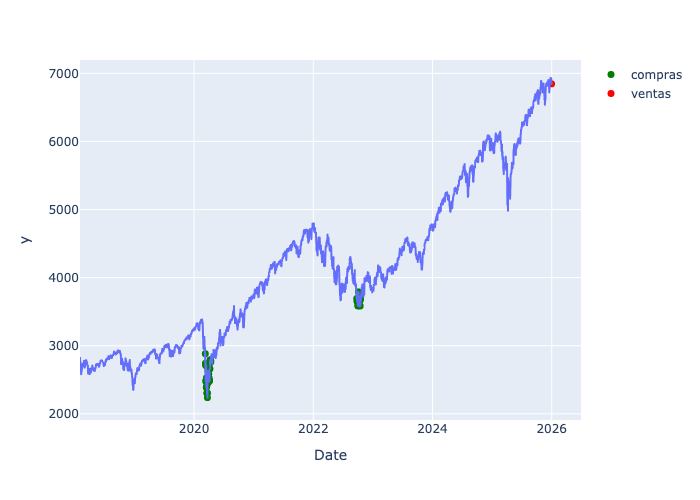

In [499]:

print("="*23, "INDICADOR FEAR & GREED MEDIANTE TRANSFER LEARNING ESCALADO", "="*23, "\n")
compras_sp500_transfer_norm = df_sp500[df_sp500_transfer["f&g_index_norm"] < 25]
cant_compras_sp500_transfer_norm = df_sp500[df_sp500_transfer["f&g_index_norm"] < 25].shape[0]
dinero_por_compra_sp500_transfer_norm = presupuesto / cant_compras_sp500_transfer_norm
cantidad_sp500_transfer_norm = (dinero_por_compra_sp500_transfer_norm / compras_sp500_transfer_norm["SP500"]).sum()
beneficio_sp500_transfer_norm = df["SP500"].loc["2025-12-31"] * cantidad_sp500_transfer_norm - presupuesto
rentabilidad_sp500_transfer_norm = (beneficio_sp500_transfer_norm / presupuesto) * 100
print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_sp500_transfer_norm}")
print(f"La cantidad de SP500 comprado ha sido de {cantidad_sp500_transfer_norm}")
print(f"El beneficio del Fear & Greed & Hold en SP500 es {beneficio_sp500_transfer_norm.round(3)}")
print(f"La rentabilidad es de {rentabilidad_sp500_transfer_norm.round(3)}%")


fig_sp500_transfer_norm = px.line(df_sp500_transfer,
                   x = df_sp500_transfer.index,
                   y = df_sp500["SP500"])
fig_sp500_transfer_norm.add_scatter( x = compras_sp500_transfer_norm.index,
                      y = compras_sp500_transfer_norm["SP500"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_sp500_transfer_norm.add_scatter( x = ["2025-12-31"],
                      y = [df["SP500"].loc["2025-12-31"]],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_sp500_transfer_norm.show()


## GOLD

### CONSTRUCCIÓN DEL INDICADOR FEAR & GREED DEL ORO

In [505]:
# vamos a añadir un tipo de búsqueda a este mercado sacada de Google Trends

gold_busqueda_1 = pd.read_csv("../data/google_trends/gold-2018-2022.csv")
gold_busqueda_2 = pd.read_csv("../data/google_trends/gold-2022-2025.csv")
gold_busqueda_1 = gold_busqueda_1.iloc[1:]
gold_busqueda_2 = gold_busqueda_2.iloc[1:]
gold_busqueda_1 = gold_busqueda_1.rename(columns={"Categoría: Todas las categorías":"gold_busqueda"})
gold_busqueda_2 = gold_busqueda_2.rename(columns={"Categoría: Todas las categorías":"gold_busqueda"})
gold_busqueda_1.index.name = "Date" # ponemos el nombre del index en todos
gold_busqueda_1.index = pd.to_datetime(gold_busqueda_1.index)
gold_busqueda_2.index.name = "Date" # ponemos el nombre del index en todos
gold_busqueda_2.index = pd.to_datetime(gold_busqueda_2.index)
gold_busqueda_1["gold_busqueda"] = pd.to_numeric(gold_busqueda_1["gold_busqueda"], errors='coerce')
gold_busqueda_2["gold_busqueda"] = pd.to_numeric(gold_busqueda_2["gold_busqueda"], errors='coerce')

#escalamos
factor_gold = gold_busqueda_1["gold_busqueda"].iloc[-1] / gold_busqueda_2["gold_busqueda"].iloc[0] # Factor de empalme 1
gold_busqueda_2_scaled = gold_busqueda_2["gold_busqueda"] * factor_gold # hacemos factor para empalmar
gold_busqueda = pd.concat([gold_busqueda_1["gold_busqueda"],gold_busqueda_2_scaled])

#dataframe
df_gold_busqueda = gold_busqueda.to_frame(name="gold_busqueda")
df_gold_busqueda.index = pd.to_datetime(df_gold_busqueda.index, format="%d-%m-%Y")
df_gold_busqueda = df_gold_busqueda[~df_gold_busqueda.index.duplicated(keep='first')] # borramos los duplicados 
df_gold_busqueda = df_gold_busqueda.resample('D').ffill() #convertimos en diario el semanal
df_gold_busqueda = df_gold_busqueda.loc["2018-02-01":"2025-12-31"]

df_gold_busqueda.tail()

,gold_busqueda
Date,
2025-12-24,135.200000
2025-12-25,135.200000
2025-12-26,135.200000
2025-12-27,135.200000
2025-12-28,138.666667


In [507]:
# Vamos a realizar lo mismo pero con el mercado del oro, para este dataframe vamos a necesitar más variables de crypto o del S&P500
# ya que el oro es el menos volátil y seguramente el más conservador
### CONSTRUCCIÓN DEL DATAFRAME DEL GOLD EN EL MISMO ORDEN DE LAS VARIABLES DEL DATAFRAME DE CRYPTO PARA HACER DESPUÉS UN TRANSFER LEARNING
df_gold = pd.DataFrame()
df_gold["BTC"] = df["BTC"]
df_gold["ETH"] = df["ETH"]
df_gold["SP500"] = df["SP500"]
df_gold["GOLD"] = df["GOLD"]
df_gold["volumen_acum_diario"] = gold["Volume"]
df_gold["volatilidad_med_diaria"] = (gold["High"] - gold["Low"]) / gold["Close"]
# dominancia de bitcoin (luego se puede cambiar por gold/silver o algo así). Vamos a ver como funciona
df_gold["dominancia_bitcoin"] = df["dominancia_bitcoin"]
df_gold["sent_alcista"] = survey_sentiments["Bullish"].astype("float")
# se procede a añadir las busquedas sacadas de google trends, vamos a dejar la variable de "bitcoin" igual para añadir al modelo
# algo más de volatilidad, ya que en el pasado todos nuestros modelos han sido demasiado conservadores y vamos a añadir
# la busqueda de "s&p500"
df_gold["btc_busqueda"] = df["btc_busqueda"] # la misma que en crypto
# la variable crypto_busqueda se ha cambiado por "sp500" para adaptarla mejor al mercado 
df_gold["gold_busqueda"] = df_gold_busqueda["gold_busqueda"]

df_gold["f&g_crypto"] = df["f&g_index"]

df_gold["GOLD_var"] = df_gold["GOLD"].pct_change()


#RSI
delta = df_gold['GOLD'].diff()
gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
rs = gain / loss
df_gold['RSI'] = 100 - (100 / (1 + rs))


# media móvil de 50 periodos del SP500
df_gold['dist_SMA_50'] = (df_gold['GOLD'] / df_gold['GOLD'].rolling(50).mean()) - 1


# varianza de GVZ
gvz = yf.download("^GVZ", start = "2018-02-01", end = "2026-12-31")
gvz = gvz["Close"].rename(columns={"Close":"gvz"})
df_gold["gvz"] = gvz
# tratamos aquí el GVZ de igual forma que el VIX del S&P 50
df_gold["gvz"] = df_gold["gvz"].ffill()
df_gold["var_gvz"] = df_gold["gvz"].pct_change()


#roc 15 días
df_gold['roc_15d'] = df_gold["GOLD"].pct_change(periods=15)


# Variación de hoy comparada con la media de variación de los ultimos 20 días
gold['diario_range'] = (gold['High'] - gold['Low']) / gold['Close']
df_gold['range_relative'] = gold['diario_range'] / gold['diario_range'].rolling(20).mean()


# Volatilidad 7 días
df_gold['GOLD_vol_7'] = df_gold['GOLD_var'].rolling(window=7).std() * 100


## BANDAS DE BOLLINGER
# Media móvil 20 días
df_gold['sma_20'] = df_gold['GOLD'].rolling(window=20).mean()
# Desviación estándar
df_gold['std_20'] = df_gold['GOLD'].rolling(window=20).std()
# Banda Inferior y Superior
df_gold['bollinger_low'] = df_gold['sma_20'] - (2 * df_gold['std_20'])
# LA VARIABLE PARA EL MODELO: ¿A qué distancia está el precio de la banda inferior?
df_gold['dist_bollinger_low'] = (df_gold['GOLD'] - df_gold['bollinger_low']) / df_gold['bollinger_low']
df_gold = df_gold.drop(["bollinger_low","std_20","sma_20"], axis = 1)

# distancia al máximo de 30 y 60 días
max_60d = df_gold["GOLD"].rolling(window=60).max()
df_gold['drawdown_60d'] = (df_gold["GOLD"] - max_60d) / max_60d

max_30d = df_gold["GOLD"].rolling(window=30).max()
df_gold['drawdown_30d'] = (df_gold["GOLD"] - max_30d) / max_30d

[*********************100%***********************]  1 of 1 completed


In [509]:
df_gold.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2891 entries, 2018-02-01 to 2025-12-31
Freq: D
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   BTC                     2891 non-null   float64
 1   ETH                     2891 non-null   float64
 2   SP500                   2891 non-null   float64
 3   GOLD                    2891 non-null   float64
 4   volumen_acum_diario     1993 non-null   float64
 5   volatilidad_med_diaria  1993 non-null   float64
 6   dominancia_bitcoin      2891 non-null   float64
 7   sent_alcista            2891 non-null   float64
 8   btc_busqueda            2891 non-null   float64
 9   gold_busqueda           2888 non-null   float64
 10  f&g_crypto              2891 non-null   float64
 11  GOLD_var                2890 non-null   float64
 12  RSI                     2878 non-null   float64
 13  dist_SMA_50             2842 non-null   float64
 14  gvz           

### ANÁLISIS EXPLORATORIO

En esta ocasión se va a realizar un análisis exploratorio más breve ya que
las variables del oro van a tener los mismos problemas que tenian las del S&P500

-----Estamos analizando la columna BTC -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count      2891.000000
mean      37533.248951
std       32287.797550
min        3236.761719
25%        9412.226562
50%       27702.349609
75%       57626.300781
max      124752.531250
Name: BTC, dtype: float64


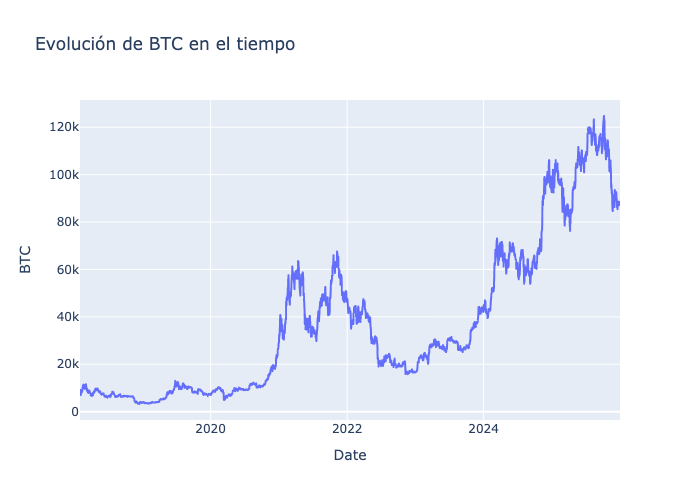

-----Estamos analizando la columna ETH -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean     1712.108484
std      1303.347852
min        84.308296
25%       337.177643
50%      1677.846802
75%      2719.970093
max      4831.348633
Name: ETH, dtype: float64


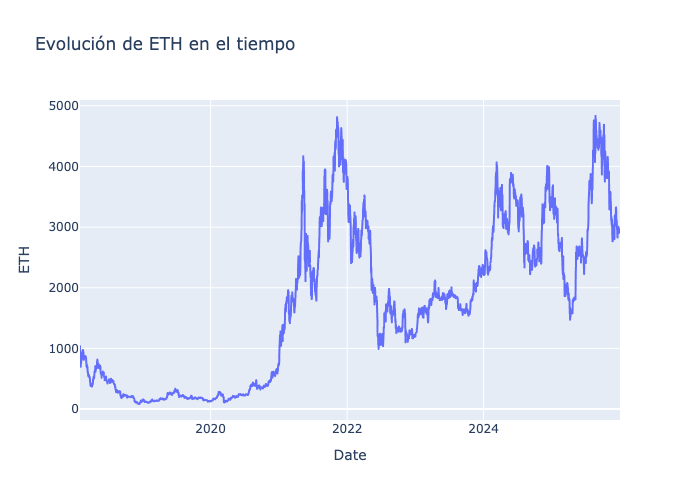

-----Estamos analizando la columna SP500 -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean     4160.845385
std      1170.317349
min      2237.399902
25%      3024.900024
50%      4101.229980
75%      4783.400146
max      6932.049805
Name: SP500, dtype: float64


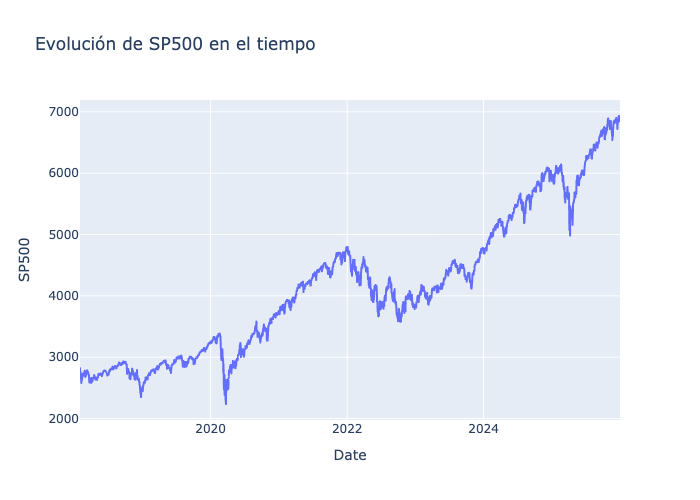

-----Estamos analizando la columna GOLD -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean     1989.592770
std       677.593010
min      1176.199951
25%      1557.450012
50%      1834.800049
75%      2042.449951
max      4552.700195
Name: GOLD, dtype: float64


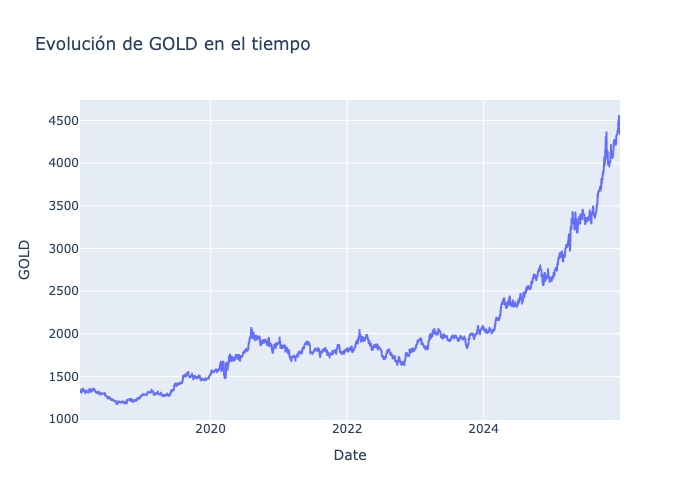

-----Estamos analizando la columna volumen_acum_diario -----
Esta columna tiene 898 nulos
Sus estadísticos descriptivos son:
 count      1993.000000
mean     143374.754641
std      108470.444294
min           0.000000
25%         702.000000
50%      163912.000000
75%      216784.000000
max      569847.000000
Name: volumen_acum_diario, dtype: float64


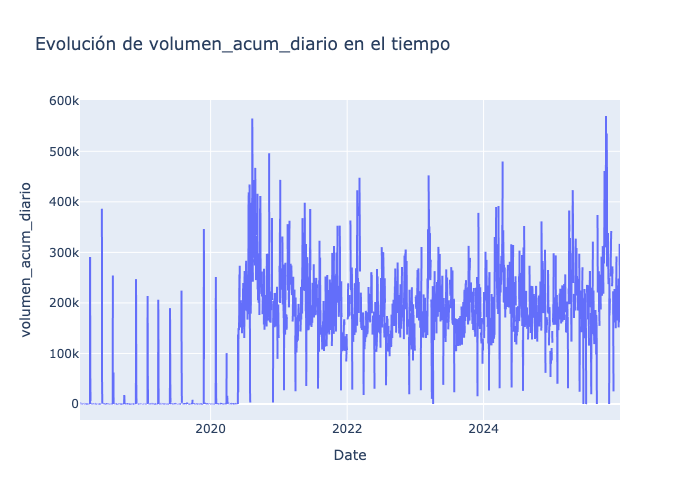

-----Estamos analizando la columna volatilidad_med_diaria -----
Esta columna tiene 898 nulos
Sus estadísticos descriptivos son:
 count    1993.000000
mean        0.013111
std         0.008444
min         0.000000
25%         0.007994
50%         0.011887
75%         0.016669
max         0.078740
Name: volatilidad_med_diaria, dtype: float64


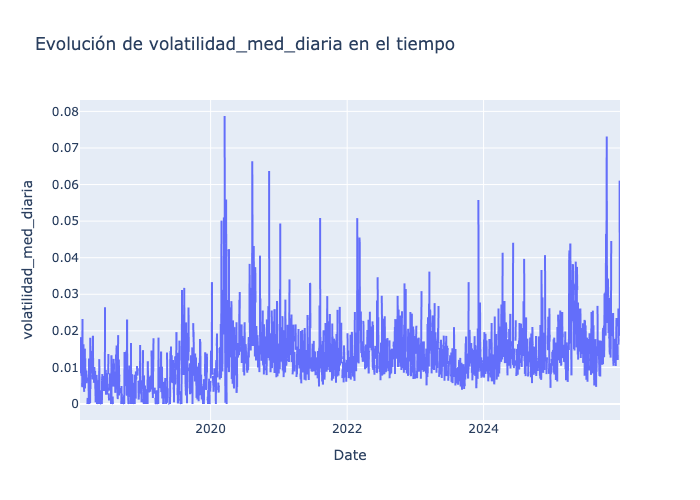

-----Estamos analizando la columna dominancia_bitcoin -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean       54.276301
std         9.032488
min        34.829151
25%        45.789871
50%        54.847237
75%        61.475946
max        73.358926
Name: dominancia_bitcoin, dtype: float64


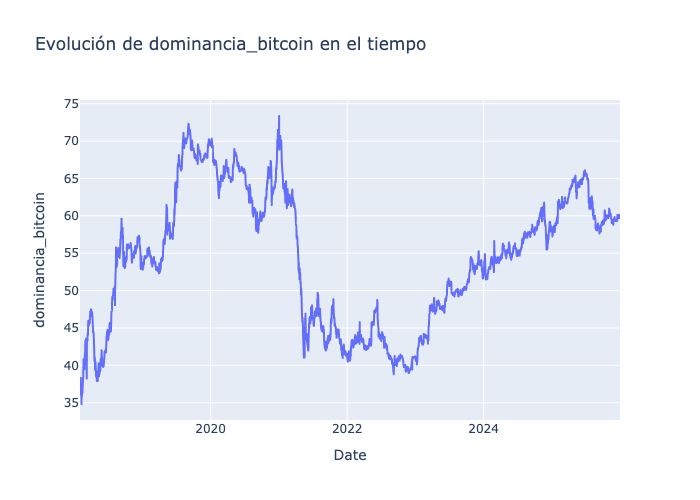

-----Estamos analizando la columna sent_alcista -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean        0.349360
std         0.087001
min         0.158371
25%         0.283951
50%         0.347418
75%         0.416327
max         0.569079
Name: sent_alcista, dtype: float64


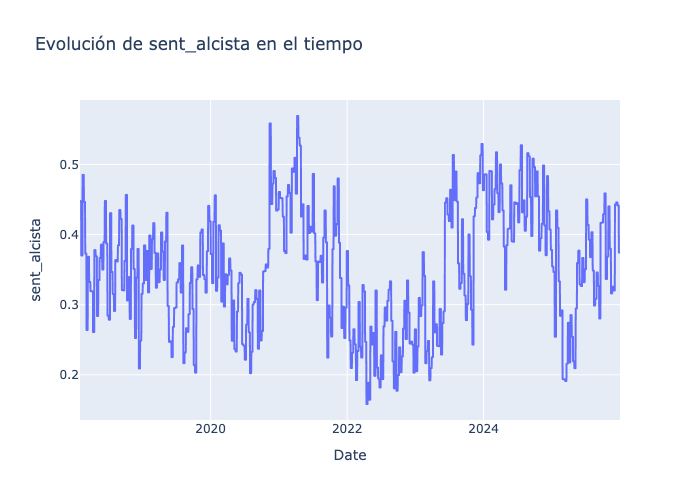

-----Estamos analizando la columna btc_busqueda -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean       21.493076
std        14.580949
min         9.000000
25%        13.481481
50%        17.000000
75%        22.000000
max        99.000000
Name: btc_busqueda, dtype: float64


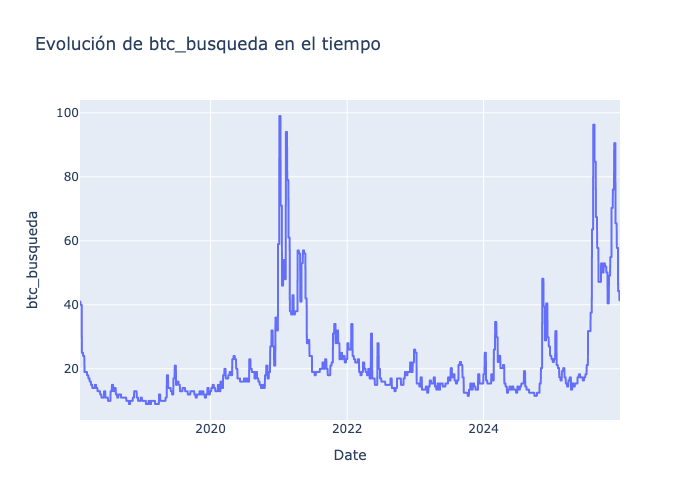

-----Estamos analizando la columna gold_busqueda -----
Esta columna tiene 3 nulos
Sus estadísticos descriptivos son:
 count    2888.000000
mean       76.145268
std        17.751919
min        50.000000
25%        65.000000
50%        73.000000
75%        83.200000
max       173.333333
Name: gold_busqueda, dtype: float64


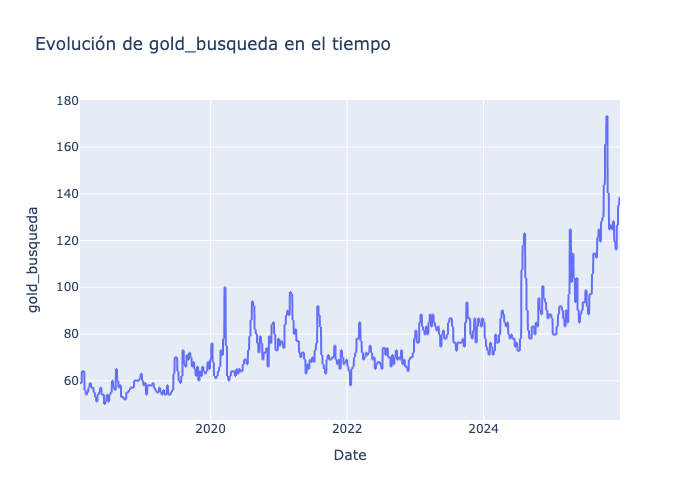

-----Estamos analizando la columna f&g_crypto -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean       47.142857
std        21.707572
min         5.000000
25%        28.000000
50%        47.000000
75%        66.000000
max        95.000000
Name: f&g_crypto, dtype: float64


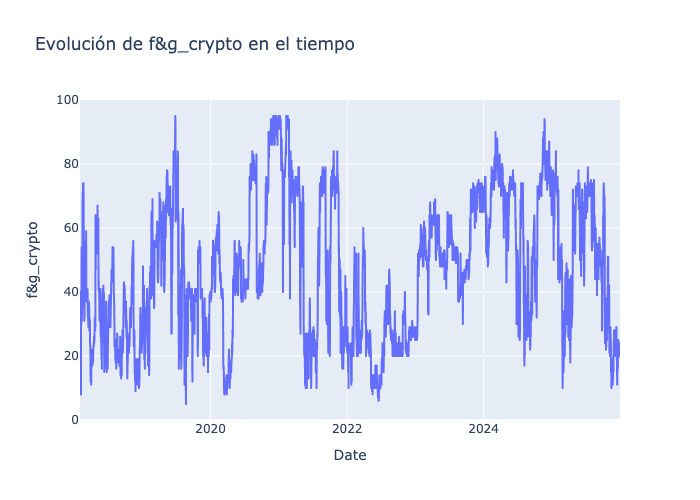

-----Estamos analizando la columna GOLD_var -----
Esta columna tiene 1 nulos
Sus estadísticos descriptivos son:
 count    2890.000000
mean        0.000441
std         0.008385
min        -0.057416
25%        -0.001662
50%         0.000000
75%         0.003377
max         0.059477
Name: GOLD_var, dtype: float64


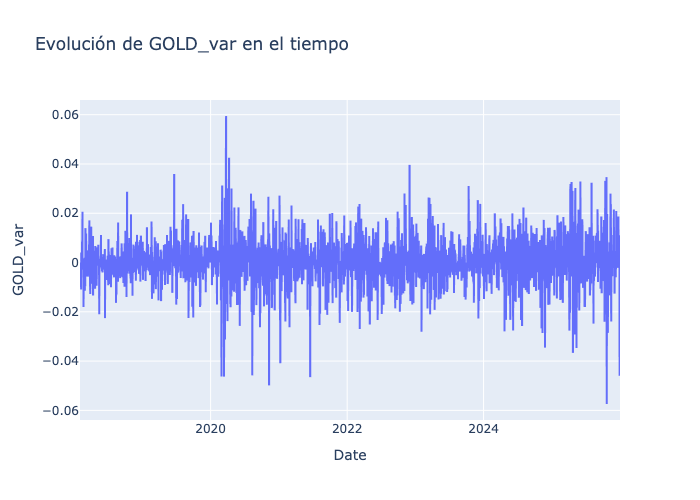

-----Estamos analizando la columna RSI -----
Esta columna tiene 13 nulos
Sus estadísticos descriptivos son:
 count    2878.000000
mean       54.131935
std        19.593932
min         0.485909
25%        40.617248
50%        53.469727
75%        68.733257
max       100.000000
Name: RSI, dtype: float64


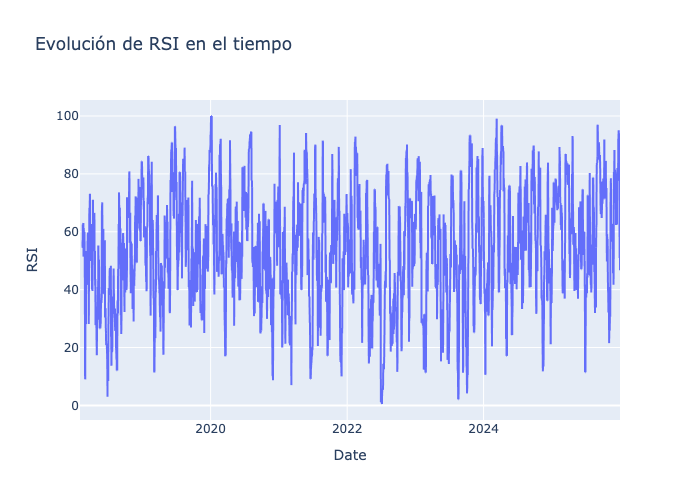

-----Estamos analizando la columna dist_SMA_50 -----
Esta columna tiene 49 nulos
Sus estadísticos descriptivos son:
 count    2842.000000
mean        0.010476
std         0.029366
min        -0.072924
25%        -0.009234
50%         0.007019
75%         0.029598
max         0.134759
Name: dist_SMA_50, dtype: float64


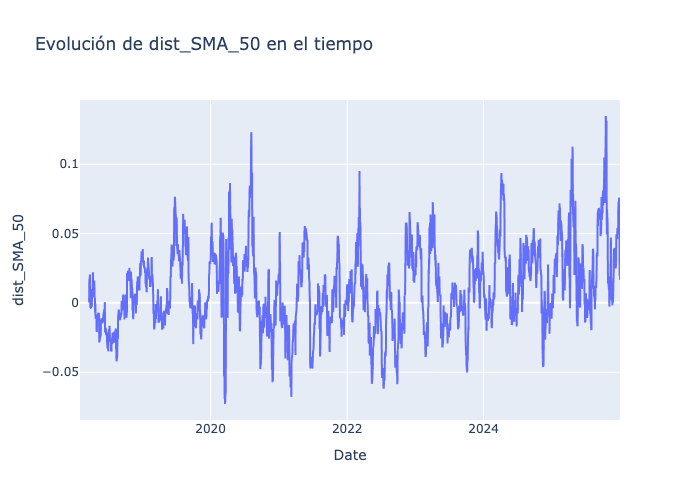

-----Estamos analizando la columna gvz -----
Esta columna tiene 0 nulos
Sus estadísticos descriptivos son:
 count    2891.000000
mean       16.378969
std         4.447011
min         8.880000
25%        13.080000
50%        16.030001
75%        18.495000
max        48.980000
Name: gvz, dtype: float64


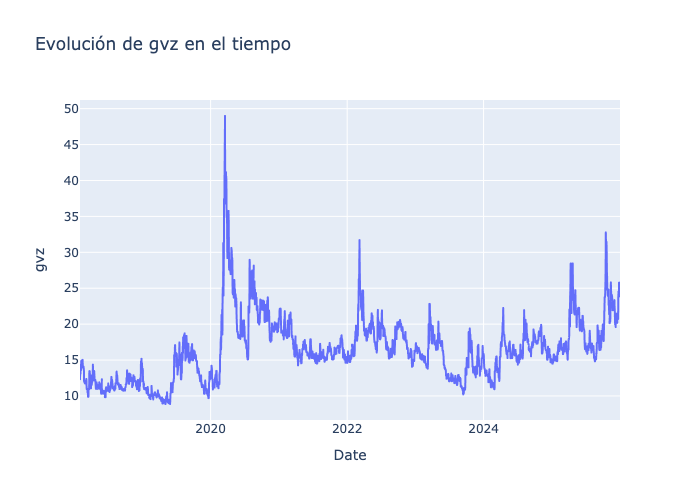

-----Estamos analizando la columna var_gvz -----
Esta columna tiene 1 nulos
Sus estadísticos descriptivos son:
 count    2890.000000
mean        0.001127
std         0.043161
min        -0.233301
25%        -0.016465
50%         0.000000
75%         0.008140
max         0.352647
Name: var_gvz, dtype: float64


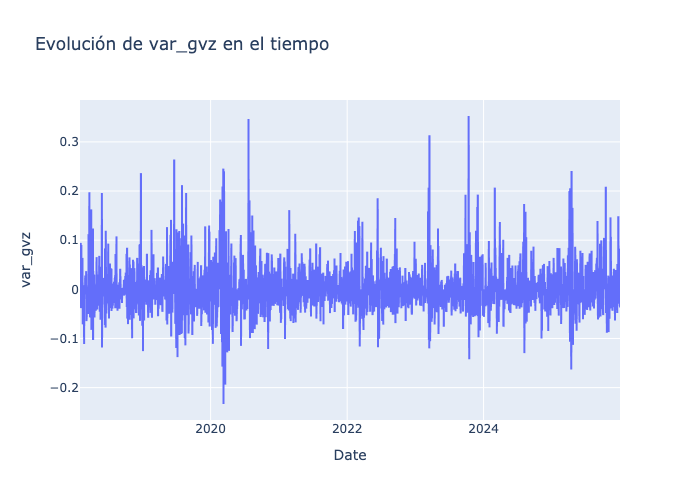

-----Estamos analizando la columna roc_15d -----
Esta columna tiene 15 nulos
Sus estadísticos descriptivos son:
 count    2876.000000
mean        0.006737
std         0.029315
min        -0.111803
25%        -0.011578
50%         0.004205
75%         0.024423
max         0.149919
Name: roc_15d, dtype: float64


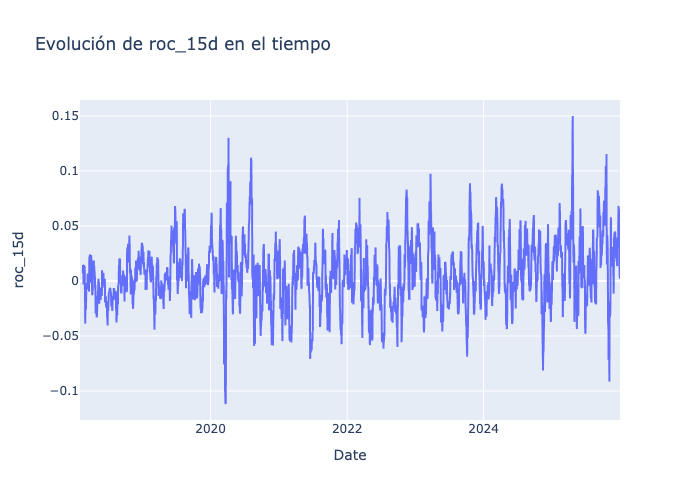

-----Estamos analizando la columna range_relative -----
Esta columna tiene 917 nulos
Sus estadísticos descriptivos son:
 count    1974.000000
mean        1.017070
std         0.598645
min         0.000000
25%         0.669723
50%         0.913842
75%         1.234469
max         5.249888
Name: range_relative, dtype: float64


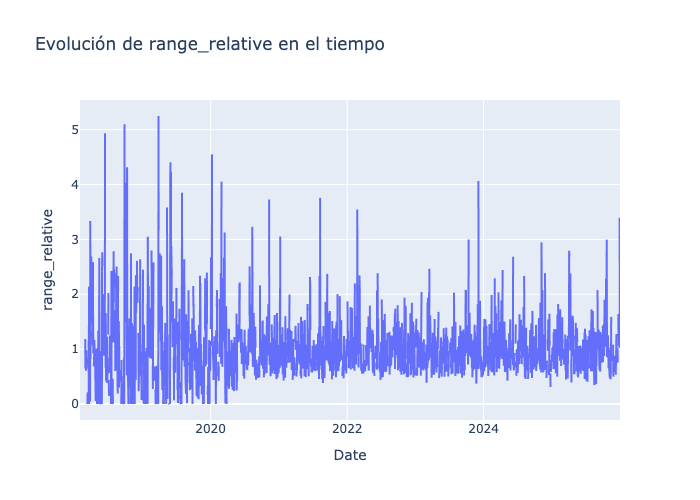

-----Estamos analizando la columna GOLD_vol_7 -----
Esta columna tiene 7 nulos
Sus estadísticos descriptivos son:
 count    2884.000000
mean        0.734404
std         0.410874
min         0.104142
25%         0.448235
50%         0.646581
75%         0.922136
max         3.298883
Name: GOLD_vol_7, dtype: float64


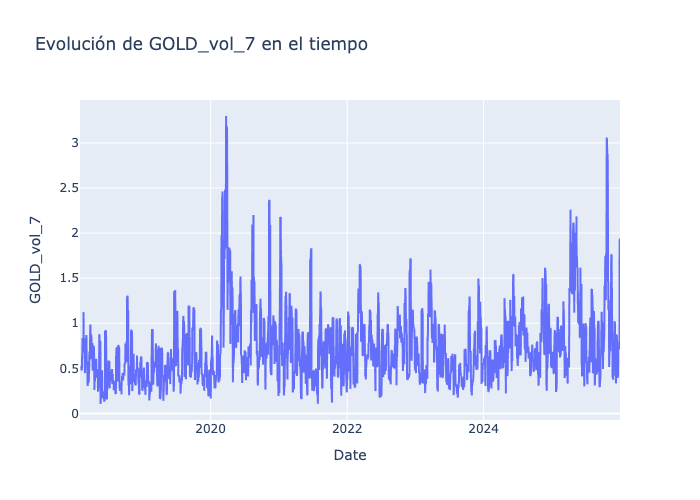

-----Estamos analizando la columna dist_bollinger_low -----
Esta columna tiene 19 nulos
Sus estadísticos descriptivos son:
 count    2872.000000
mean        0.031080
std         0.027988
min        -0.026747
25%         0.012015
50%         0.023257
75%         0.042647
max         0.180096
Name: dist_bollinger_low, dtype: float64


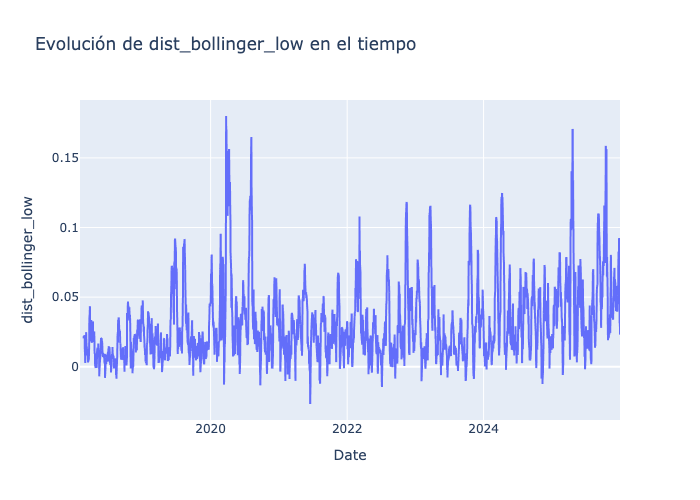

-----Estamos analizando la columna drawdown_60d -----
Esta columna tiene 59 nulos
Sus estadísticos descriptivos son:
 count    2832.000000
mean       -0.029419
std         0.024816
min        -0.130935
25%        -0.045780
50%        -0.026686
75%        -0.007045
max         0.000000
Name: drawdown_60d, dtype: float64


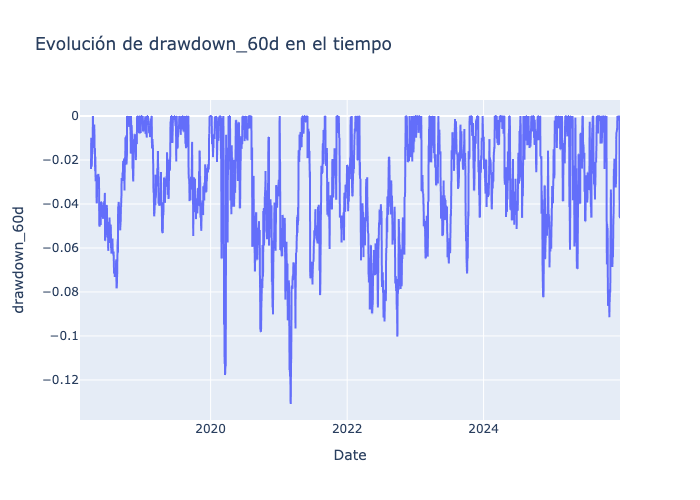

-----Estamos analizando la columna drawdown_30d -----
Esta columna tiene 29 nulos
Sus estadísticos descriptivos son:
 count    2862.000000
mean       -0.021488
std         0.020429
min        -0.117766
25%        -0.033181
50%        -0.016440
75%        -0.004145
max         0.000000
Name: drawdown_30d, dtype: float64


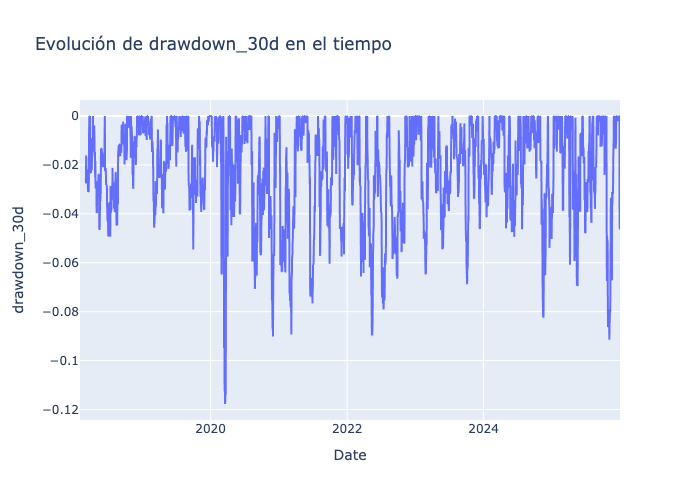

In [513]:
for i in df_gold.columns:
    cuantitativa(df_gold,i)
    grafico(df_gold,i)

In [515]:
# se realiza el mismo procesamiento que se realizo en el S&P 500 ya que los dataframe son prácticamente iguales
df_gold["volumen_acum_diario"] = df_gold["volumen_acum_diario"].ffill()
df_gold["volatilidad_med_diaria"] = df_gold["volatilidad_med_diaria"].ffill()
df_gold["gold_busqueda"] = df_gold["gold_busqueda"].ffill()
df_gold["GOLD_var"] = df_gold["GOLD_var"].bfill()
df_gold["RSI"] = df_gold["RSI"].bfill()
df_gold["dist_SMA_50"] = df_gold["dist_SMA_50"].bfill()
df_gold["GOLD_vol_7"] = df_gold["GOLD_vol_7"].bfill()
df_gold["var_gvz"] = df_gold["var_gvz"].bfill()
df_gold["roc_15d"] = df_gold["roc_15d"].bfill()
df_gold['range_relative'] = df_gold['range_relative'].ffill().bfill()
df_gold["dist_bollinger_low"] = df_gold["dist_bollinger_low"].bfill()
df_gold["drawdown_60d"] = df_gold["drawdown_60d"].bfill()
df_gold["drawdown_30d"] = df_gold["drawdown_30d"].bfill() 

In [517]:
# no queda ningún nulo por tratar
df_gold.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2891 entries, 2018-02-01 to 2025-12-31
Freq: D
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   BTC                     2891 non-null   float64
 1   ETH                     2891 non-null   float64
 2   SP500                   2891 non-null   float64
 3   GOLD                    2891 non-null   float64
 4   volumen_acum_diario     2891 non-null   float64
 5   volatilidad_med_diaria  2891 non-null   float64
 6   dominancia_bitcoin      2891 non-null   float64
 7   sent_alcista            2891 non-null   float64
 8   btc_busqueda            2891 non-null   float64
 9   gold_busqueda           2891 non-null   float64
 10  f&g_crypto              2891 non-null   float64
 11  GOLD_var                2891 non-null   float64
 12  RSI                     2891 non-null   float64
 13  dist_SMA_50             2891 non-null   float64
 14  gvz           

### ANÁLISIS BIVARIANTE

##### dominancia_bitcoin vs GOLD

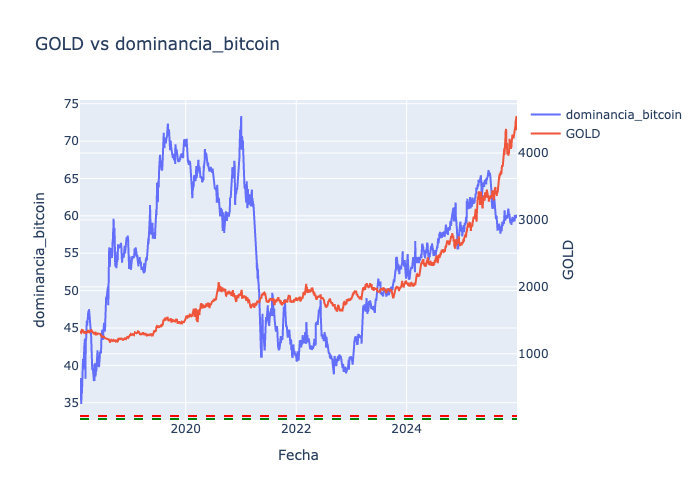

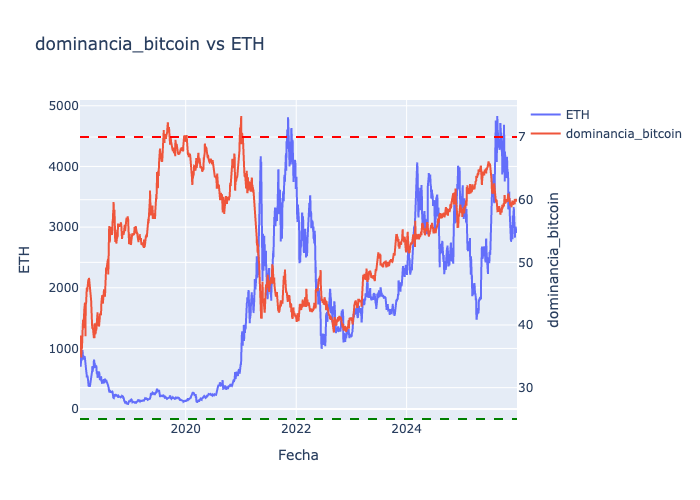

In [521]:
# se puede observar como en el periodo lateral del oro es cuando
# bitcoin pierde su dominancia
grafico_doble_eje(df_gold,"dominancia_bitcoin","GOLD")
grafico_doble_eje(df_gold,"ETH","dominancia_bitcoin")

##### gvz vs GOLD

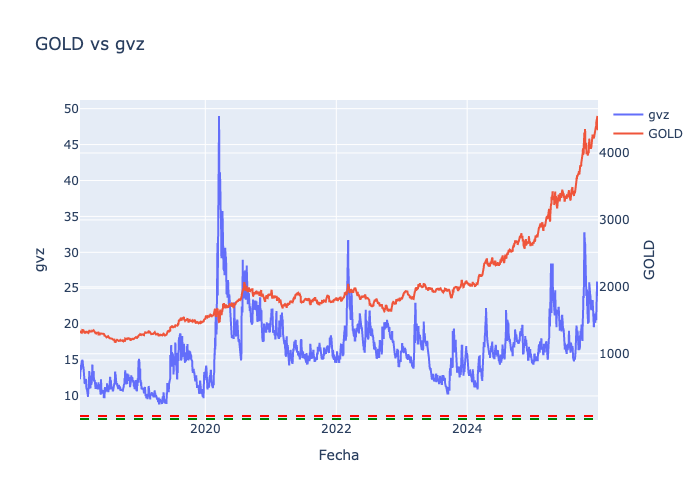

In [524]:
grafico_doble_eje(df_gold,"gvz","GOLD")

##### GOLD_var vs f&g_crypto

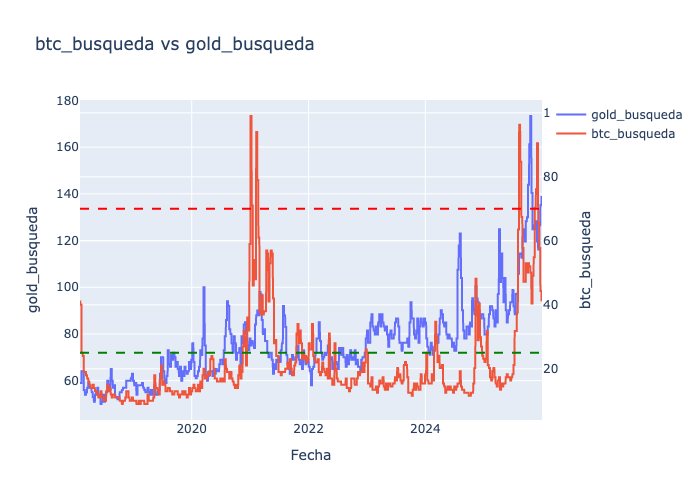

In [527]:

grafico_doble_eje(df_gold,"gold_busqueda","btc_busqueda")

##### GOLD_vol_7 vs gvz vs gold_busqueda

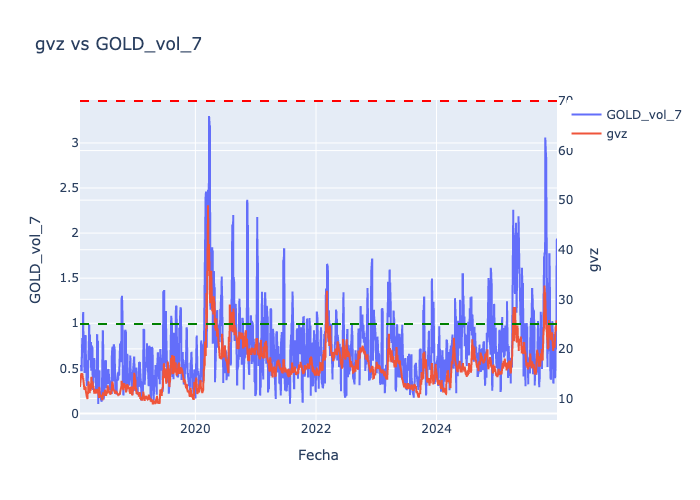

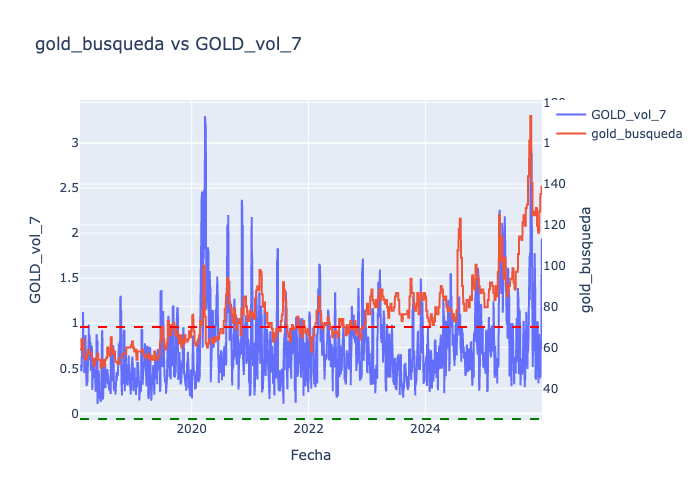

In [530]:

grafico_doble_eje(df_gold,"GOLD_vol_7","gvz")
grafico_doble_eje(df_gold,"GOLD_vol_7","gold_busqueda")


##### gvz vs. f&g_crypto

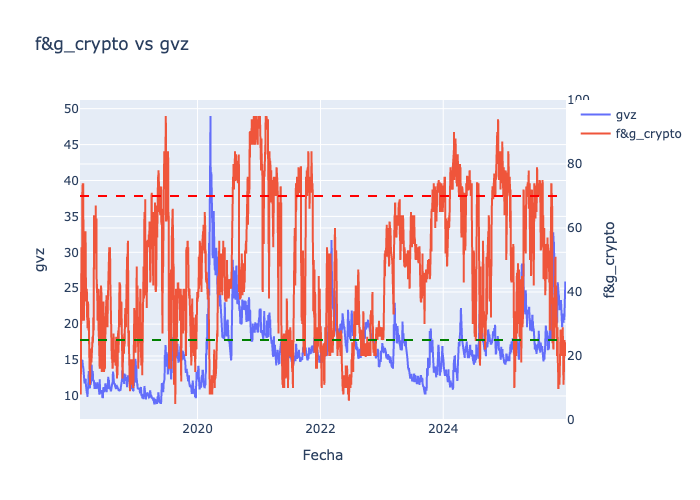

In [533]:
grafico_doble_eje(df_gold,"gvz","f&g_crypto")

### ANÁLISIS MULTIVARIANTE

In [536]:
df_gold.corr()["GOLD"].sort_values(ascending = False)

GOLD                      1.000000
SP500                     0.912947
BTC                       0.891334
gold_busqueda             0.880762
ETH                       0.658280
volumen_acum_diario       0.521642
btc_busqueda              0.487720
gvz                       0.428587
volatilidad_med_diaria    0.372678
dist_SMA_50               0.367456
dist_bollinger_low        0.344719
GOLD_vol_7                0.280652
dominancia_bitcoin        0.243462
roc_15d                   0.239712
RSI                       0.206298
f&g_crypto                0.159259
sent_alcista              0.120401
drawdown_60d              0.095510
GOLD_var                  0.055933
drawdown_30d              0.011651
var_gvz                   0.008489
range_relative           -0.003060
Name: GOLD, dtype: float64

<Axes: >

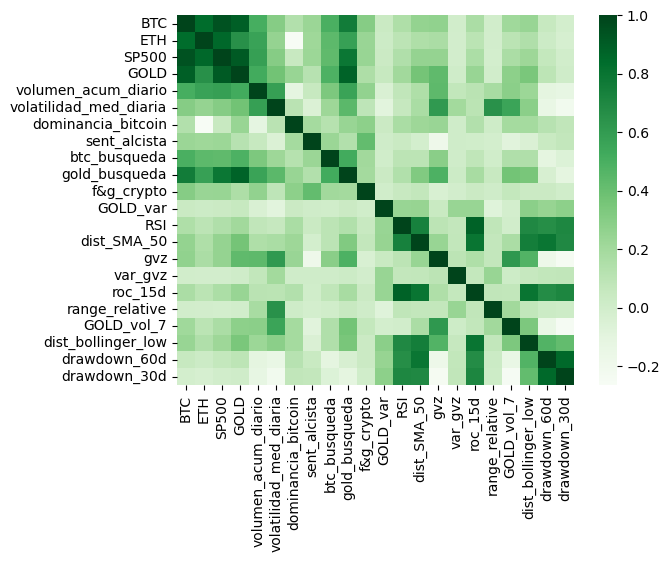

In [538]:
sns.heatmap(df_gold.corr(),cmap = "Greens")

#### BUSQUEDA HEURÍSTICA DE PARÁMETROS

Nulos en la variable: DFII10    87
dtype: int64


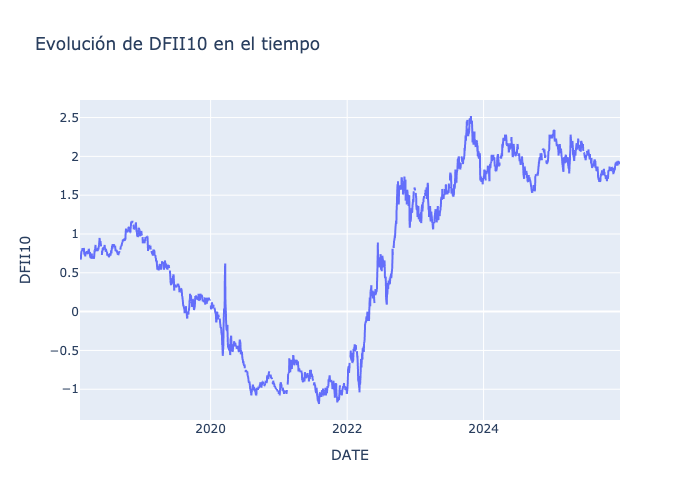

Nulos en la variable: 0


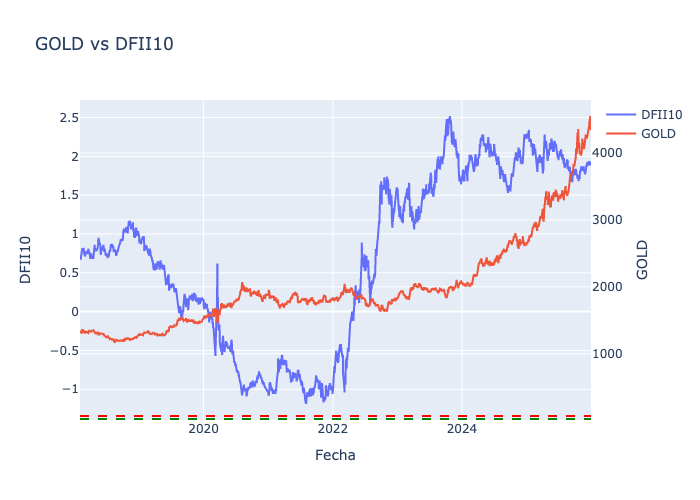

In [541]:
# Esta variable es el tipo interés real de los bonos del tesoro de EEUU a 10 años
# esta variable es importante ya que si los bonos suben y dan más interes los inversores prefieren los bonos que dan intereses
# y venderán el oro lo que puede dar lugar a correcciones en el oro. Si los intereses de los bonos bajan los inversores compran oro
# produciendose lo contrario
# El ticker 'DFII10' es el tipo real a 10 años (TIPS)

df_gold_norm = df_gold.copy() # creamos la copia del dataframe anterior para añadir más variables

start = datetime.datetime(2018, 2, 1)
end = datetime.datetime(2025, 12, 31)

real_rate = web.DataReader("DFII10", "fred", start, end)
print("Nulos en la variable:",real_rate.isna().sum())

# tenemos que ver de donde vienen los nulos
grafico(real_rate,"DFII10")

# solo hay 87 nulos con lo que procederemos a hacer un ffill con los datos que faltan de los fines de semana
df_gold_norm["DFII10"] = real_rate
df_gold_norm["DFII10"] = df_gold_norm["DFII10"].ffill()
print("Nulos en la variable:",df_gold_norm["DFII10"].isna().sum())
# comparamos el DFII10 con el precio del oro a ver si hay algun tipo de correlación inversa
grafico_doble_eje(df_gold_norm,"DFII10","GOLD")


In [543]:
# escalamos los datos para que el indicador este entre 0 y 100
scaler_gold = MinMaxScaler(feature_range=(0,100))
columnas_gold = ['BTC', 'SP500', 'GOLD', 'f&g_crypto', 'dist_SMA_50', 'drawdown_60d',
       'drawdown_30d', 'roc_15d', 'RSI',"gvz","sent_alcista","DFII10"]
for col in columnas_gold:
    df_gold_norm[col] = scaler_gold.fit_transform(df_gold_norm[[col]])



In [545]:
# Los parámetros se han seleccionado a partir de prueba y error para maximizar la rentabilidad

var_mercado = (df_gold_norm["BTC"] * 0.33 + 
                 df_gold_norm["SP500"] * 0.33 + 
                 df_gold_norm["GOLD"] * 0.33)

var_tecnico = (df_gold_norm['drawdown_60d'] * 0.2 + 
                 df_gold_norm['drawdown_30d'] * 0.2 + 
                 df_gold_norm['dist_SMA_50'] * 0.2 + 
                 df_gold_norm['RSI'] * 0.30 + 
                 df_gold_norm['roc_15d'] * 0.1)

var_sentimiento = (  df_gold_norm['f&g_crypto'] * 0.3 +
                     df_gold_norm["gvz"] * 0.3 +
                     df_gold_norm["DFII10"] * 0.2 +
                     df_gold_norm["sent_alcista"] * 0.2 )

df_gold_norm["f&g_index"] = (var_mercado * 0.2 + 
                             var_tecnico * 0.2 +
                             var_sentimiento * 0.6)

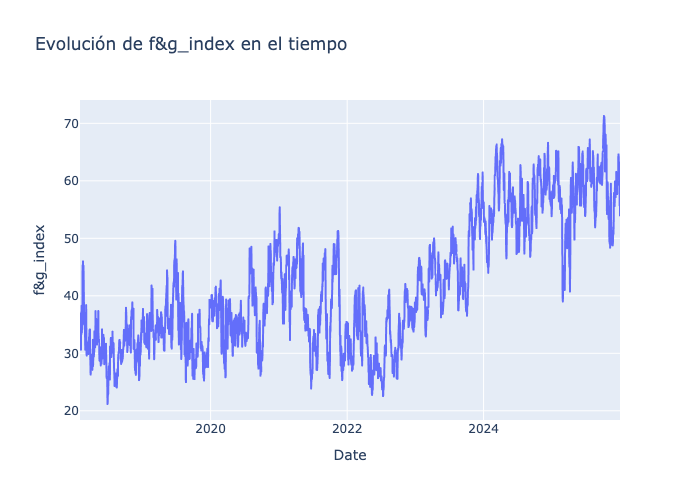

In [547]:
# Al ser el oro mucho más conservador el fear & greed que hemos hecho apenas toca las bandas de codicia y de miedo a lo largo de los años
grafico(df_gold_norm,"f&g_index")

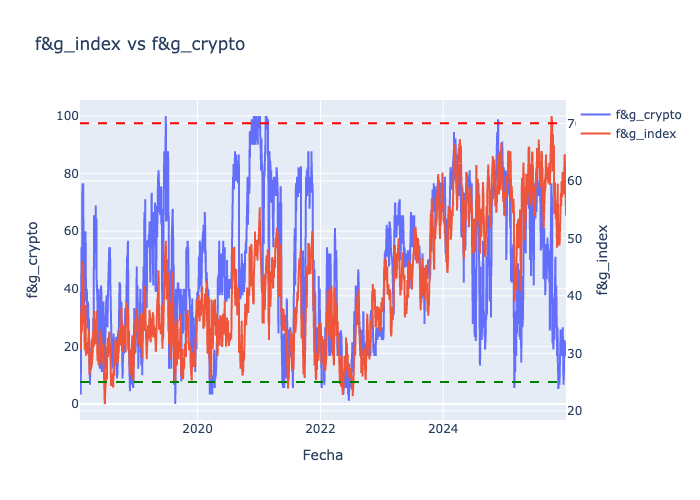

In [549]:
# Comparación índice en crypto con índice sintético en GOLD
grafico_doble_eje(df_gold_norm,"f&g_crypto","f&g_index")

#### PCA

In [552]:
df_gold_pca = df_gold.copy()

------------------------- SIN ESCALAR -------------------------


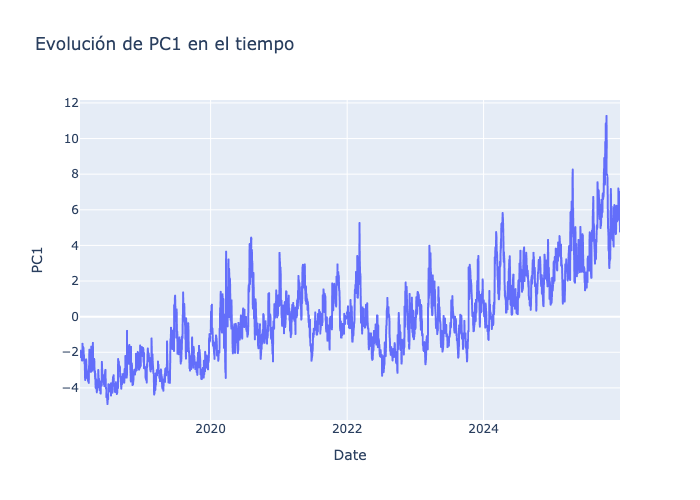

------------------------- ESCALADA -------------------------


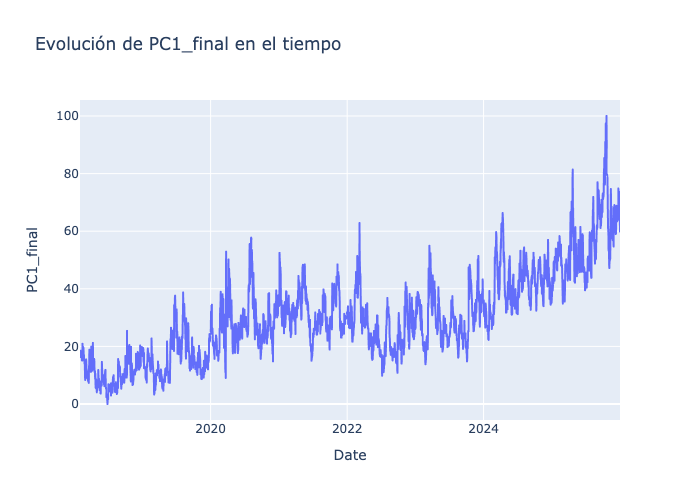

In [554]:
scaler_pca = StandardScaler()
df_gold_pca_scaled = scaler_pca.fit_transform(df_gold_pca)


pca_gold = PCA(n_components=1)
pc1 = pca_gold.fit_transform(df_gold_pca_scaled)

# Usamos el mismo índice del dataframe original para no perder las fechas
df_gold_pc1 = pd.DataFrame(data=pc1, columns=['PC1'], index=df_gold_pca.index)
print("-"*25,"SIN ESCALAR","-"*25)
grafico(df_gold_pc1,"PC1")

# debido a que tiene un pico muy grande se procede a hacer un MinMaxScaler
print("-" * 25, "ESCALADA", "-" * 25)
final_scaler_gold = MinMaxScaler(feature_range=(0, 100))

df_gold_pc1["PC1_final"] = final_scaler_gold.fit_transform(df_gold_pc1[["PC1"]])
grafico(df_gold_pc1,"PC1_final")

# mismo resultado que en el S&P 500. No se consiguen resultados esperados

#### TRANSFER LEARNING

In [557]:
df_gold_transfer = df_gold.copy()

# tenemos que cambiar los nombres de las variables ya que vamos a hacer .fit con
# el mismo escalador con el que se hizo el modelo de las criptos y si no da fallo
df_gold_transfer = df_gold_transfer.rename(columns={
    "GOLD_var" : "BTC_var",
    "GOLD_vol_7" : "BTC_vol_7",
    "gold_busqueda" : "crypto_busqueda",
    "gvz" : "vix",
    "var_gvz" : "var_vix"  

   })


# vamos a utilizar el modelo XGboost que utilizamos para las criptos para hacer un predict del S&P500 y ver como funciona
X_gold_transfer = df_gold_transfer.drop("f&g_crypto", axis = 1)

In [559]:
df_gold_transfer.isna().sum()

BTC                       0
ETH                       0
SP500                     0
GOLD                      0
volumen_acum_diario       0
volatilidad_med_diaria    0
dominancia_bitcoin        0
sent_alcista              0
btc_busqueda              0
crypto_busqueda           0
f&g_crypto                0
BTC_var                   0
RSI                       0
dist_SMA_50               0
vix                       0
var_vix                   0
roc_15d                   0
range_relative            0
BTC_vol_7                 0
dist_bollinger_low        0
drawdown_60d              0
drawdown_30d              0
dtype: int64

In [561]:
#normalizamos con el mismo scaler que se utilizó para las criptos
X_gold_transfer_scaled = scaler.transform(X_gold_transfer)

# hacemos el predict
fyg_gold_transfer = best_xgb.predict(X_gold_transfer_scaled)

df_gold_transfer = pd.DataFrame()
df_gold_transfer.index = df_gold.index
df_gold_transfer["f&g_index"] = fyg_gold_transfer

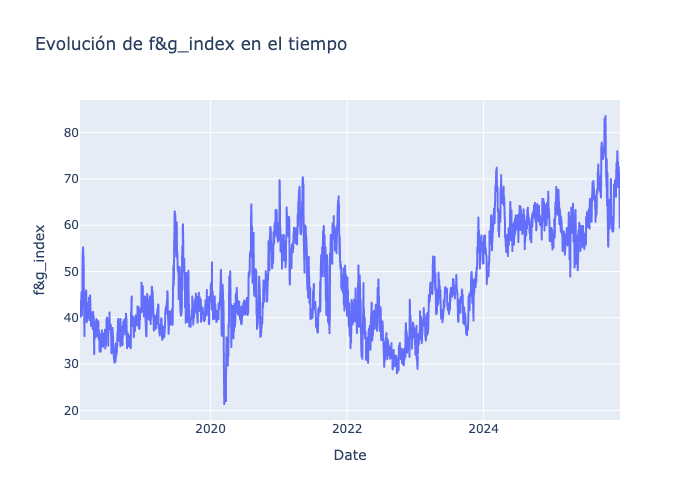

In [563]:
grafico(df_gold_transfer,"f&g_index")

In [564]:
# nuestro indicador solo pasa por debajo de 25 en 8 ocasiones con lo que no es suficientemente agresivo. Tendremos que escalar 
print("Numero de compras que va a realizar esta estrategia:",df_gold[df_gold_transfer["f&g_index"] < 25].shape[0])

Numero de compras que va a realizar esta estrategia: 6


In [567]:
# vamos a realizar MinMaxScaler para que el modelo se vuelva más agresivo y pase de las bandas de <25 y >75
scaler_gold_transfer = MinMaxScaler(feature_range=(0,100))
df_gold_transfer["f&g_index_norm"] = scaler_gold_transfer.fit_transform(df_gold_transfer[["f&g_index"]])
df_gold_transfer["f&g_index_norm"].head()

Date
2018-02-01    34.913647
2018-02-02    33.884747
2018-02-03    35.440563
2018-02-04    33.212307
2018-02-05    30.288670
Freq: D, Name: f&g_index_norm, dtype: float32

In [569]:
# ahora si que realiza las suficientes operaciones como para intentar implementar esta estrategia
print("Numero de compras que va a realizar esta estrategia:",df_gold[df_gold_transfer["f&g_index_norm"] < 25].shape[0])

Numero de compras que va a realizar esta estrategia: 421


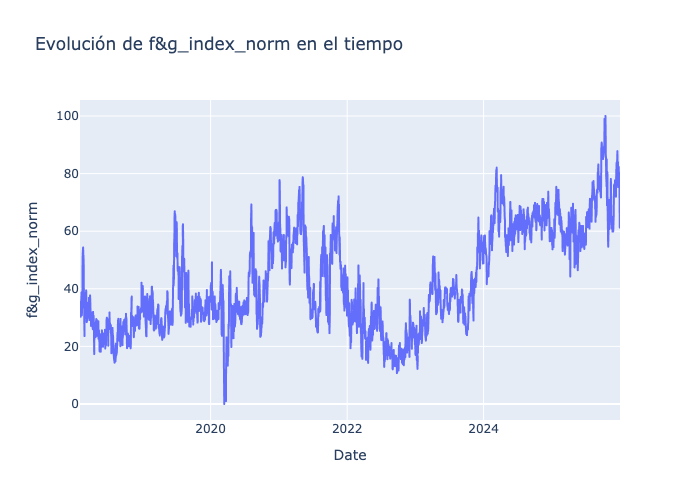

In [570]:
grafico(df_gold_transfer,"f&g_index_norm")

### COMPARACIÓN DE ESTRATEGIAS

#### DCA (2018-2026)

======================= DCA APLICADO EN GOLD ======================= 

La cantidad invertida por mes ha sido 105.26315789473684
El beneficio del Dollar Cost Average en el S&P500 es 14028.363
La rentabilidad es de 140.284%


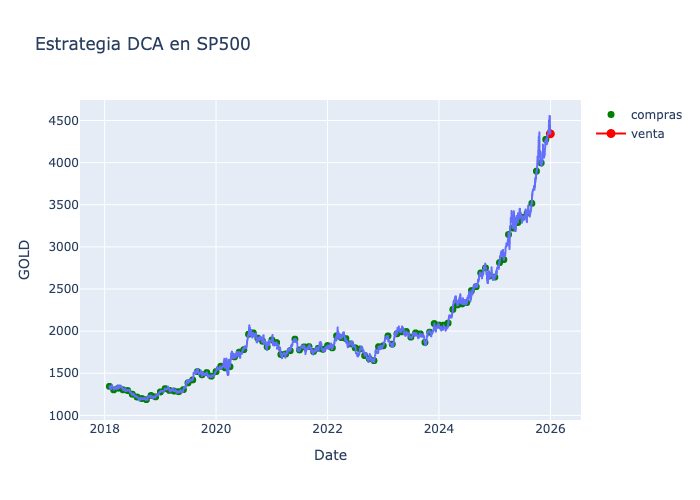

In [575]:
# creamos dataframe con las fechas de las compras
print("="*23, "DCA APLICADO EN GOLD", "="*23, "\n")
compras_mensuales_gold = df.resample("MS").first()
num_cuotas_2018 = len(compras_mensuales_gold)
cuota_gold_2018 = presupuesto / num_cuotas_2018
gold_acumulados_2018 = (cuota_gold_2018 / compras_mensuales_gold["GOLD"]).sum()
precio_final_gold = df.loc["2025-12-31","GOLD"]

valor_final_dca_gold_2018 = gold_acumulados_2018 * precio_final_gold
beneficio_dca_gold_2018 = valor_final_dca_gold_2018 - presupuesto
rentabilidad_dca_gold_2018 = beneficio_dca_gold_2018 / presupuesto * 100
print(f"La cantidad invertida por mes ha sido {cuota_gold_2018}")
print(f"El beneficio del Dollar Cost Average en el S&P500 es {beneficio_dca_gold_2018.round(3)}")
print(f"La rentabilidad es de {rentabilidad_dca_gold_2018.round(3)}%")

# representación visual
dca_gold_2018 = px.line(df, 
                  x = df.index, 
                  y = df["GOLD"], 
                  title = "Estrategia DCA en SP500")
dca_gold_2018.add_scatter(x = compras_mensuales_gold.index,
                    y = compras_mensuales_gold["GOLD"],
                    mode = "markers",
                    marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
dca_gold_2018.add_scatter(x = ["2025-12-31"],
                    y =  [precio_final_gold],
                    marker = dict(size = 9,
                                  color = "red",
                                  symbol = "circle"),
                                  name = "venta")
dca_gold_2018.show()

#### F&G CRYPTO

======================= INDICADOR FEAR & GREED CRYPTO EN GOLD ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 17.88908765652952
La cantidad de GOLD comprado ha sido de 6.01080819899332
El beneficio del Fear & Greed & Hold en GOLD es 16093.52
La rentabilidad es de 160.935%


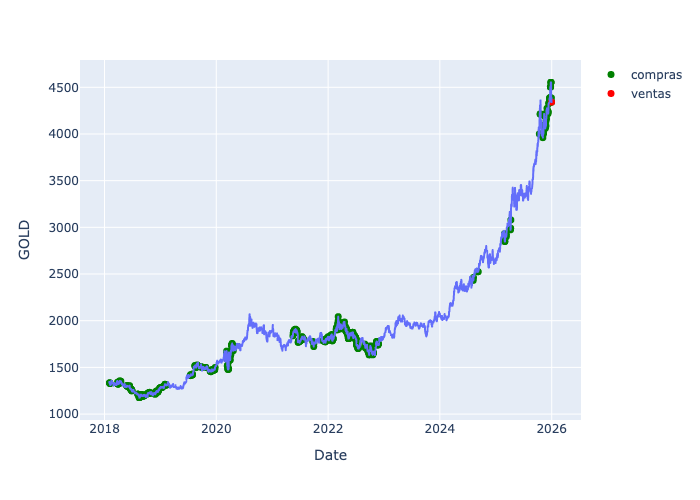

In [578]:
# 2. FEAR & GREED & HOLD (CRYPTO)
print("="*23, "INDICADOR FEAR & GREED CRYPTO EN GOLD", "="*23, "\n")
compras_gold_2018 = df[df["f&g_index"] < 25]
cant_compras_gold_2018 = df[df["f&g_index"] < 25].shape[0]
dinero_por_compra_gold_2018 = presupuesto / cant_compras_gold_2018
cantidad_gold_2018 = (dinero_por_compra_gold_2018 / compras_gold_2018["GOLD"]).sum()
beneficio_gold_2018 = df["GOLD"].loc["2025-12-31"] * cantidad_gold_2018 - presupuesto
rentabilidad_gold_2018 = (beneficio_gold_2018 / presupuesto) * 100
print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_gold_2018}")
print(f"La cantidad de GOLD comprado ha sido de {cantidad_gold_2018}")
print(f"El beneficio del Fear & Greed & Hold en GOLD es {beneficio_gold_2018.round(3)}")
print(f"La rentabilidad es de {rentabilidad_gold_2018.round(3)}%")


fig_gold_2018 = px.line(df,
                   x = df.index,
                   y = df["GOLD"])
fig_gold_2018.add_scatter( x = compras_gold_2018.index,
                      y = compras_gold_2018["GOLD"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_gold_2018.add_scatter( x = ["2025-12-31"],
                      y = [df["GOLD"].loc["2025-12-31"]],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_gold_2018.show()

#### BÚSQUEDA DE PARÁMETROS HEURÍSTICOS

======================= INDICADOR FEAR & GREED CON PARÁMETROS HEURÍSTICOS ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 270.27027027027026
La cantidad de GOLD comprado ha sido de 6.626055251766559
El beneficio del Fear & Greed & Hold en GOLD es 18764.369
La rentabilidad es de 187.644%


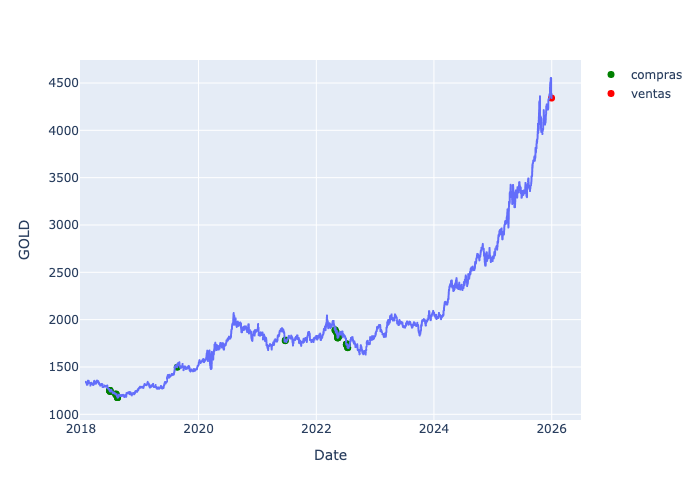

In [581]:
presupuesto = 10000
print("="*23, "INDICADOR FEAR & GREED CON PARÁMETROS HEURÍSTICOS", "="*23, "\n")
compras_gold_2018 = df_gold[df_gold_norm["f&g_index"] < 25]
cant_compras_gold_2018 = df_gold[df_gold_norm["f&g_index"] < 25].shape[0]
dinero_por_compra_gold_2018 = presupuesto / cant_compras_gold_2018
cantidad_gold_2018 = (dinero_por_compra_gold_2018 / compras_gold_2018["GOLD"]).sum()
beneficio_gold_2018 = df["GOLD"].loc["2025-12-31"] * cantidad_gold_2018 - presupuesto
rentabilidad_gold_2018 = (beneficio_gold_2018 / presupuesto) * 100
print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_gold_2018}")
print(f"La cantidad de GOLD comprado ha sido de {cantidad_gold_2018}")
print(f"El beneficio del Fear & Greed & Hold en GOLD es {beneficio_gold_2018.round(3)}")
print(f"La rentabilidad es de {rentabilidad_gold_2018.round(3)}%")


fig_gold_2018 = px.line(df_gold,
                   x = df_gold.index,
                   y = df_gold["GOLD"])
fig_gold_2018.add_scatter( x = compras_gold_2018.index,
                      y = compras_gold_2018["GOLD"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_gold_2018.add_scatter( x = ["2025-12-31"],
                      y = [df["GOLD"].loc["2025-12-31"]],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_gold_2018.show()

# Nuestro índice sintético del Fear % Greed en GOLD supera con creces al DCA y al fear & greed crypto

#### TRANSFER LEARNING

##### SIN ESCALAR

======================= INDICADOR FEAR & GREED MEDIANTE TRANSFER LEARNING SIN ESCALAR ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 1666.6666666666667
La cantidad de GOLD comprado ha sido de 6.606058428587348
El beneficio del Fear & Greed & Hold en GOLD es 18677.561
La rentabilidad es de 186.776%


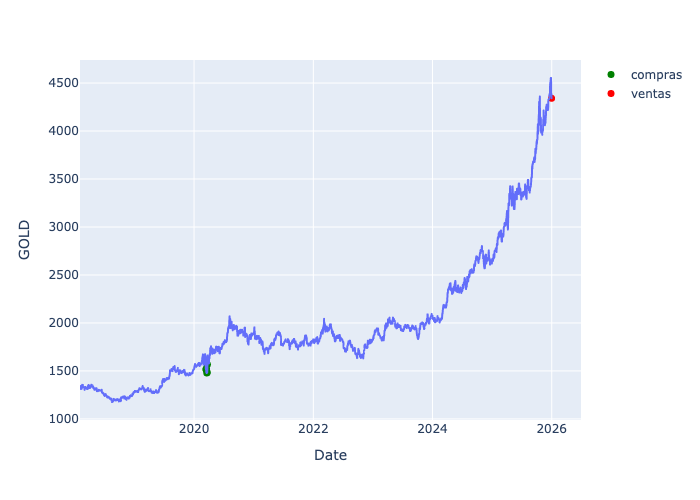

In [585]:
# Solo se realizan 2 operaciones por lo que se sube el baremo a 30
print("="*23, "INDICADOR FEAR & GREED MEDIANTE TRANSFER LEARNING SIN ESCALAR", "="*23, "\n")
compras_gold_transfer = df_gold[df_gold_transfer["f&g_index"] < 25]
cant_compras_gold_transfer = df_gold[df_gold_transfer["f&g_index"] < 25].shape[0]
dinero_por_compra_gold_transfer = presupuesto / cant_compras_gold_transfer
cantidad_gold_transfer = (dinero_por_compra_gold_transfer / compras_gold_transfer["GOLD"]).sum()
beneficio_gold_transfer = df["GOLD"].loc["2025-12-31"] * cantidad_gold_transfer - presupuesto
rentabilidad_gold_transfer = (beneficio_gold_transfer / presupuesto) * 100
print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_gold_transfer}")
print(f"La cantidad de GOLD comprado ha sido de {cantidad_gold_transfer}")
print(f"El beneficio del Fear & Greed & Hold en GOLD es {beneficio_gold_transfer.round(3)}")
print(f"La rentabilidad es de {rentabilidad_gold_transfer.round(3)}%")


fig_gold_transfer = px.line(df_gold,
                   x = df_gold.index,
                   y = df_gold["GOLD"])
fig_gold_transfer.add_scatter( x = compras_gold_transfer.index,
                      y = compras_gold_transfer["GOLD"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_gold_transfer.add_scatter( x = ["2025-12-31"],
                      y = [df["GOLD"].loc["2025-12-31"]],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_gold_transfer.show()


##### ESCALADO SUAVIZADO

======================= INDICADOR FEAR & GREED MEDIANTE TRANSFER LEARNING ESCALADA  ======================= 

La cantidad con la que se ha empezado es 10000€
La cantidad invertida por señal ha sido 23.752969121140143
La cantidad de GOLD comprado ha sido de 6.459946284253972
El beneficio del Fear & Greed & Hold en GOLD es 18043.273
La rentabilidad es de 180.433%


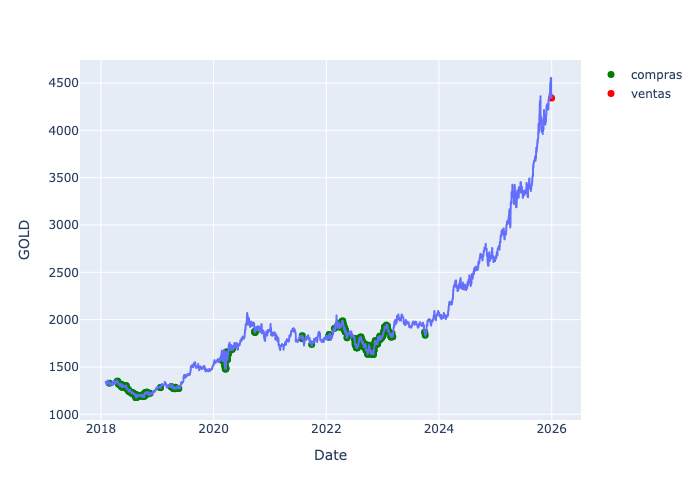

In [588]:
print("="*23, "INDICADOR FEAR & GREED MEDIANTE TRANSFER LEARNING ESCALADA ", "="*23, "\n")
compras_gold_transfer_norm = df_gold[df_gold_transfer["f&g_index_norm"] < 25]
cant_compras_gold_transfer_norm = df_gold[df_gold_transfer["f&g_index_norm"] < 25].shape[0]
dinero_por_compra_gold_transfer_norm = presupuesto / cant_compras_gold_transfer_norm
cantidad_gold_transfer_norm = (dinero_por_compra_gold_transfer_norm / compras_gold_transfer_norm["GOLD"]).sum()
beneficio_gold_transfer_norm = df["GOLD"].loc["2025-12-31"] * cantidad_gold_transfer_norm - presupuesto
rentabilidad_gold_transfer_norm = (beneficio_gold_transfer_norm / presupuesto) * 100
print(f"La cantidad con la que se ha empezado es {presupuesto}€")
print(f"La cantidad invertida por señal ha sido {dinero_por_compra_gold_transfer_norm}")
print(f"La cantidad de GOLD comprado ha sido de {cantidad_gold_transfer_norm}")
print(f"El beneficio del Fear & Greed & Hold en GOLD es {beneficio_gold_transfer_norm.round(3)}")
print(f"La rentabilidad es de {rentabilidad_gold_transfer_norm.round(3)}%")


fig_gold_transfer_norm = px.line(df_gold,
                   x = df_gold.index,
                   y = df_gold["GOLD"])
fig_gold_transfer_norm.add_scatter( x = compras_gold_transfer_norm.index,
                      y = compras_gold_transfer_norm["GOLD"],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "green",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "compras")
fig_gold_transfer_norm.add_scatter( x = ["2025-12-31"],
                      y = [df["GOLD"].loc["2025-12-31"]],
                      mode = "markers",
                      marker = dict(size = 7,
                                  color = "red",
                                  symbol = "circle",
                                  opacity = 1),
                                  name = "ventas")
                    
fig_gold_transfer_norm.show()